Partha Pratim Ray, 19 November, 2026

# Litchi leaf symptom recognition across independent image collections

Run the cells in order in Google Colab with a GPU runtime. The notebook downloads the
BDLitchi **original** archive and the supplied Rangamati V3 archive, creates manifests,
audits duplicate image families, trains two pretrained image classifiers, and evaluates
on held-out source images and the external collection. Grad-CAM follows evaluation.

The main task has four visually labelled conditions: healthy, insect damage, leaf blight,
and red rust. Matching category names is a provisional research assumption. In particular,
BDLitchi insect chewing is narrower than Rangamati insect damage. Have a plant pathologist
review that mapping before interpreting cross-collection results. The three-class
healthy/blight/red-rust analysis in Cell 20 is a prespecified sensitivity analysis.

These are image-level symptom labels. Neither a lesion mask nor pathogen identity can
be established from Grad-CAM. Near-duplicate grouping is a leakage safeguard, but missing
tree/leaf identifiers limit estimates of biological independence. Source folds group
similar images. The external collection supplies the independent collection test.

**Validation status of this deliverable** — cells were syntax checked and the non-GPU
manifest/splitting/metric logic was tested on synthetic fixtures. Full archive decoding,
pretrained weight downloads, training, and Grad-CAM require execution in Colab. No model
results or performance claims are supplied in advance.


### Cell 1 — Install supporting packages

Keep the PyTorch and torchvision versions supplied together by Colab. Install the image-audit and explanation packages, then record versions.


In [1]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'grad-cam>=1.5,<2', 'ImageHash>=4.3,<5', 'requests>=2.31',
    'scikit-learn>=1.4', 'pandas>=2.0', 'matplotlib>=3.8',
    'seaborn>=0.13', 'tqdm>=4.66', 'Pillow>=10'
])


0

### Cell 2 — Imports and reproducibility

Set random seeds, select the GPU, and record the actual package versions. Small numerical differences between GPU platforms can remain.


In [2]:
import copy
import hashlib
import importlib.metadata
import json
import math
import os
import random
import re
import shutil
import time
import unicodedata
import zipfile
from collections import Counter
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, log_loss
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
VERSIONS = {name: importlib.metadata.version(name) for name in
            ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn',
             'Pillow', 'ImageHash', 'grad-cam']}
print('Device', DEVICE)
print(json.dumps(VERSIONS, indent=2))
if DEVICE.type == 'cpu':
    print('CPU execution is available. Select a Colab GPU for practical training time.')


Device cuda
{
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "Pillow": "11.3.0",
  "ImageHash": "4.3.2",
  "grad-cam": "1.5.7"
}


### Cell 3 — Study configuration

The defaults run MobileNetV3-Small and EfficientNetV2-S. Both use established torchvision ImageNet weights. The external dataset is excluded from fitting, early stopping, calibration, and model selection.


In [3]:
ROOT = Path('/content/litchi_study') if Path('/content').exists() else Path.cwd() / 'litchi_study'
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
for folder in [DATA, OUT, OUT / 'figures', OUT / 'checkpoints']:
    folder.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'seed': SEED,
    'image_size': 224,
    'batch_size': 16,
    'workers': 2,
    'head_epochs': 2,
    'fine_tune_epochs': 12,
    'patience': 4,
    'learning_rate': 1e-4,
    'weight_decay': 1e-4,
    'phash_distance': 4,
    'confidence_threshold': 0.80,
    'models': ['mobilenet_v3_small', 'efficientnet_v2_s'],
}
CLASSES = ['healthy', 'insect_damage', 'leaf_blight', 'red_rust']
CLASS_TO_ID = {label: index for index, label in enumerate(CLASSES)}

# Original archive link verified against the Mendeley Version 1 file listing.
# Set to '' to resolve the URL from versioned metadata instead.
BDL_ORIGINAL_URL = (
    'https://data.mendeley.com/public-files/datasets/jhb24mszdk/files/'
    'a8bd3250-0cae-43cf-a458-ee5ae7c16ec0/file_downloaded'
)
BDL_ZIP = DATA / 'BDLitchi_original.zip'
RANGAMATI_URL = (
    'https://data.mendeley.com/public-files/datasets/94srbmydkw/files/'
    '3c9de669-bcd7-459f-b741-faa12bdb972a/file_downloaded'
)
RANGAMATI_ZIP = DATA / 'All_Fruits_Dataset_V3.zip'
ARCHIVE_SHA256 = {
    BDL_ZIP.name: 'dd4d6f7bef2cc5ad9c7a60ee4d7101b1f5089947be04677ca74420a03f107b6b',
    RANGAMATI_ZIP.name: '643153677f3beea42d57eb2d50461ba4716599953e37ffaf1adf1e0f70781348',
}

# The user-supplied BDLitchi link is to an augmented archive. Keep originals as input.
BDL_SUPPLIED_AUGMENTED_URL = (
    'https://data.mendeley.com/public-files/datasets/jhb24mszdk/files/'
    'da153182-9a30-4a26-9d16-8ed1434a6cb7/file_downloaded'
)
# Optional CSV columns: source, relative_path, origin_group. Use known original
# leaf/tree IDs if available. Blank means similarity-derived groups only.
ORIGIN_GROUP_CSV = ''

(OUT / 'config.json').write_text(json.dumps(CONFIG, indent=2))
(OUT / 'versions.json').write_text(json.dumps(VERSIONS, indent=2))
print('Workspace', ROOT)
print('Expected selected counts from repository descriptions: BDLitchi 4192; Rangamati 2774.')


Workspace /content/litchi_study
Expected selected counts from repository descriptions: BDLitchi 4192; Rangamati 2774.


### Cell 4 — Download the archives

Use the original Dataset.zip link verified against the versioned file listing. Downloads use a temporary file, deposited SHA-256 hashes, ZIP integrity checks, and an atomic rename. If a link fails, download the same archive from its landing page into the configured ZIP path. Allow roughly 25 GB free space for archives, extraction, and outputs. The 9.63 GB Rangamati archive contains all three crops.


In [4]:
session = requests.Session()
session.headers['User-Agent'] = 'LitchiResearchNotebook/1.0'

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def original_bdl_url():
    if BDL_ORIGINAL_URL:
        if BDL_ORIGINAL_URL == BDL_SUPPLIED_AUGMENTED_URL:
            raise ValueError('Set the original Dataset.zip URL in BDL_ORIGINAL_URL.')
        return BDL_ORIGINAL_URL
    api = 'https://data.mendeley.com/public-api/datasets/jhb24mszdk/files'
    response = session.get(api, params={'folder_id': 'root', 'version': 1}, timeout=(20, 90))
    response.raise_for_status()
    payload = response.json()
    records = payload if isinstance(payload, list) else payload.get('files', payload.get('data', []))
    matches = [item for item in records if item.get('filename', '').casefold() == 'dataset.zip']
    if len(matches) != 1:
        raise RuntimeError('Cannot uniquely resolve original Dataset.zip. Open https://data.mendeley.com/datasets/jhb24mszdk/1 and set BDL_ORIGINAL_URL.')
    item = matches[0]
    url = item.get('content_details', {}).get('download_url')
    if not url:
        raise RuntimeError('Original file download URL is missing from metadata. Set BDL_ORIGINAL_URL.')
    (OUT / 'bdl_original_record.json').write_text(json.dumps(item, indent=2))
    return url

def download_zip(url, destination):
    if destination.exists():
        if zipfile.is_zipfile(destination) and file_sha256(destination) == ARCHIVE_SHA256[destination.name]:
            print('Using existing archive', destination.name)
            return
        raise RuntimeError(f'Existing archive is invalid or has an unexpected checksum: {destination}')
    partial = destination.with_suffix('.zip.partial')
    for attempt in range(3):
        try:
            with session.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                size = int(response.headers.get('Content-Length', 0))
                with partial.open('wb') as handle, tqdm(total=size or None, unit='B', unit_scale=True, desc=destination.name) as bar:
                    for chunk in response.iter_content(1024 * 1024):
                        if chunk:
                            handle.write(chunk)
                            bar.update(len(chunk))
            if file_sha256(partial) != ARCHIVE_SHA256[destination.name]:
                raise RuntimeError('Archive checksum differs from the deposited file listing.')
            with zipfile.ZipFile(partial) as archive:
                bad_file = archive.testzip()
                if bad_file:
                    raise RuntimeError(f'CRC check failed for {bad_file}')
            os.replace(partial, destination)
            return
        except (requests.RequestException, zipfile.BadZipFile, RuntimeError):
            partial.unlink(missing_ok=True)
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)

if not BDL_ZIP.exists():
    download_zip(original_bdl_url(), BDL_ZIP)
else:
    download_zip('', BDL_ZIP)
download_zip(RANGAMATI_URL, RANGAMATI_ZIP)


BDLitchi_original.zip:   0%|          | 0.00/549M [00:00<?, ?B/s]

All_Fruits_Dataset_V3.zip:   0%|          | 0.00/10.3G [00:00<?, ?B/s]

### Cell 5 — Inspect and extract image files

Print archive paths first. Extraction retains the relative folder structure and skips macOS metadata. Only lychee images are extracted from Rangamati. A completion marker is written after extraction finishes. Confirm the displayed folders identify the intended crop and classes.


In [5]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def normalize(text):
    text = unicodedata.normalize('NFKC', str(text)).casefold()
    return re.sub(r'[^a-z0-9]+', ' ', text).strip()

def is_lychee_path(name):
    return any('lychee' in normalize(part) or 'litchi' in normalize(part)
               for part in Path(name).parts[:-1])

def extract_images(archive_path, target, lychee_only=False):
    target.mkdir(parents=True, exist_ok=True)
    marker = target / '_extraction_complete.json'
    identity = {'archive': archive_path.name, 'size': archive_path.stat().st_size,
                'lychee_only': lychee_only}
    if marker.exists() and json.loads(marker.read_text()) == identity:
        return target
    with zipfile.ZipFile(archive_path) as archive:
        candidates = [item for item in archive.infolist()
                      if Path(item.filename).suffix.casefold() in IMAGE_EXTENSIONS
                      and '__MACOSX' not in item.filename and not Path(item.filename).name.startswith('._')]
        print(archive_path.name, 'image members', len(candidates))
        print('\n'.join(item.filename for item in candidates[:12]))
        members = [item for item in candidates if not lychee_only or is_lychee_path(item.filename)]
        if not members:
            raise RuntimeError('No selected image members found. Inspect ZIP folder names and adjust is_lychee_path.')
        for item in tqdm(members, desc='Extracting ' + target.name):
            destination = (target / item.filename).resolve()
            if not destination.is_relative_to(target.resolve()):
                raise ValueError('Unsafe ZIP member path')
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(item) as source, destination.open('wb') as sink:
                shutil.copyfileobj(source, sink)
    marker.write_text(json.dumps(identity))
    return target

BDL_ROOT = extract_images(BDL_ZIP, DATA / 'bdl_original')
RANGAMATI_ROOT = extract_images(RANGAMATI_ZIP, DATA / 'rangamati', lychee_only=True)


BDLitchi_original.zip image members 11094
Dataset/Black Spot/IMG20250601101600.jpg
Dataset/Black Spot/IMG20250601101612.jpg
Dataset/Black Spot/IMG20250601101626.jpg
Dataset/Black Spot/IMG20250601101635.jpg
Dataset/Black Spot/IMG20250601101759.jpg
Dataset/Black Spot/IMG20250601101808.jpg
Dataset/Black Spot/IMG20250601101813.jpg
Dataset/Black Spot/IMG20250601101819.jpg
Dataset/Black Spot/IMG20250601101839.jpg
Dataset/Black Spot/IMG20250601101920.jpg
Dataset/Black Spot/IMG20250601101937.jpg
Dataset/Black Spot/IMG20250601101949.jpg


Extracting bdl_original:   0%|          | 0/11094 [00:00<?, ?it/s]

All_Fruits_Dataset_V3.zip image members 15062
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1024.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1025.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1026.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1030.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1042.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1043.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1044.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1047.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1049.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1050.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1075.jpg
All_Fruits/Jackfruits/Algal_Leaf_Spot/Jackfruit1077.jpg


Extracting rangamati:   0%|          | 0/5445 [00:00<?, ?it/s]

### Cell 6 — Build manifests using explicit class names

Match complete normalized folder names. Keep unmatched categories in a separate manifest. Leaf spot, black spot, and mixed blight/anthracnose are not silently merged. The insect mapping remains provisional and receives a sensitivity analysis later.


In [6]:
SOURCE_ALIASES = {
    'healthy': ['Healthy Leaf', 'Healthy Leaves'],
    'insect_damage': ['Insect Chewing Damage'],
    'leaf_blight': ['Leaf Blight Disease', 'Leaf Blight'],
    'red_rust': ['Red Rust Disease', 'Red Rust'],
}
EXTERNAL_ALIASES = {
    'healthy': [
        'Healthy Leaves',
        'Healthy Leaf',
    ],
    'insect_damage': [
        'Insect Damage',
        'Inspact Damage',  # Matches the actual folder: Inspact_Damage
    ],
    'leaf_blight': [
        'Leaf Blight',
    ],
    'red_rust': [
        'Red Rust',
    ],
}
def build_manifest(root, source, aliases):
    lookup = {normalize(alias): label for label, values in aliases.items() for alias in values}
    rows = []
    for path in sorted(root.rglob('*')):
        if path.suffix.casefold() not in IMAGE_EXTENSIONS:
            continue
        relative = path.relative_to(root)
        folder_names = [normalize(part) for part in relative.parts[:-1]]
        matches = {lookup[name] for name in folder_names if name in lookup}
        if len(matches) > 1:
            raise ValueError(f'Ambiguous category folders: {relative}')
        label = next(iter(matches)) if matches else None
        rows.append({'path': str(path), 'relative_path': str(relative), 'source': source,
                     'folder_label': path.parent.name, 'label': label})
    result = pd.DataFrame(rows)
    if result.empty:
        raise ValueError(f'No images found under {root}')
    return result

all_source = build_manifest(BDL_ROOT, 'BDLitchi', SOURCE_ALIASES)
all_external = build_manifest(RANGAMATI_ROOT, 'RangamatiV3', EXTERNAL_ALIASES)
all_images = pd.concat([all_source, all_external], ignore_index=True)
all_images.to_csv(OUT / 'inventory_all_classes.csv', index=False)
display(all_images.groupby(['source', 'folder_label'], dropna=False).size().rename('images').to_frame())
selected = all_images[all_images.label.notna()].copy().reset_index(drop=True)
for source in ['BDLitchi', 'RangamatiV3']:
    if set(selected.loc[selected.source.eq(source), 'label']) != set(CLASSES):
        raise ValueError(f'Expected all four classes for {source}. Inspect folders and exact aliases above.')
display(pd.crosstab(selected.label, selected.source))
(OUT / 'class_mapping.json').write_text(json.dumps({'source': SOURCE_ALIASES, 'external': EXTERNAL_ALIASES}, indent=2))


images
source      folder_label                   
BDLitchi    Black Spot                 1045
            Burned Leaf                1171
            Dried Leaf                  934
            Fungal Stripe Damage        922
            Healthy Leaf                988
            Insect Chewing Damage      1160
            Leaf Blight Disease         965
            Pest-Affected Dry Leaf      879
            Red Rust Disease           1079
            White Spot                  877
            Yellow Mosaic Virus        1074
RangamatiV3 Anthracnose                 555
            Dieback                     380
            Healthy_Leaves              786
            Inspact_Damage             1739
            Leaf_Blight                  90
            Leaf_Blight&Anthracnose      76
            Leaf_Curl&Erinose_Mite      685
            Leaf_Curl&Sooty_Mold         54
            Leaf_Spot                   575
            Red_Rust                    159
            Sooty_Mold                  346

source,BDLitchi,RangamatiV3
label,,
healthy,988,786
insect_damage,1160,1739
leaf_blight,965,90
red_rust,1079,159


549

### Cell 7 — Inspect sample images

Review symptoms, crop identity, backgrounds, and labels before training. Published class counts are inventory expectations, not a substitute for this image review.


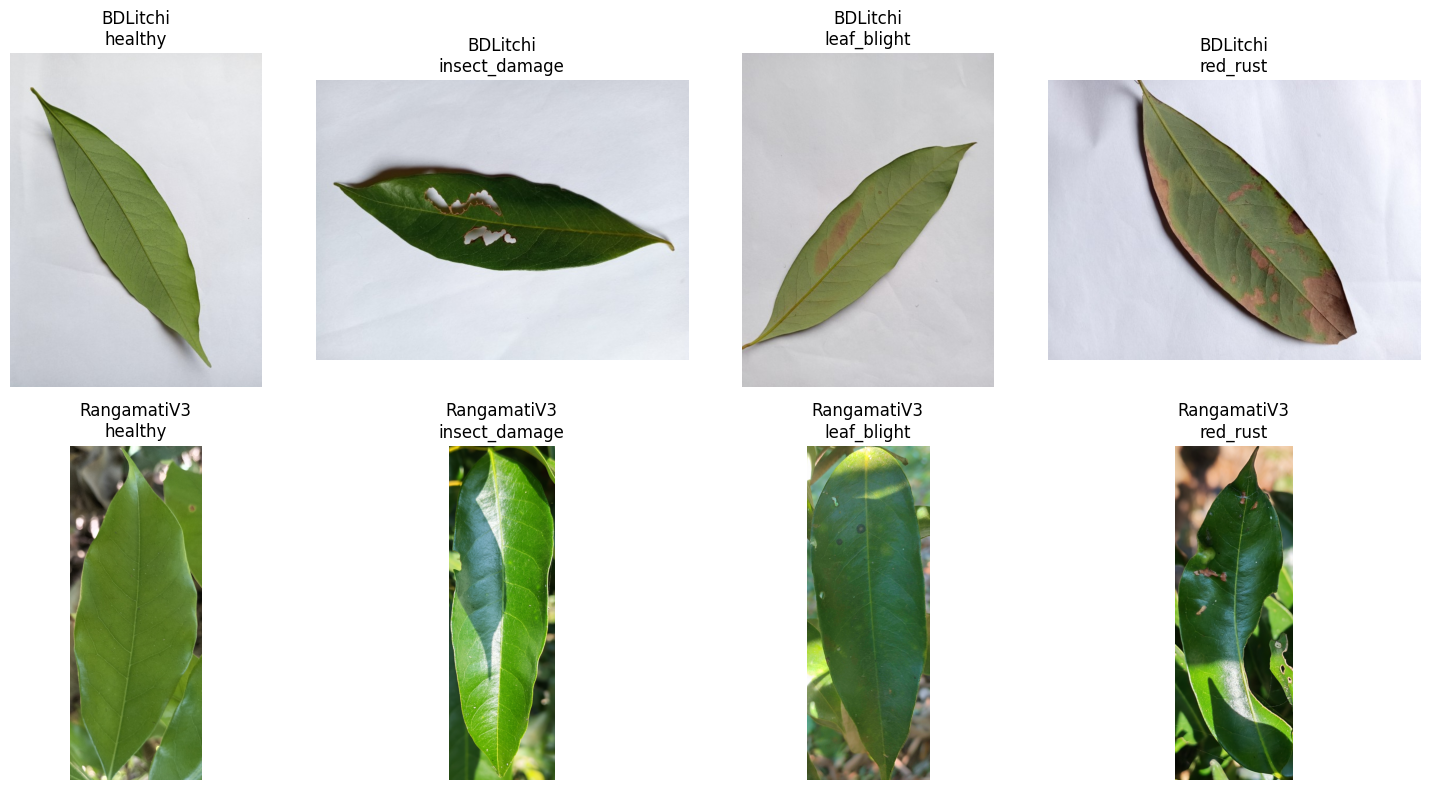

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for row_index, source in enumerate(['BDLitchi', 'RangamatiV3']):
    for column, label in enumerate(CLASSES):
        sample = selected[selected.source.eq(source) & selected.label.eq(label)].sample(1, random_state=SEED).iloc[0]
        with Image.open(sample.path) as image:
            axes[row_index, column].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row_index, column].set_title(source + '\n' + label)
        axes[row_index, column].axis('off')
plt.tight_layout()
plt.savefig(OUT / 'figures' / 'dataset_examples.png', dpi=600, bbox_inches='tight')
plt.show()


In [8]:
# More images — 600 DPI

import math

# Configure 600 DPI for Google Colab display and saving
%config InlineBackend.figure_format = 'png'
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600

FIGURE_DIR = OUT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DISPLAY_NAMES = {
    "Inspact_Damage": "Insect Damage",
}

for source in ["BDLitchi", "RangamatiV3"]:

    # all_images includes every class, including those outside CLASSES.
    source_images = all_images[
        all_images["source"].eq(source)
    ].copy()

    class_names = sorted(
        source_images["folder_label"].unique()
    )

    ncols = 4
    nrows = math.ceil(len(class_names) / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(12, 3 * nrows),
        squeeze=False,
        constrained_layout=True
    )

    for index, folder_label in enumerate(class_names):

        axis = axes.flat[index]

        candidates = source_images[
            source_images["folder_label"].eq(folder_label)
        ].sort_values("path")

        sample = candidates.sample(
            n=1,
            random_state=SEED
        ).iloc[0]

        with Image.open(sample["path"]) as image:
            axis.imshow(
                ImageOps.exif_transpose(image).convert("RGB")
            )

        display_label = DISPLAY_NAMES.get(
            folder_label,
            folder_label.replace("_", " ").replace("&", " & ")
        )

        axis.set_title(
            f"({chr(97 + index)}) {display_label}",
            fontsize=10,
            pad=5
        )
        axis.axis("off")

    # Hide unused panels.
    for index in range(len(class_names), nrows * ncols):
        axes.flat[index].axis("off")

    fig.suptitle(
        source,
        fontsize=14,
        fontweight="bold"
    )

    # Save figures at 600 DPI in PNG and PDF formats
    for extension in ["png", "pdf"]:
        fig.savefig(
            FIGURE_DIR / f"{source}_all_class_examples.{extension}",
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )

    # Display figure in Google Colab
    plt.show()
    plt.close(fig)

Output hidden; open in https://colab.research.google.com to view.

### Cell 8 — Decode and fingerprint every selected image

Record file hashes, orientation-corrected pixel hashes, dimensions, and 64-bit perceptual hashes. Identical decoded images are detected even when file metadata differs. Failed images are listed and excluded transparently.


In [9]:
audit_rows = []
for row in tqdm(selected.itertuples(index=False), total=len(selected), desc='Auditing selected images'):
    record = row._asdict()
    try:
        file_hash = hashlib.sha256(Path(row.path).read_bytes()).hexdigest()
        with Image.open(row.path) as image:
            rgb = ImageOps.exif_transpose(image).convert('RGB')
            rgb.load()
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            record.update(width=rgb.width, height=rgb.height, file_sha256=file_hash,
                          pixel_sha256=digest, phash=str(imagehash.phash(rgb, hash_size=8)), error='')
    except Exception as error:
        record['error'] = str(error)
    audit_rows.append(record)
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT / 'image_audit.csv', index=False)
print('Failed decodes', audit.error.ne('').sum())
valid = audit[audit.error.eq('')].copy().reset_index(drop=True)
display(valid.groupby('source')[['width', 'height']].describe())


Auditing selected images:   0%|          | 0/6966 [00:00<?, ?it/s]

Failed decodes 0


width                                                           \
              count         mean         std    min     25%     50%      75%   
source                                                                         
BDLitchi     4192.0   582.895992   75.308263  480.0   480.0   638.0   638.00   
RangamatiV3  2774.0  1780.189618  925.041715  240.0  1146.0  1398.0  2298.25   

                     height                                                    \
                max   count         mean          std    min      25%     50%   
source                                                                          
BDLitchi      638.0  4192.0   535.104008    75.308263  480.0   480.00   480.0   
RangamatiV3  4096.0  2774.0  2436.077866  1029.194289  430.0  1394.25  2516.0   

                              
                 75%     max  
source                        
BDLitchi      638.00   638.0  
RangamatiV3  3391.75  4096.0

### Cell 9 — Group duplicate image families and remove overlap

Join exact duplicates and conservative perceptual neighbours into components. Optional leaf/tree IDs also join related records. Quarantine components with conflicting labels. Remove source components touching the external collection, preserving external evaluation. Review the saved near-duplicate pairs because visual similarity can join different leaves. Camera/tree identities cannot be reconstructed reliably from hashes.


In [10]:
parent = list(range(len(valid)))

def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(left, right):
    left, right = find(left), find(right)
    if left != right:
        parent[right] = left

for column in ['file_sha256', 'pixel_sha256']:
    for indices in valid.groupby(column).groups.values():
        indices = list(indices)
        for other in indices[1:]:
            union(indices[0], other)

bits = np.array([[int(bit) for bit in format(int(value, 16), '064b')]
                 for value in valid.phash], dtype=np.uint8)
neighbours = NearestNeighbors(radius=(CONFIG['phash_distance'] + 0.01) / 64,
                              algorithm='ball_tree', metric='hamming').fit(bits)
distances, neighbour_ids = neighbours.radius_neighbors(bits)
pairs = []
for left, (local_distances, local_ids) in enumerate(zip(distances, neighbour_ids)):
    for distance, right in zip(local_distances, local_ids):
        right = int(right)
        if right > left:
            union(left, right)
            pairs.append({'left': valid.loc[left, 'path'], 'right': valid.loc[right, 'path'],
                          'hamming_distance': round(float(distance) * 64)})
pd.DataFrame(pairs, columns=['left', 'right', 'hamming_distance']).to_csv(OUT / 'similar_image_pairs.csv', index=False)

if ORIGIN_GROUP_CSV:
    supplied = pd.read_csv(ORIGIN_GROUP_CSV, dtype=str)
    keys = ['source', 'relative_path']
    if supplied.duplicated(keys).any():
        raise ValueError('Origin-group CSV has duplicate image keys')
    valid = valid.merge(supplied[keys + ['origin_group']], on=keys, how='left', validate='one_to_one')
    for indices in valid.dropna(subset=['origin_group']).groupby(['source', 'origin_group']).groups.values():
        indices = list(indices)
        for other in indices[1:]:
            union(indices[0], other)

valid['group'] = [f'family_{find(index):06d}' for index in range(len(valid))]
conflicting = set(valid.groupby('group').label.nunique().loc[lambda counts: counts > 1].index)
valid['excluded_reason'] = np.where(valid.group.isin(conflicting), 'conflicting labels within similarity/origin group', '')
external_groups = set(valid.loc[valid.source.eq('RangamatiV3'), 'group'])
overlap = valid.source.eq('BDLitchi') & valid.group.isin(external_groups)
valid.loc[overlap, 'excluded_reason'] = 'source family overlaps external collection'

# Within each domain retain one decoded-pixel copy; source and external are never merged.
duplicates = valid.duplicated(['source', 'pixel_sha256'], keep='first')
valid.loc[duplicates & valid.excluded_reason.eq(''), 'excluded_reason'] = 'repeated decoded pixels'
valid.to_csv(OUT / 'duplicate_decisions.csv', index=False)
clean = valid[valid.excluded_reason.eq('')].copy().reset_index(drop=True)
source_df = clean[clean.source.eq('BDLitchi')].copy().reset_index(drop=True)
external_df = clean[clean.source.eq('RangamatiV3')].copy().reset_index(drop=True)
print('Similarity pairs', len(pairs), '| conflicting families', len(conflicting))
display(pd.crosstab(clean.label, clean.source))
if len(external_df) == 0 or len(source_df) == 0:
    raise ValueError('No usable source or external images remain after the audit.')


Similarity pairs 16025 | conflicting families 32


source,BDLitchi,RangamatiV3
label,,
healthy,547,786
insect_damage,1040,1739
leaf_blight,753,90
red_rust,872,159


### Cell 10 — Create reproducible grouped source splits

Approximately 64% of source images train the model, 16% validate it, and 20% form the internal test. Exact proportions vary with image-family sizes. The external set has its own fixed manifest. If too few independent groups remain, the cell stops instead of falling back to a random image split.


In [11]:
def split_once(frame, seed):
    group_counts = frame.groupby('label').group.nunique()
    if group_counts.min() < 5:
        raise ValueError('At least five independent groups per class are needed for this split.')
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    train_ids, holdout_ids = next(splitter.split(frame, frame.label, frame.group))
    return frame.iloc[train_ids].copy(), frame.iloc[holdout_ids].copy()

trainval_df, test_df = split_once(source_df, SEED)
train_df, val_df = split_once(trainval_df.reset_index(drop=True), SEED + 1)
SPLITS = {'train': train_df, 'validation': val_df, 'internal_test': test_df,
          'external_test': external_df}
for name, frame in SPLITS.items():
    if set(frame.label) != set(CLASSES):
        raise ValueError(f'{name} does not contain all four categories. Inspect grouping before training.')
    frame['target'] = frame.label.map(CLASS_TO_ID)
    frame.to_csv(OUT / f'manifest_{name}.csv', index=False)
for left, left_frame in SPLITS.items():
    for right, right_frame in SPLITS.items():
        if left < right:
            assert set(left_frame.group).isdisjoint(right_frame.group), (left, right)
display(pd.DataFrame({name: frame.label.value_counts() for name, frame in SPLITS.items()}).fillna(0).astype(int))
manifest_blob = ''.join(frame.sort_values('path')[['relative_path', 'pixel_sha256', 'group', 'label']].to_csv(index=False)
                        for frame in SPLITS.values())
MANIFEST_SHA256 = hashlib.sha256(manifest_blob.encode()).hexdigest()
(OUT / 'manifest_sha256.txt').write_text(MANIFEST_SHA256)
print('Image-family grouping does not establish tree-level independence when tree IDs are missing.')


,train,validation,internal_test,external_test
label,,,,
healthy,417,52,78,786
insect_damage,680,164,196,1739
leaf_blight,509,106,138,90
red_rust,550,134,188,159


Image-family grouping does not establish tree-level independence when tree IDs are missing.


### Cell 11 — Prepare training and evaluation transforms

Apply random augmentation only when a training image is loaded. Use the same deterministic letterbox resize for validation, testing, and explanations. Padding preserves the original leaf shape. Both selected torchvision weight sets use ImageNet normalization.


In [12]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
PADDING = tuple(round(value * 255) for value in MEAN)

class Letterbox:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        image = ImageOps.contain(image, (self.size, self.size), method=Image.Resampling.BILINEAR)
        canvas = Image.new('RGB', (self.size, self.size), PADDING)
        canvas.paste(image, ((self.size - image.width) // 2, (self.size - image.height) // 2))
        return canvas

letterbox = Letterbox(CONFIG['image_size'])
train_transform = transforms.Compose([
    letterbox,
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(12, fill=PADDING),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)
])
eval_transform = transforms.Compose([letterbox, transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class LeafDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
            tensor = self.transform(image)
        return tensor, int(row.target)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(frame, training=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(LeafDataset(frame, train_transform if training else eval_transform),
                      batch_size=CONFIG['batch_size'], shuffle=training,
                      num_workers=CONFIG['workers'], pin_memory=DEVICE.type == 'cuda',
                      worker_init_fn=seed_worker, generator=generator)

loaders = {name: make_loader(frame, training=name == 'train') for name, frame in SPLITS.items()}
batch_images, batch_targets = next(iter(loaders['train']))
print('Batch', batch_images.shape, batch_targets.shape)


Batch torch.Size([16, 3, 224, 224]) torch.Size([16])


### Cell 12 — Construct pretrained models

Replace the ImageNet classifier with a four-category head. The feature extractor is initially frozen, then all layers are fine-tuned. Model choice is made using source validation macro-F1.


In [13]:
def build_model(name, pretrained=True):
    if name == 'mobilenet_v3_small':
        weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v3_small(weights=weights)
    elif name == 'efficientnet_v2_s':
        weights = models.EfficientNet_V2_S_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_v2_s(weights=weights)
    else:
        raise ValueError(name)
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASSES))
    return model.to(DEVICE)

counts = train_df.target.value_counts().reindex(range(len(CLASSES))).to_numpy()
class_weights = torch.tensor(len(train_df) / (len(CLASSES) * counts), dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
print('Training-set class weights', class_weights.cpu().numpy())


Training-set class weights [1.292566   0.79264706 1.0589391  0.98      ]


### Cell 13 — Training and validation functions

Use mixed precision on the GPU, warm up the classifier head, then fine-tune. Early stopping and best-checkpoint selection use only source validation. Batch-normalization statistics stay fixed during the frozen-head stage.


In [14]:
def train_epoch(model, loader, optimizer, scaler, frozen_backbone):
    model.train()
    if frozen_backbone:
        model.features.eval()
    total_loss = 0.0
    for images, targets in tqdm(loader, leave=False, desc='Training'):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
            logits = model(images)
            loss = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(images)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    predictions, targets_all = [], []
    for images, targets in loader:
        predictions.append(model(images.to(DEVICE)).float().cpu().numpy())
        targets_all.append(targets.numpy())
    return np.concatenate(predictions), np.concatenate(targets_all)

def fit_model(name):
    torch.manual_seed(SEED)
    model = build_model(name)
    for parameter in model.features.parameters():
        parameter.requires_grad = False
    optimizer = torch.optim.AdamW(filter(lambda parameter: parameter.requires_grad, model.parameters()),
                                  lr=1e-3, weight_decay=CONFIG['weight_decay'])
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda')
    best_f1, bad_epochs, history = -1.0, 0, []
    checkpoint = OUT / 'checkpoints' / f'{name}.pt'
    epochs = CONFIG['head_epochs'] + CONFIG['fine_tune_epochs']
    for epoch in range(epochs):
        if epoch == CONFIG['head_epochs']:
            for parameter in model.parameters():
                parameter.requires_grad = True
            optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['learning_rate'],
                                          weight_decay=CONFIG['weight_decay'])
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['fine_tune_epochs'])
            bad_epochs = 0
        frozen = epoch < CONFIG['head_epochs']
        training_loss = train_epoch(model, loaders['train'], optimizer, scaler, frozen)
        logits, labels = collect_logits(model, loaders['validation'])
        score = f1_score(labels, logits.argmax(1), average='macro', labels=range(len(CLASSES)), zero_division=0)
        record = {'epoch': epoch + 1, 'phase': 'head' if frozen else 'fine_tune',
                  'train_loss': training_loss, 'validation_macro_f1': float(score)}
        history.append(record)
        print(name, record)
        if score > best_f1:
            best_f1, bad_epochs = float(score), 0
            torch.save({'state_dict': {key: value.detach().cpu() for key, value in model.state_dict().items()},
                        'model_name': name, 'classes': CLASSES, 'config': CONFIG,
                        'manifest_sha256': MANIFEST_SHA256, 'validation_macro_f1': best_f1,
                        'epoch': epoch + 1}, checkpoint)
        elif not frozen:
            bad_epochs += 1
        if not frozen:
            scheduler.step()
            if bad_epochs >= CONFIG['patience']:
                break
    pd.DataFrame(history).to_csv(OUT / f'training_{name}.csv', index=False)
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return {'model': name, 'validation_macro_f1': best_f1, 'checkpoint': str(checkpoint)}


### Cell 14 — Train and select using source validation

This is the main GPU cell. Existing checkpoints are reusable only when their configuration, class order, and data-manifest fingerprint match. Set REUSE_CHECKPOINTS=False to retrain from the same configuration.


In [15]:
REUSE_CHECKPOINTS = True
model_records = []
for name in CONFIG['models']:
    checkpoint = OUT / 'checkpoints' / f'{name}.pt'
    if REUSE_CHECKPOINTS and checkpoint.exists():
        # This file is created by this notebook in the current workspace.
        saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
        if saved['config'] != CONFIG or saved['manifest_sha256'] != MANIFEST_SHA256 or saved['classes'] != CLASSES:
            raise RuntimeError(f'Checkpoint settings changed: {checkpoint}. Use a new output directory or retrain explicitly.')
        model_records.append({'model': name, 'validation_macro_f1': saved['validation_macro_f1'],
                              'checkpoint': str(checkpoint)})
    else:
        model_records.append(fit_model(name))
selection = pd.DataFrame(model_records).sort_values('validation_macro_f1', ascending=False).reset_index(drop=True)
selection.to_csv(OUT / 'model_selection_source_validation.csv', index=False)
BEST_NAME = selection.iloc[0]['model']
display(selection)
print('Selected using source validation only', BEST_NAME)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 205MB/s]


Training:   0%|          | 0/135 [00:00<?, ?it/s]

mobilenet_v3_small {'epoch': 1, 'phase': 'head', 'train_loss': 0.19655292057509988, 'validation_macro_f1': 0.9765254041365082}


Training:   0%|          | 0/135 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0d0a5eb4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0d0a5eb4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (45 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0d0a5eb4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0d0a5eb4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

efficientnet_v2_s {'epoch': 9, 'phase': 'fine_tune', 'train_loss': 0.005671326906815825, 'validation_macro_f1': 1.0}


,model,validation_macro_f1,checkpoint
0,mobilenet_v3_small,1.0,/content/litchi_study/outputs/checkpoints/mobi...
1,efficientnet_v2_s,1.0,/content/litchi_study/outputs/checkpoints/effi...


Selected using source validation only mobilenet_v3_small


In [16]:
# Rebuild evaluation loaders using the main process.
for split_name in [
    "validation",
    "internal_test",
    "external_test",
]:
    loaders[split_name] = DataLoader(
        LeafDataset(
            SPLITS[split_name],
            eval_transform
        ),
        batch_size=CONFIG["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )

# Record the execution adjustment alongside the experiment outputs.
(OUT / "evaluation_loader_settings.json").write_text(
    json.dumps(
        {
            "num_workers": 0,
            "reason": "Multiprocessing worker cleanup errors"
        },
        indent=2
    )
)

print("Evaluation loaders rebuilt with num_workers=0.")
print("Selected model:", BEST_NAME)

Evaluation loaders rebuilt with num_workers=0.
Selected model: mobilenet_v3_small


### Cell 15 — Plot learning curves

Inspect loss and source-validation macro-F1. A gap between training behaviour and external results later can reveal collection dependence.


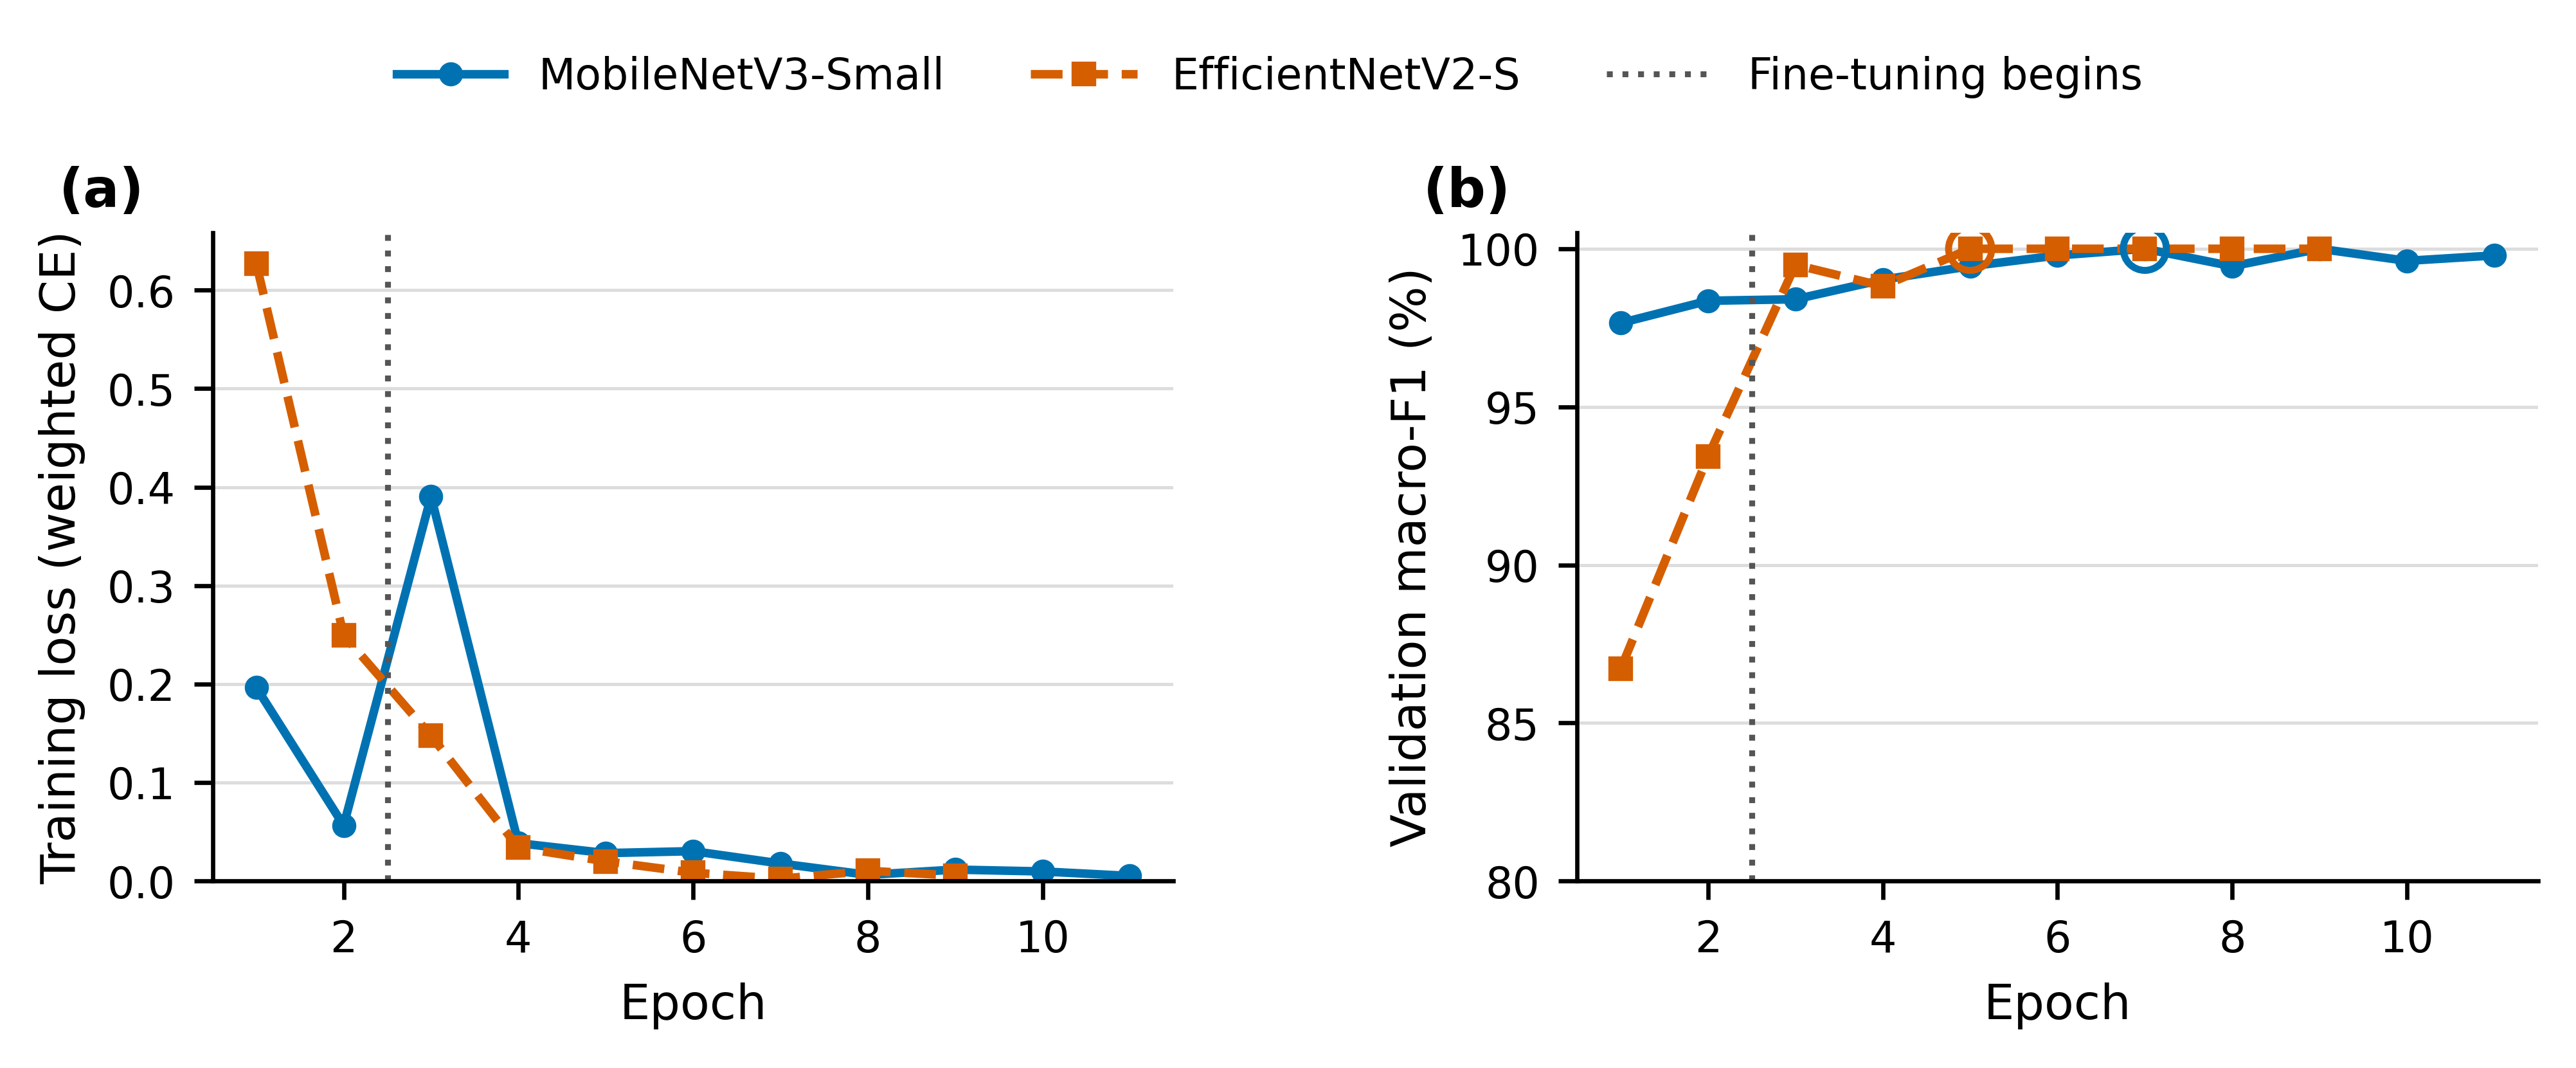

,model,epochs_completed,best_validation_epoch,best_validation_macro_f1,training_loss_at_best_epoch
0,mobilenet_v3_small,11,7,1.0,0.01788
1,efficientnet_v2_s,9,5,1.0,0.02012


In [17]:
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# Configure Google Colab inline display
%config InlineBackend.figure_format = 'png'

FIGURE_DIR = OUT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_STYLES = {
    "mobilenet_v3_small": {
        "label": "MobileNetV3-Small",
        "color": "#0072B2",
        "linestyle": "-",
        "marker": "o",
    },
    "efficientnet_v2_s": {
        "label": "EfficientNetV2-S",
        "color": "#D55E00",
        "linestyle": "--",
        "marker": "s",
    },
}

histories = {}
summary_rows = []

for name in CONFIG["models"]:

    path = OUT / f"training_{name}.csv"

    if not path.exists():
        raise FileNotFoundError(
            f"Training history is unavailable: {path}"
        )

    history = pd.read_csv(path).sort_values("epoch")

    required_columns = {
        "epoch",
        "train_loss",
        "validation_macro_f1",
    }

    missing = required_columns.difference(history.columns)

    if missing:
        raise ValueError(
            f"{name}: missing history columns {sorted(missing)}"
        )

    histories[name] = history

    # idxmax selects the first epoch attaining the best score.
    best_row = history.loc[
        history["validation_macro_f1"].idxmax()
    ]

    summary_rows.append({
        "model": name,
        "epochs_completed": int(history["epoch"].max()),
        "best_validation_epoch": int(best_row["epoch"]),
        "best_validation_macro_f1": float(
            best_row["validation_macro_f1"]
        ),
        "training_loss_at_best_epoch": float(
            best_row["train_loss"]
        ),
    })

training_summary = pd.DataFrame(summary_rows)

training_summary.to_csv(
    OUT / "training_summary.csv",
    index=False
)

plot_style = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    # 600 DPI for rendering and Colab display
    "figure.dpi": 600,

    # 600 DPI for saved figures
    "savefig.dpi": 600,
}

with mpl.rc_context(plot_style):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(174 / 25.4, 2.8)
    )

    legend_handles = []

    for name, history in histories.items():

        style = MODEL_STYLES[name]

        line_options = {
            "color": style["color"],
            "linestyle": style["linestyle"],
            "marker": style["marker"],
            "linewidth": 1.6,
            "markersize": 3.5,
        }

        axes[0].plot(
            history["epoch"],
            history["train_loss"],
            **line_options
        )

        axes[1].plot(
            history["epoch"],
            100 * history["validation_macro_f1"],
            **line_options
        )

        best_row = history.loc[
            history["validation_macro_f1"].idxmax()
        ]

        # An open circle marks the checkpoint-selection epoch.
        axes[1].scatter(
            best_row["epoch"],
            100 * best_row["validation_macro_f1"],
            s=65,
            facecolors="none",
            edgecolors=style["color"],
            linewidths=1.3,
            zorder=5
        )

        legend_handles.append(
            Line2D(
                [0],
                [0],
                label=style["label"],
                **line_options
            )
        )

    phase_boundary = CONFIG["head_epochs"] + 0.5

    for axis, panel in zip(axes, ["(a)", "(b)"]):

        axis.axvline(
            phase_boundary,
            color="#555555",
            linestyle=":",
            linewidth=1.1
        )

        axis.set_xlabel("Epoch")
        axis.xaxis.set_major_locator(
            MaxNLocator(integer=True, nbins=6)
        )

        axis.grid(
            axis="y",
            color="#DDDDDD",
            linewidth=0.6
        )
        axis.set_axisbelow(True)

        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

        axis.text(
            -0.16,
            1.04,
            panel,
            transform=axis.transAxes,
            fontsize=10,
            fontweight="bold"
        )

    axes[0].set_ylabel("Training loss (weighted CE)")
    axes[0].set_ylim(bottom=0)

    axes[1].set_ylabel("Validation macro-F1 (%)")

    minimum_f1 = min(
        history["validation_macro_f1"].min()
        for history in histories.values()
    )

    lower_limit = max(
        0,
        5 * np.floor((100 * minimum_f1 - 2) / 5)
    )

    axes[1].set_ylim(lower_limit, 100.5)

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color="#555555",
            linestyle=":",
            linewidth=1.1,
            label="Fine-tuning begins"
        )
    )

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.0),
        ncol=3,
        frameon=False,
        handlelength=2.5
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.98,
        bottom=0.20,
        top=0.80,
        wspace=0.42
    )

    # Save at 600 DPI in PDF, EPS and PNG formats
    for extension in ["pdf", "eps", "png"]:
        fig.savefig(
            FIGURE_DIR / f"learning_curves_publication.{extension}",
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )

    # Display at 600 DPI in Google Colab
    plt.show()
    plt.close(fig)

display(training_summary.round(5))


##### Figure caption
#### Training trajectories of MobileNetV3-Small and EfficientNetV2-S on BDLitchi.
#### Panel (a) shows weighted cross-entropy training loss, and panel (b) shows source-validation macro-F1.
#### Dotted vertical lines indicate the transition from classifier-head training to full-model fine-tuning.
#### Open circles identify the first epoch attaining each model's highest validation macro-F1.

### Cell 16 — Calibrate confidence using source validation

Fit a single positive temperature by validation log loss. Bound the temperature and include T=1 as a candidate. This changes confidence, while the argmax class remains unchanged. The same validation set served model selection, so its calibration fit is descriptive. Final calibration performance is measured on untouched tests.


In [18]:
from scipy.optimize import minimize_scalar
from scipy.special import softmax

def load_checkpoint(name):
    checkpoint = torch.load(OUT / 'checkpoints' / f'{name}.pt', map_location='cpu', weights_only=False)
    model = build_model(name, pretrained=False)
    model.load_state_dict(checkpoint['state_dict'])
    return model.eval()

def fit_temperature(logits, labels):
    def objective(log_temperature):
        return log_loss(labels, softmax(logits / np.exp(log_temperature), axis=1), labels=range(len(CLASSES)))
    result = minimize_scalar(objective, bounds=(-3, 3), method='bounded')
    best_log = min([0.0, float(result.x)], key=objective)
    return float(np.exp(best_log))

temperatures = {}
for name in CONFIG['models']:
    model = load_checkpoint(name)
    logits, labels = collect_logits(model, loaders['validation'])
    temperatures[name] = fit_temperature(logits, labels)
    del model
print('Temperatures', temperatures)
(OUT / 'temperatures.json').write_text(json.dumps(temperatures, indent=2))


Temperatures {'mobilenet_v3_small': 0.04978726176875906, 'efficientnet_v2_s': 0.08398254012087879}


91

### Cell 17 — Evaluate held-out source and external images

Keep all four output probabilities intact. Evaluate all selected external images at their natural class frequencies. Save predictions for audit, rather than tuning on external scores. Compare macro-F1 and class-specific recall because the external blight class is small.


In [19]:
def expected_calibration_error(labels, probabilities, bins=10):
    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == labels
    edges = np.linspace(0, 1, bins + 1)
    score = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        mask = (confidence > low) & (confidence <= high)
        if mask.any():
            score += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(score)

def summarize(labels, probabilities):
    predicted = probabilities.argmax(axis=1)
    return {'n': len(labels), 'accuracy': accuracy_score(labels, predicted),
            'balanced_accuracy': balanced_accuracy_score(labels, predicted),
            'macro_f1': f1_score(labels, predicted, labels=range(len(CLASSES)), average='macro', zero_division=0),
            'log_loss': log_loss(labels, probabilities, labels=range(len(CLASSES))),
            'brier_multiclass': float(np.mean(np.sum((probabilities - np.eye(len(CLASSES))[labels])**2, axis=1))),
            'ece_10_bins': expected_calibration_error(labels, probabilities)}

metric_rows = []
prediction_frames = {}
for name in CONFIG['models']:
    model = load_checkpoint(name)
    for split_name in ['internal_test', 'external_test']:
        logits, labels = collect_logits(model, loaders[split_name])
        raw = softmax(logits, axis=1)
        calibrated = softmax(logits / temperatures[name], axis=1)
        for setting, probabilities in [('uncalibrated', raw), ('temperature_scaled', calibrated)]:
            metric_rows.append({'model': name, 'split': split_name, 'confidence': setting,
                                **summarize(labels, probabilities)})
        frame = SPLITS[split_name].reset_index(drop=True).copy()
        frame['predicted_id'] = calibrated.argmax(1)
        frame['predicted_label'] = frame.predicted_id.map(dict(enumerate(CLASSES)))
        frame['confidence'] = calibrated.max(1)
        frame['correct'] = frame.target.eq(frame.predicted_id)
        for index, label in enumerate(CLASSES):
            frame['prob_' + label] = calibrated[:, index]
        frame.to_csv(OUT / f'predictions_{name}_{split_name}.csv', index=False)
        prediction_frames[(name, split_name)] = frame
    del model
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(OUT / 'test_metrics.csv', index=False)
display(metrics.round(4))


,model,split,confidence,n,accuracy,balanced_accuracy,macro_f1,log_loss,brier_multiclass,ece_10_bins
0,mobilenet_v3_small,internal_test,uncalibrated,600,0.9967,0.9974,0.9971,0.0108,0.0061,0.0050
1,mobilenet_v3_small,internal_test,temperature_scaled,600,0.9967,0.9974,0.9971,0.0124,0.0058,0.0030
2,mobilenet_v3_small,external_test,uncalibrated,2774,0.6186,0.2511,0.2057,3.1138,0.7281,0.3513
3,mobilenet_v3_small,external_test,temperature_scaled,2774,0.6186,0.2511,0.2057,5.9679,0.7583,0.3796
4,efficientnet_v2_s,internal_test,uncalibrated,600,1.0000,1.0000,1.0000,0.0008,0.0001,0.0008
5,efficientnet_v2_s,internal_test,temperature_scaled,600,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000
6,efficientnet_v2_s,external_test,uncalibrated,2774,0.5908,0.3275,0.2998,1.5347,0.6611,0.2723
7,efficientnet_v2_s,external_test,temperature_scaled,2774,0.5908,0.3275,0.2998,5.8058,0.8072,0.4000


### Cell 18 — Inspect class-specific errors

Plot row-normalized confusion matrices for the model selected earlier. The raw count matrix and per-class report are exported, including the small external blight sample support.


internal_test


,precision,recall,f1-score,support
healthy,1.000,1.000,1.000,78.000
insect_damage,1.000,0.995,0.997,196.000
leaf_blight,0.993,1.000,0.996,138.000
red_rust,0.995,0.995,0.995,188.000
accuracy,0.997,0.997,0.997,0.997
macro avg,0.997,0.997,0.997,600.000
weighted avg,0.997,0.997,0.997,600.000


external_test


,precision,recall,f1-score,support
healthy,0.455,0.032,0.059,786.000
insect_damage,0.628,0.972,0.763,1739.000
leaf_blight,0.000,0.000,0.000,90.000
red_rust,0.000,0.000,0.000,159.000
accuracy,0.619,0.619,0.619,0.619
macro avg,0.271,0.251,0.206,2774.000
weighted avg,0.523,0.619,0.495,2774.000


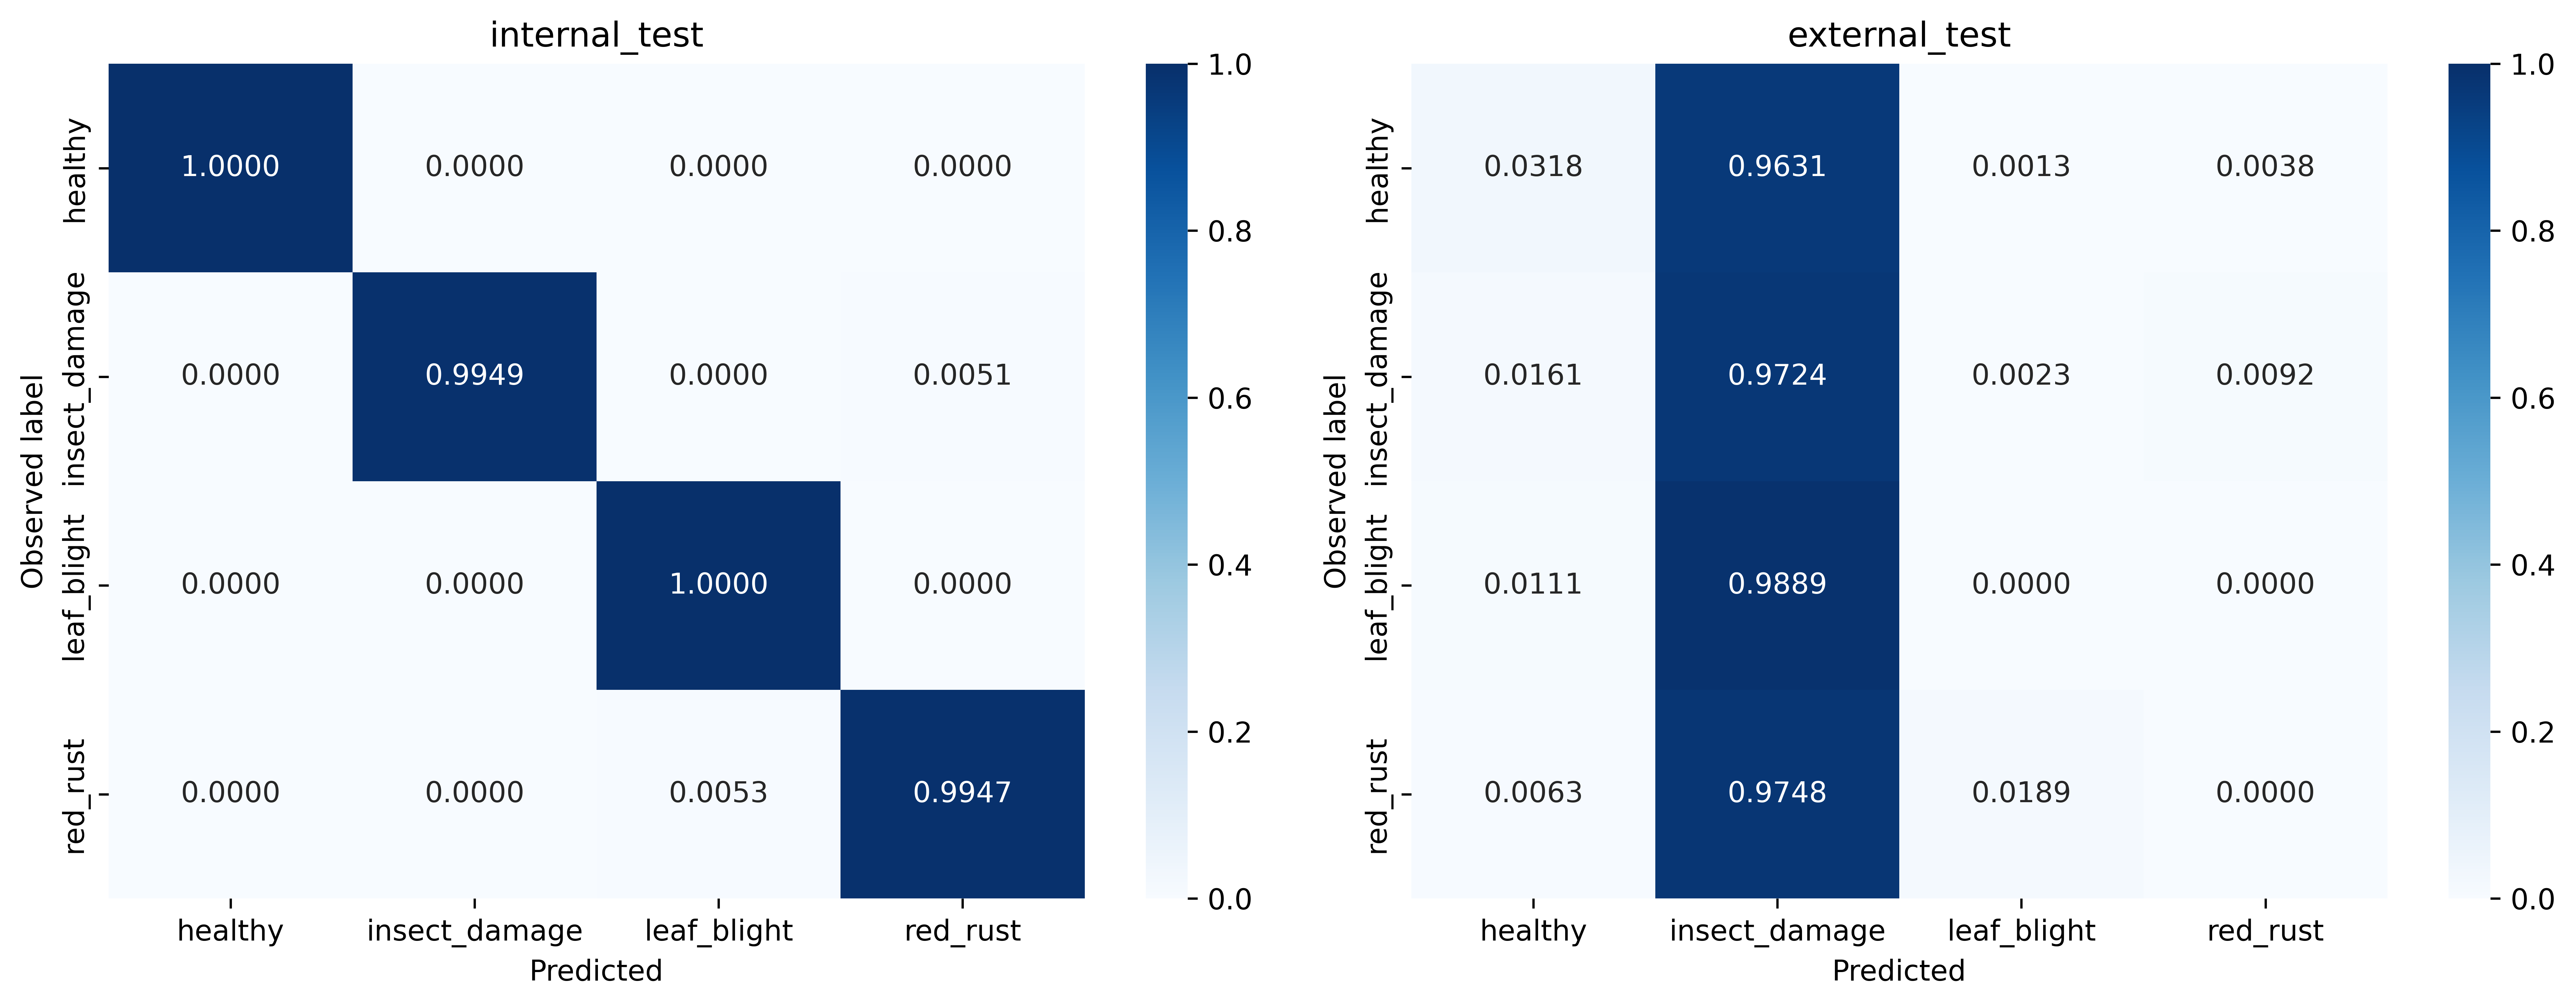

In [23]:
# Configure 600 DPI for Google Colab display and saving
%config InlineBackend.figure_format = 'png'

import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 600
mpl.rcParams['savefig.dpi'] = 600

FIGURE_DIR = OUT / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for axis, split_name in zip(axes, ['internal_test', 'external_test']):

    frame = prediction_frames[(BEST_NAME, split_name)]

    matrix = confusion_matrix(
        frame.target,
        frame.predicted_id,
        labels=range(len(CLASSES))
    )

    normalized = matrix / np.maximum(
        matrix.sum(axis=1, keepdims=True), 1
    )

    sns.heatmap(
        normalized,
        annot=True,
        fmt='.4f',
        vmin=0,
        vmax=1,
        cmap='Blues',
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=axis
    )

    axis.set(
        title=split_name,
        xlabel='Predicted',
        ylabel='Observed label'
    )

    report = classification_report(
        frame.target,
        frame.predicted_id,
        labels=range(len(CLASSES)),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).T.to_csv(
        OUT / f'class_report_{split_name}.csv'
    )

    pd.DataFrame(
        matrix,
        index=CLASSES,
        columns=CLASSES
    ).to_csv(
        OUT / f'confusion_counts_{split_name}.csv'
    )

    print(split_name)
    display(pd.DataFrame(report).T.round(3))

plt.tight_layout()

# Save at 600 DPI in PNG, PDF and EPS formats
for extension in ['png', 'pdf', 'eps']:
    fig.savefig(
        FIGURE_DIR / f'confusion_matrices.{extension}',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

# Display at 600 DPI in Google Colab
plt.show()
plt.close(fig)

### Cell 19 — Confidence and referral analysis

Use the predeclared confidence threshold of 0.80 for referral. A curve is descriptive and must not be used to choose a new threshold after observing external performance. Report both coverage and retained accuracy, because referral can hide difficult classes.


internal_test threshold 0.8 coverage 1.0 accepted accuracy 0.997


,n,accepted,accuracy
label,,,
healthy,78,78,1.000000
insect_damage,196,196,0.994898
leaf_blight,138,138,1.000000
red_rust,188,188,0.994681


external_test threshold 0.8 coverage 0.996 accepted accuracy 0.621


,n,accepted,accuracy
label,,,
healthy,786,782,0.031807
insect_damage,1739,1732,0.972398
leaf_blight,90,90,0.000000
red_rust,159,159,0.000000


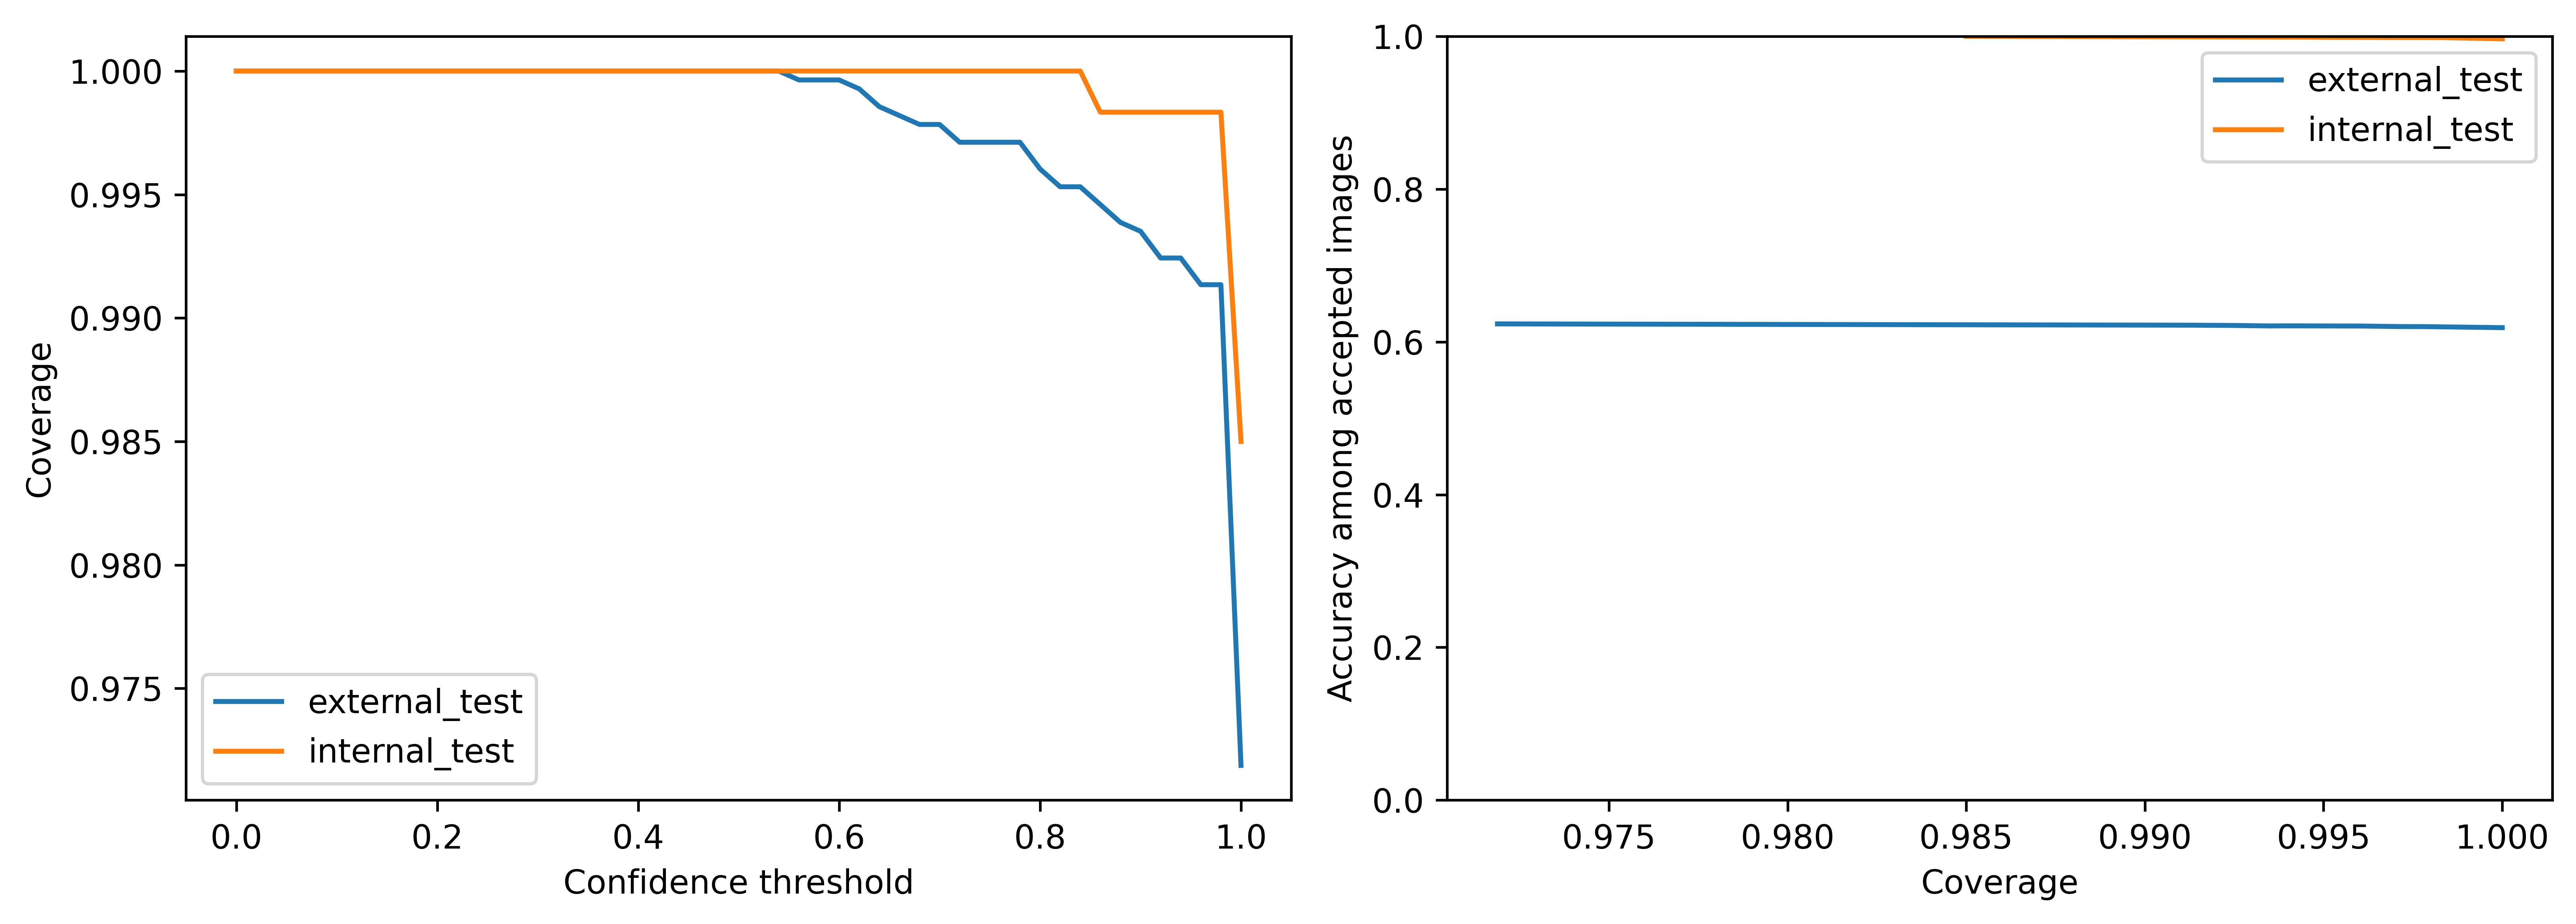

In [24]:
# Configure 600 DPI for Google Colab display and saving
%config InlineBackend.figure_format = 'png'

import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 600
mpl.rcParams['savefig.dpi'] = 600

FIGURE_DIR = OUT / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

referral_rows = []

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for split_name in ['internal_test', 'external_test']:

    frame = prediction_frames[(BEST_NAME, split_name)]

    for threshold in np.linspace(0, 1, 51):

        accepted = frame.confidence >= threshold

        referral_rows.append({
            'split': split_name,
            'threshold': float(threshold),
            'coverage': float(accepted.mean()),
            'accepted_n': int(accepted.sum()),
            'accepted_accuracy': (
                float(frame.loc[accepted, 'correct'].mean())
                if accepted.any() else np.nan
            )
        })

    accepted = frame.confidence >= CONFIG['confidence_threshold']

    print(
        split_name,
        'threshold', CONFIG['confidence_threshold'],
        'coverage', round(accepted.mean(), 3),
        'accepted accuracy',
        round(frame.loc[accepted, 'correct'].mean(), 3)
        if accepted.any() else 'undefined'
    )

    display(
        frame.assign(accepted=accepted)
        .groupby('label')
        .agg(
            n=('correct', 'size'),
            accepted=('accepted', 'sum'),
            accuracy=('correct', 'mean')
        )
    )

referral = pd.DataFrame(referral_rows)

referral.to_csv(
    OUT / 'referral_curves.csv',
    index=False
)

for split_name, group in referral.groupby('split'):

    axes[0].plot(
        group.threshold,
        group.coverage,
        label=split_name
    )

    axes[1].plot(
        group.coverage,
        group.accepted_accuracy,
        label=split_name
    )

axes[0].set(
    xlabel='Confidence threshold',
    ylabel='Coverage'
)

axes[1].set(
    xlabel='Coverage',
    ylabel='Accuracy among accepted images',
    ylim=(0, 1)
)

for axis in axes:
    axis.legend()

plt.tight_layout()

# Save at 600 DPI in PNG, PDF and EPS formats
for extension in ['png', 'pdf', 'eps']:
    fig.savefig(
        FIGURE_DIR / f'referral_curves.{extension}',
        dpi=600,
        bbox_inches='tight',
        facecolor='white'
    )

# Display at 600 DPI in Google Colab
plt.show()
plt.close(fig)

### Cell 20 — Sensitivity to insect-label alignment

Repeat the external summary on healthy, blight, and red-rust observations, retaining the original four-output predictions. Predictions of insect damage still count as errors. This reveals how much the provisional insect mapping changes the interpretation. Also report the image-family cluster bootstrap interval; it does not measure orchard-to-orchard uncertainty.


In [25]:
external_predictions = prediction_frames[(BEST_NAME, 'external_test')]
sensitivity = external_predictions[external_predictions.label.ne('insect_damage')].copy()
report = classification_report(sensitivity.target, sensitivity.predicted_id,
                               labels=range(len(CLASSES)), target_names=CLASSES,
                               output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(3))
print('Macro-F1 for the three observed classes', f1_score(
    sensitivity.target, sensitivity.predicted_id,
    labels=[CLASS_TO_ID[label] for label in ['healthy', 'leaf_blight', 'red_rust']],
    average='macro', zero_division=0))
pd.DataFrame(report).T.to_csv(OUT / 'sensitivity_excluding_observed_insect_damage.csv')

rng = np.random.default_rng(SEED)
group_indices = external_predictions.groupby('group').indices
group_names = list(group_indices)
bootstrap_scores = []
for _ in range(1000):
    sampled = rng.choice(group_names, size=len(group_names), replace=True)
    indices = np.concatenate([group_indices[group] for group in sampled])
    sample = external_predictions.iloc[indices]
    bootstrap_scores.append(f1_score(sample.target, sample.predicted_id,
                                     labels=range(len(CLASSES)), average='macro', zero_division=0))
interval = np.quantile(bootstrap_scores, [0.025, 0.975])
print('External macro-F1 image-family bootstrap 95% interval', interval)
(OUT / 'external_bootstrap.json').write_text(json.dumps({
    'unit': 'similarity/origin group', 'bootstrap_replicates': 1000,
    'macro_f1_interval_95': interval.tolist(),
    'limitation': 'Tree IDs are unavailable unless supplied. This interval does not cover collection-level uncertainty.'
}, indent=2))


,precision,recall,f1-score,support
healthy,0.926,0.032,0.062,786.000
insect_damage,0.000,0.000,0.000,0.000
leaf_blight,0.000,0.000,0.000,90.000
red_rust,0.000,0.000,0.000,159.000
accuracy,0.024,0.024,0.024,0.024
macro avg,0.231,0.008,0.015,1035.000
weighted avg,0.703,0.024,0.047,1035.000


Macro-F1 for the three observed classes 0.02050020500205002
External macro-F1 image-family bootstrap 95% interval [0.19907521 0.21296355]


273

### Cell 21 — Prepare Grad-CAM

Use the final convolutional feature block. Grad-CAM attributes a class logit to coarse image regions. Predictions, reference labels, and confidence are shown alongside the heatmaps. Use enable_grad even though training is complete.


In [26]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

explanation_model = load_checkpoint(BEST_NAME)
for parameter in explanation_model.parameters():
    parameter.requires_grad = True
target_layers = [explanation_model.features[-1]]

def explanation_input(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        boxed = letterbox(image)
    rgb = np.asarray(boxed, dtype=np.float32) / 255.0
    tensor = transforms.functional.normalize(transforms.functional.to_tensor(boxed), MEAN, STD)
    return rgb, tensor.unsqueeze(0).to(DEVICE)

def get_cam(path, target_id):
    rgb, tensor = explanation_input(path)
    with torch.enable_grad(), GradCAM(model=explanation_model, target_layers=target_layers) as cam:
        heatmap = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(int(target_id))])[0]
    overlay = show_cam_on_image(rgb, heatmap, use_rgb=True)
    return rgb, tensor, heatmap, overlay


### Cell 22 — Explain deterministic examples and errors

Select one correct and one incorrect external prediction per category using a fixed seed. These are illustrative selections, not quantitative evidence. Each figure compares attribution for the predicted class with attribution for the reference class. Identical targets give identical maps.


In [27]:
# Configure 600 DPI for Google Colab display and saving
%config InlineBackend.figure_format = 'png'

import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 600
mpl.rcParams['savefig.dpi'] = 600

FIGURE_DIR = OUT / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

examples = []

for label in CLASSES:
    for correct in [True, False]:
        candidates = external_predictions[
            external_predictions.label.eq(label)
            & external_predictions.correct.eq(correct)
        ]
        if len(candidates):
            examples.append(
                candidates.sample(1, random_state=SEED).iloc[0]
            )

explanation_examples = pd.DataFrame(examples).reset_index(drop=True)

explanation_examples.to_csv(
    OUT / 'gradcam_selected_examples.csv',
    index=False
)

for index, row in explanation_examples.iterrows():

    rgb, _, predicted_cam, predicted_overlay = get_cam(
        row.path,
        row.predicted_id
    )

    _, _, reference_cam, reference_overlay = get_cam(
        row.path,
        row.target
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(11, 4)
    )

    axes[0].imshow(rgb)
    axes[0].set_title(
        'Image\nReference: ' + row.label
    )

    axes[1].imshow(predicted_overlay)
    axes[1].set_title(
        'Predicted: ' + row.predicted_label
        + f'\nConfidence: {row.confidence:.3f}'
    )

    axes[2].imshow(reference_overlay)
    axes[2].set_title(
        'Grad-CAM for reference class\n' + row.label
    )

    for axis in axes:
        axis.axis('off')

    plt.tight_layout()

    name = f'gradcam_{index:02d}_{row.label}_correct_{row.correct}'

    # Save at 600 DPI
    for extension in ['png', 'pdf', 'eps']:
        fig.savefig(
            FIGURE_DIR / f'{name}.{extension}',
            dpi=600,
            bbox_inches='tight',
            facecolor='white'
        )

    np.savez_compressed(
        OUT / f'{name}.npz',
        predicted=predicted_cam,
        reference=reference_cam
    )

    # Display at 600 DPI in Colab
    plt.show()
    plt.close(fig)

Output hidden; open in https://colab.research.google.com to view.

### Cell 23 — Test whether highlighted regions influence the score

For a fixed random sample of up to 40 external images, replace the highest-CAM 15% of pixels with the ImageNet mean and compare the target-logit drop against 20 random masks of equal area. The target is the original predicted class and stays fixed. This is a limited perturbation diagnostic: mask shape and artificial image changes affect the result, and it does not validate lesion localization.


In [28]:
@torch.no_grad()
def masked_logit(tensor, mask, target_id):
    perturbed = tensor.clone()
    perturbed[0, :, mask] = 0.0  # ImageNet mean after normalization
    return float(explanation_model(perturbed)[0, int(target_id)].item())

rng = np.random.default_rng(SEED)
perturbation_records = []
diagnostic_sample = external_predictions.sample(min(40, len(external_predictions)), random_state=SEED)
for row in tqdm(diagnostic_sample.itertuples(index=False), total=len(diagnostic_sample), desc='CAM perturbation'):
    _, tensor, heatmap, _ = get_cam(row.path, row.predicted_id)
    with torch.no_grad():
        original_logit = float(explanation_model(tensor)[0, int(row.predicted_id)].item())
    pixel_count = heatmap.size
    count = max(1, round(0.15 * pixel_count))
    top_ids = np.argsort(heatmap.ravel(), kind='stable')[-count:]
    high_mask = np.zeros(pixel_count, dtype=bool)
    high_mask[top_ids] = True
    high_mask = torch.tensor(high_mask.reshape(heatmap.shape), device=DEVICE)
    cam_drop = original_logit - masked_logit(tensor, high_mask, row.predicted_id)
    random_drops = []
    for _ in range(20):
        mask = np.zeros(pixel_count, dtype=bool)
        mask[rng.choice(pixel_count, size=count, replace=False)] = True
        mask = torch.tensor(mask.reshape(heatmap.shape), device=DEVICE)
        random_drops.append(original_logit - masked_logit(tensor, mask, row.predicted_id))
    perturbation_records.append({'path': row.path, 'label': row.label,
                                 'predicted_label': row.predicted_label,
                                 'cam_logit_drop': cam_drop,
                                 'random_logit_drop_mean': float(np.mean(random_drops)),
                                 'random_logit_drop_sd': float(np.std(random_drops)),
                                 'cam_map_range': float(np.ptp(heatmap))})
perturbation = pd.DataFrame(perturbation_records)
perturbation['cam_minus_random_drop'] = perturbation.cam_logit_drop - perturbation.random_logit_drop_mean
perturbation.to_csv(OUT / 'cam_perturbation_diagnostic.csv', index=False)
display(perturbation.groupby('label')[['cam_logit_drop', 'random_logit_drop_mean', 'cam_minus_random_drop']].mean())
print('Fraction of flat CAMs', (perturbation.cam_map_range < 1e-8).mean())


CAM perturbation:   0%|          | 0/40 [00:00<?, ?it/s]

,cam_logit_drop,random_logit_drop_mean,cam_minus_random_drop
label,,,
healthy,2.146896,-1.094061,3.240956
insect_damage,1.772227,-0.373709,2.145936
red_rust,4.622575,3.328878,1.293697


Fraction of flat CAMs 0.0


### Cell 24 — Save the experiment record and download results

Export metrics, manifests, figures, and explanations as a ZIP. Model checkpoints stay separately available in outputs/checkpoints. The result archive excludes checkpoints and original images. Preserve the exact manifests when reporting a paper.


In [29]:
study_record = {
    'source_doi': '10.17632/jhb24mszdk.1',
    'external_doi': '10.17632/94srbmydkw.3',
    'selected_model': BEST_NAME,
    'model_selection': 'BDLitchi source validation macro-F1',
    'classes': CLASSES,
    'manifest_sha256': MANIFEST_SHA256,
    'temperatures': temperatures,
    'split_counts': {name: len(frame) for name, frame in SPLITS.items()},
    'assumptions': [
        'Shared label mapping is provisional; insect damage is broader in Rangamati.',
        'Source family grouping is based on hashes and optional supplied origin IDs.',
        'Missing leaf/tree IDs prevent assured biological independence.',
        'External labels are visual field assessments.',
        'Grad-CAM has no independent lesion-mask validation.',
        'External scores were excluded from fitting and selection.'
    ],
}
(OUT / 'study_record.json').write_text(json.dumps(study_record, indent=2))
archive_path = ROOT / 'litchi_study_results.zip'
with zipfile.ZipFile(archive_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUT.rglob('*')):
        if path.is_file() and 'checkpoints' not in path.relative_to(OUT).parts:
            archive.write(path, path.relative_to(OUT))
print('Results archive', archive_path)
print('Checkpoint directory', OUT / 'checkpoints')
try:
    from google.colab import files
except ImportError:
    print('Outside Colab: copy the result ZIP and checkpoints from the paths above.')
else:
    files.download(str(archive_path))


Results archive /content/litchi_study/litchi_study_results.zip
Checkpoint directory /content/litchi_study/outputs/checkpoints


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cell 25 — Configure the extended experiment
The five additional categories and two mixed-symptom categories remain separate. The label mapping is a research assumption, particularly for insect damage.

In [30]:
import hashlib
import json
import unicodedata
import re

import imagehash
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from pathlib import Path
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from scipy.special import softmax, logsumexp

from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc,
)
from torch.utils.data import DataLoader

required_variables = [
    "all_images", "train_df", "val_df", "test_df",
    "CLASSES", "CLASS_TO_ID", "BEST_NAME",
    "temperatures", "load_checkpoint",
    "LeafDataset", "eval_transform",
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Run the earlier notebook cells first. Missing: {missing}"
    )

EXT_OUT = OUT / "extended_evaluation"
EXT_FIG = EXT_OUT / "figures"

EXT_OUT.mkdir(parents=True, exist_ok=True)
EXT_FIG.mkdir(parents=True, exist_ok=True)

# Empirical acceptance target on source validation.
# This does not guarantee the same acceptance on external data.
SOURCE_ACCEPTANCE_TARGET = 0.95

AUDIT_PHASH_DISTANCE = CONFIG.get("phash_distance", 4)

KNOWN_FOLDER_MAP = {
    "healthy leaves": "healthy",
    "healthy leaf": "healthy",
    "insect damage": "insect_damage",
    "inspact damage": "insect_damage",
    "leaf blight": "leaf_blight",
    "red rust": "red_rust",
}

ADDITIONAL_FOLDERS = {
    "anthracnose",
    "dieback",
    "leaf curl erinose mite",
    "leaf spot",
    "sooty mold",
}

MIXED_FOLDERS = {
    "leaf blight anthracnose",
    "leaf curl sooty mold",
}


def normalize_folder(text):
    text = unicodedata.normalize("NFKC", str(text)).casefold()
    return re.sub(r"[^a-z0-9]+", " ", text).strip()


protocol = {
    "source_acceptance_target": SOURCE_ACCEPTANCE_TARGET,
    "phash_distance": AUDIT_PHASH_DISTANCE,
    "known_folder_mapping": KNOWN_FOLDER_MAP,
    "additional_folders": sorted(ADDITIONAL_FOLDERS),
    "mixed_folders": sorted(MIXED_FOLDERS),
    "models": CONFIG["models"],
    "selected_model": BEST_NAME,
    "selection_basis": "source validation macro-F1",
}

(EXT_OUT / "protocol.json").write_text(
    json.dumps(protocol, indent=2)
)

print("Selected model:", BEST_NAME)
print("Source-validation acceptance target:", SOURCE_ACCEPTANCE_TARGET)

Selected model: mobilenet_v3_small
Source-validation acceptance target: 0.95


Cell 26 — Prepare all external categories
This uses the full external inventory. The original audited four-class test set is retained as the eligibility reference for known-category images.

In [31]:
external_inventory = all_images[
    all_images["source"].eq("RangamatiV3")
].copy()

external_inventory = external_inventory.drop_duplicates(
    subset="path"
).reset_index(drop=True)

external_inventory["folder_normalized"] = (
    external_inventory["folder_label"].map(normalize_folder)
)

external_inventory["evaluation_group"] = None
external_inventory["matched_label"] = None

for index, row in external_inventory.iterrows():

    folder = row["folder_normalized"]

    if folder in KNOWN_FOLDER_MAP:
        external_inventory.loc[index, "evaluation_group"] = "known"
        external_inventory.loc[index, "matched_label"] = (
            KNOWN_FOLDER_MAP[folder]
        )

    elif folder in ADDITIONAL_FOLDERS:
        external_inventory.loc[
            index, "evaluation_group"
        ] = "additional"

    elif folder in MIXED_FOLDERS:
        external_inventory.loc[
            index, "evaluation_group"
        ] = "mixed"

unmapped = external_inventory[
    external_inventory["evaluation_group"].isna()
]

if len(unmapped):
    display(
        unmapped[
            ["folder_label", "folder_normalized"]
        ].drop_duplicates()
    )
    raise ValueError("Review the unmapped external folder names.")

# Preserve exclusions made in the original external audit.
original_external_paths = set(
    SPLITS["external_test"]["path"].astype(str)
)

external_inventory["eligible_from_original_audit"] = (
    external_inventory["evaluation_group"].ne("known")
    | external_inventory["path"].isin(original_external_paths)
)

external_inventory.to_csv(
    EXT_OUT / "external_inventory_before_audit.csv",
    index=False
)

display(
    external_inventory.groupby(
        ["evaluation_group", "folder_label"]
    ).size().rename("images").to_frame()
)

images
evaluation_group folder_label                   
additional       Anthracnose                 555
                 Dieback                     380
                 Leaf_Curl&Erinose_Mite      685
                 Leaf_Spot                   575
                 Sooty_Mold                  346
known            Healthy_Leaves              786
                 Inspact_Damage             1739
                 Leaf_Blight                  90
                 Red_Rust                    159
mixed            Leaf_Blight&Anthracnose      76
                 Leaf_Curl&Sooty_Mold         54

Cell 27 — Extend the duplicate audit
Audit all external categories together. Exclude external image families that overlap source images, contain conflicting category labels, or repeat identical decoded pixels.

This is conservative image-family filtering. Missing leaf and tree identifiers still limit biological independence.

In [32]:
source_reference = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
).drop_duplicates(subset="path").copy()

fingerprint_columns = [
    "pixel_sha256",
    "phash",
]

if not set(fingerprint_columns).issubset(source_reference.columns):
    raise ValueError(
        "Source manifests need pixel_sha256 and phash from Cell 8."
    )

external_audit_rows = []

for row in tqdm(
    external_inventory.itertuples(index=False),
    total=len(external_inventory),
    desc="Auditing all external categories"
):
    record = row._asdict()

    try:
        with Image.open(row.path) as image:
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            rgb.load()

            record["pixel_sha256"] = hashlib.sha256(
                str(rgb.size).encode() + rgb.tobytes()
            ).hexdigest()

            record["phash"] = str(
                imagehash.phash(rgb, hash_size=8)
            )

            record["width"] = rgb.width
            record["height"] = rgb.height

        record["decode_error"] = ""

    except Exception as error:
        record["decode_error"] = str(error)

    external_audit_rows.append(record)

external_audit = pd.DataFrame(external_audit_rows)

external_audit.to_csv(
    EXT_OUT / "all_external_image_audit.csv",
    index=False
)

external_valid = external_audit[
    external_audit["decode_error"].eq("")
].copy().reset_index(drop=True)

reference = source_reference[
    ["path", "pixel_sha256", "phash"]
].copy()

reference["domain"] = "source_reference"

external_valid["domain"] = "external"

combined_audit = pd.concat(
    [reference, external_valid],
    ignore_index=True
)

parents = np.arange(len(combined_audit))


def root_of(index):
    while parents[index] != index:
        parents[index] = parents[parents[index]]
        index = parents[index]
    return int(index)


def join_family(left, right):
    left_root = root_of(left)
    right_root = root_of(right)

    if left_root != right_root:
        parents[right_root] = left_root


# Group identical decoded images.
for indices in combined_audit.groupby(
    "pixel_sha256"
).groups.values():

    indices = list(indices)

    for other in indices[1:]:
        join_family(indices[0], other)

# Group conservative perceptual neighbours.
hash_bits = np.array([
    [int(bit) for bit in format(int(value, 16), "064b")]
    for value in combined_audit["phash"]
], dtype=np.uint8)

neighbour_search = NearestNeighbors(
    radius=(AUDIT_PHASH_DISTANCE + 0.01) / 64,
    algorithm="ball_tree",
    metric="hamming"
).fit(hash_bits)

_, neighbour_indices = neighbour_search.radius_neighbors(hash_bits)

for left, neighbours in enumerate(neighbour_indices):
    for right in neighbours:
        right = int(right)

        if right > left:
            join_family(left, right)

combined_audit["audit_group"] = [
    f"extended_family_{root_of(index):06d}"
    for index in range(len(combined_audit))
]

source_family_ids = set(
    combined_audit.loc[
        combined_audit["domain"].eq("source_reference"),
        "audit_group"
    ]
)

external_checked = combined_audit[
    combined_audit["domain"].eq("external")
].copy().reset_index(drop=True)

category_counts = external_checked.groupby(
    "audit_group"
)["folder_normalized"].nunique()

conflicting_families = set(
    category_counts[category_counts > 1].index
)

external_checked["exclusion_reason"] = ""

external_checked.loc[
    ~external_checked["eligible_from_original_audit"].astype(bool),
    "exclusion_reason"
] = "excluded by original known-category audit"

external_checked.loc[
    external_checked["audit_group"].isin(source_family_ids),
    "exclusion_reason"
] = "image family overlaps source reference"

external_checked.loc[
    external_checked["audit_group"].isin(conflicting_families),
    "exclusion_reason"
] = "conflicting labels within image family"

repeated_pixels = external_checked.duplicated(
    subset="pixel_sha256",
    keep="first"
)

external_checked.loc[
    repeated_pixels & external_checked["exclusion_reason"].eq(""),
    "exclusion_reason"
] = "repeated decoded pixels"

external_checked.to_csv(
    EXT_OUT / "extended_duplicate_decisions.csv",
    index=False
)

extended_external = external_checked[
    external_checked["exclusion_reason"].eq("")
].copy().reset_index(drop=True)

extended_external["target"] = (
    extended_external["matched_label"]
    .map(CLASS_TO_ID)
    .fillna(-1)
    .astype(int)
)

extended_external.to_csv(
    EXT_OUT / "extended_external_manifest.csv",
    index=False
)

for group in ["known", "additional", "mixed"]:
    if not extended_external["evaluation_group"].eq(group).any():
        raise ValueError(f"No images remain in evaluation group: {group}")

if set(
    extended_external.loc[
        extended_external["evaluation_group"].eq("known"),
        "matched_label"
    ]
) != set(CLASSES):
    raise ValueError("A known category disappeared during filtering.")

print("Failed decodes:", external_audit["decode_error"].ne("").sum())

display(
    extended_external.groupby(
        ["evaluation_group", "folder_label"]
    ).size().rename("retained_images").to_frame()
)

Auditing all external categories:   0%|          | 0/5445 [00:00<?, ?it/s]

Failed decodes: 0


retained_images
evaluation_group folder_label                            
additional       Anthracnose                          553
                 Dieback                              380
                 Leaf_Curl&Erinose_Mite               681
                 Leaf_Spot                            575
                 Sooty_Mold                           346
known            Healthy_Leaves                       785
                 Inspact_Damage                      1738
                 Leaf_Blight                           89
                 Red_Rust                             159
mixed            Leaf_Blight&Anthracnose               76
                 Leaf_Curl&Sooty_Mold                  54

Cell 28 — Set referral thresholds using source validation
Three scores are compared. Higher scores indicate stronger evidence for referral.
- Raw maximum-softmax confidence.
- Temperature-scaled maximum-softmax confidence.
- Energy from unscaled logits with energy temperature fixed at 1.
The thresholds target 95% acceptance on source-validation images.

In [33]:
SCORE_METHODS = {
    "raw_confidence": "reject_raw",
    "calibrated_confidence": "reject_calibrated",
    "energy": "reject_energy",
}


def evaluation_loader(frame):
    return DataLoader(
        LeafDataset(frame, eval_transform),
        batch_size=CONFIG["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )


@torch.no_grad()
def infer_logits(model, frame):

    model.eval()
    batches = []

    for images, _ in evaluation_loader(frame):
        logits = model(images.to(DEVICE))
        batches.append(logits.float().cpu().numpy())

    return np.concatenate(batches, axis=0)


def attach_scores(frame, logits, temperature):

    result = frame.reset_index(drop=True).copy()

    raw_probabilities = softmax(logits, axis=1)
    calibrated_probabilities = softmax(
        logits / temperature,
        axis=1
    )

    result["predicted_id"] = logits.argmax(axis=1)
    result["predicted_label"] = result["predicted_id"].map(
        dict(enumerate(CLASSES))
    )

    result["raw_confidence"] = raw_probabilities.max(axis=1)
    result["calibrated_confidence"] = (
        calibrated_probabilities.max(axis=1)
    )

    result["reject_raw"] = 1 - result["raw_confidence"]
    result["reject_calibrated"] = (
        1 - result["calibrated_confidence"]
    )

    # E(x) = -log(sum(exp(logits))), with energy temperature = 1.
    result["reject_energy"] = -logsumexp(logits, axis=1)

    for index, label in enumerate(CLASSES):
        result[f"prob_{label}"] = (
            calibrated_probabilities[:, index]
        )

    return result


threshold_rows = []
validation_score_frames = {}

for model_name in CONFIG["models"]:

    model = load_checkpoint(model_name)

    validation_logits = infer_logits(model, val_df)

    validation_scores = attach_scores(
        val_df,
        validation_logits,
        temperatures[model_name]
    )

    validation_score_frames[model_name] = validation_scores

    for method, score_column in SCORE_METHODS.items():

        threshold = float(
            np.quantile(
                validation_scores[score_column],
                SOURCE_ACCEPTANCE_TARGET,
                method="higher"
            )
        )

        achieved_acceptance = float(
            validation_scores[score_column].le(threshold).mean()
        )

        threshold_rows.append({
            "model": model_name,
            "method": method,
            "score_column": score_column,
            "threshold": threshold,
            "source_acceptance_target": SOURCE_ACCEPTANCE_TARGET,
            "source_acceptance_observed": achieved_acceptance,
        })

    del model

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

threshold_table = pd.DataFrame(threshold_rows)

threshold_table.to_csv(
    EXT_OUT / "source_validation_thresholds.csv",
    index=False
)

display(threshold_table.round(6))

,model,method,score_column,threshold,source_acceptance_target,source_acceptance_observed
0,mobilenet_v3_small,raw_confidence,reject_raw,0.014138,0.95,0.951754
1,mobilenet_v3_small,calibrated_confidence,reject_calibrated,0.000000,0.95,0.997807
2,mobilenet_v3_small,energy,reject_energy,-6.055320,0.95,0.951754
3,efficientnet_v2_s,raw_confidence,reject_raw,0.000786,0.95,0.951754
4,efficientnet_v2_s,calibrated_confidence,reject_calibrated,0.000000,0.95,1.000000
5,efficientnet_v2_s,energy,reject_energy,-6.479514,0.95,0.951754


Cell 29 — Score all external images
All external images now pass through the existing four-class models. The additional and mixed categories receive target=-1 for bookkeeping.

In [34]:
external_score_frames = {}

for model_name in CONFIG["models"]:

    model = load_checkpoint(model_name)

    external_logits = infer_logits(
        model,
        extended_external
    )

    scored = attach_scores(
        extended_external,
        external_logits,
        temperatures[model_name]
    )

    scored["model"] = model_name

    for method, score_column in SCORE_METHODS.items():

        row = threshold_table[
            threshold_table["model"].eq(model_name)
            & threshold_table["method"].eq(method)
        ].iloc[0]

        scored[f"accept_{method}"] = (
            scored[score_column] <= row["threshold"]
        )

    scored.to_csv(
        EXT_OUT / f"all_external_predictions_{model_name}.csv",
        index=False
    )

    external_score_frames[model_name] = scored

    del model

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

print("External predictions saved for:", list(external_score_frames))

External predictions saved for: ['mobilenet_v3_small', 'efficientnet_v2_s']


Cell 30 — Produce the main comparison tables
The denominators matter here. Known-category selective accuracy considers accepted known images. False acceptance considers additional-category images.

In [35]:
def masked_rate(values, mask):

    values = np.asarray(values, dtype=bool)
    mask = np.asarray(mask, dtype=bool)

    if mask.sum() == 0:
        return np.nan

    return float(values[mask].mean())


comparison_rows = []
condition_rows = []

for model_name, frame in external_score_frames.items():

    known = frame["evaluation_group"].eq("known").to_numpy()
    additional = (
        frame["evaluation_group"].eq("additional").to_numpy()
    )
    mixed = frame["evaluation_group"].eq("mixed").to_numpy()

    correct = (
        frame["predicted_id"].to_numpy()
        == frame["target"].to_numpy()
    )

    predicted_healthy = (
        frame["predicted_id"].to_numpy()
        == CLASS_TO_ID["healthy"]
    )

    settings = {
        "always_label": np.ones(len(frame), dtype=bool)
    }

    for method in SCORE_METHODS:
        settings[method] = frame[f"accept_{method}"].to_numpy()

    for method, accepted in settings.items():

        accepted_known = accepted & known

        comparison_rows.append({
            "model": model_name,
            "method": method,
            "known_n": int(known.sum()),
            "additional_n": int(additional.sum()),
            "mixed_n": int(mixed.sum()),

            "known_closed_set_macro_f1": f1_score(
                frame.loc[known, "target"],
                frame.loc[known, "predicted_id"],
                labels=range(len(CLASSES)),
                average="macro",
                zero_division=0
            ),

            "known_acceptance": masked_rate(
                accepted, known
            ),

            "known_selective_accuracy": masked_rate(
                correct, accepted_known
            ),

            # Correct AND accepted / all known images.
            "known_correct_accepted_rate": masked_rate(
                correct & accepted, known
            ),

            "additional_false_acceptance": masked_rate(
                accepted, additional
            ),

            # Accepted as healthy / all additional images.
            "additional_false_healthy_rate": masked_rate(
                accepted & predicted_healthy, additional
            ),

            "mixed_referral_rate": masked_rate(
                ~accepted, mixed
            ),
        })

        for folder_label, condition in frame.groupby("folder_label"):

            positions = frame.index.get_indexer(condition.index)
            local_acceptance = accepted[positions]

            condition_rows.append({
                "model": model_name,
                "method": method,
                "folder_label": folder_label,
                "evaluation_group": condition[
                    "evaluation_group"
                ].iloc[0],
                "n": len(condition),
                "acceptance_rate": float(
                    local_acceptance.mean()
                ),
                "referral_rate": float(
                    (~local_acceptance).mean()
                ),
                "accepted_as_healthy_rate": float(
                    (
                        local_acceptance
                        & condition["predicted_id"]
                        .eq(CLASS_TO_ID["healthy"])
                        .to_numpy()
                    ).mean()
                ),
            })

comparison_table = pd.DataFrame(comparison_rows)
condition_table = pd.DataFrame(condition_rows)

comparison_table.to_csv(
    EXT_OUT / "referral_comparison.csv",
    index=False
)

condition_table.to_csv(
    EXT_OUT / "referral_by_external_condition.csv",
    index=False
)

display(comparison_table.round(4))

display(
    condition_table[
        condition_table["model"].eq(BEST_NAME)
    ].round(4)
)

,model,method,known_n,additional_n,mixed_n,known_closed_set_macro_f1,known_acceptance,known_selective_accuracy,known_correct_accepted_rate,additional_false_acceptance,additional_false_healthy_rate,mixed_referral_rate
0,mobilenet_v3_small,always_label,2771,2535,130,0.2058,1.0000,0.6189,0.6189,1.0000,0.0083,0.0000
1,mobilenet_v3_small,raw_confidence,2771,2535,130,0.2058,0.7784,0.6338,0.4933,0.7830,0.0000,0.1769
2,mobilenet_v3_small,calibrated_confidence,2771,2535,130,0.2058,0.9719,0.6238,0.6063,0.9791,0.0047,0.0231
3,mobilenet_v3_small,energy,2771,2535,130,0.2058,0.6185,0.6441,0.3984,0.6217,0.0000,0.3538
4,efficientnet_v2_s,always_label,2771,2535,130,0.2999,1.0000,0.5911,0.5911,1.0000,0.0323,0.0000
5,efficientnet_v2_s,raw_confidence,2771,2535,130,0.2999,0.0635,0.8977,0.0570,0.0584,0.0000,0.9923
6,efficientnet_v2_s,calibrated_confidence,2771,2535,130,0.2999,0.7636,0.6446,0.4922,0.7487,0.0083,0.2231
7,efficientnet_v2_s,energy,2771,2535,130,0.2999,0.0585,0.9012,0.0527,0.0584,0.0000,0.9923


,model,method,folder_label,evaluation_group,n,acceptance_rate,referral_rate,accepted_as_healthy_rate
0,mobilenet_v3_small,always_label,Anthracnose,additional,553,1.0000,0.0000,0.0108
1,mobilenet_v3_small,always_label,Dieback,additional,380,1.0000,0.0000,0.0105
2,mobilenet_v3_small,always_label,Healthy_Leaves,known,785,1.0000,0.0000,0.0318
3,mobilenet_v3_small,always_label,Inspact_Damage,known,1738,1.0000,0.0000,0.0161
4,mobilenet_v3_small,always_label,Leaf_Blight,known,89,1.0000,0.0000,0.0112
5,mobilenet_v3_small,always_label,Leaf_Blight&Anthracnose,mixed,76,1.0000,0.0000,0.0000
6,mobilenet_v3_small,always_label,Leaf_Curl&Erinose_Mite,additional,681,1.0000,0.0000,0.0044
7,mobilenet_v3_small,always_label,Leaf_Curl&Sooty_Mold,mixed,54,1.0000,0.0000,0.0000
8,mobilenet_v3_small,always_label,Leaf_Spot,additional,575,1.0000,0.0000,0.0070
9,mobilenet_v3_small,always_label,Red_Rust,known,159,1.0000,0.0000,0.0063


Cell 31 — Evaluate separation of known and additional categories
AUROC and average precision evaluate referral-score discrimination. OSCR additionally accounts for correct classification of accepted known images.

Mixed symptoms are evaluated separately in Cell 30.

In [36]:
def compute_oscr(known_scores, known_correct, additional_scores):

    known_scores = np.asarray(known_scores)
    known_correct = np.asarray(known_correct, dtype=bool)
    additional_scores = np.asarray(additional_scores)

    thresholds = np.unique(
        np.concatenate([known_scores, additional_scores])
    )

    known_order = np.argsort(known_scores)
    sorted_known = known_scores[known_order]

    cumulative_correct = np.r_[
        0,
        np.cumsum(known_correct[known_order])
    ]

    accepted_known_counts = np.searchsorted(
        sorted_known,
        thresholds,
        side="right"
    )

    accepted_additional_counts = np.searchsorted(
        np.sort(additional_scores),
        thresholds,
        side="right"
    )

    correct_classification_rate = np.r_[
        0,
        cumulative_correct[accepted_known_counts]
        / len(known_scores)
    ]

    false_acceptance_rate = np.r_[
        0,
        accepted_additional_counts
        / len(additional_scores)
    ]

    oscr_area = float(
        auc(
            false_acceptance_rate,
            correct_classification_rate
        )
    )

    return (
        false_acceptance_rate,
        correct_classification_rate,
        oscr_area
    )


detection_rows = []
oscr_curves = {}
detection_roc_curves = {}

for model_name, frame in external_score_frames.items():

    evaluation = frame[
        frame["evaluation_group"].isin(
            ["known", "additional"]
        )
    ].copy()

    is_additional = (
        evaluation["evaluation_group"]
        .eq("additional")
        .astype(int)
        .to_numpy()
    )

    known = evaluation["evaluation_group"].eq("known")
    additional = evaluation["evaluation_group"].eq("additional")

    known_correct = (
        evaluation.loc[known, "target"].to_numpy()
        == evaluation.loc[known, "predicted_id"].to_numpy()
    )

    for method, score_column in SCORE_METHODS.items():

        scores = evaluation[score_column].to_numpy()

        false_positive_rate, true_positive_rate, _ = roc_curve(
            is_additional,
            scores
        )

        far, ccr, oscr_area = compute_oscr(
            evaluation.loc[known, score_column].to_numpy(),
            known_correct,
            evaluation.loc[additional, score_column].to_numpy()
        )

        detection_roc_curves[(model_name, method)] = (
            false_positive_rate,
            true_positive_rate
        )

        oscr_curves[(model_name, method)] = (far, ccr)

        detection_rows.append({
            "model": model_name,
            "method": method,
            "known_n": int(known.sum()),
            "additional_n": int(additional.sum()),
            "additional_prevalence": float(
                is_additional.mean()
            ),
            "referral_auroc": roc_auc_score(
                is_additional, scores
            ),
            "referral_average_precision": (
                average_precision_score(
                    is_additional, scores
                )
            ),
            "oscr_area": oscr_area,
        })

detection_table = pd.DataFrame(detection_rows)

detection_table.to_csv(
    EXT_OUT / "open_category_detection_metrics.csv",
    index=False
)

display(detection_table.round(4))

,model,method,known_n,additional_n,additional_prevalence,referral_auroc,referral_average_precision,oscr_area
0,mobilenet_v3_small,raw_confidence,2771,2535,0.4778,0.5011,0.4720,0.3219
1,mobilenet_v3_small,calibrated_confidence,2771,2535,0.4778,0.4963,0.4753,0.3096
2,mobilenet_v3_small,energy,2771,2535,0.4778,0.4906,0.4652,0.3170
3,efficientnet_v2_s,raw_confidence,2771,2535,0.4778,0.5199,0.4917,0.3485
4,efficientnet_v2_s,calibrated_confidence,2771,2535,0.4778,0.5072,0.4849,0.3207
5,efficientnet_v2_s,energy,2771,2535,0.4778,0.5070,0.4972,0.3366


Cell 32 — Export publication-grade referral plots
The curves describe performance over thresholds. The operating thresholds remain those fixed in Cell 28.

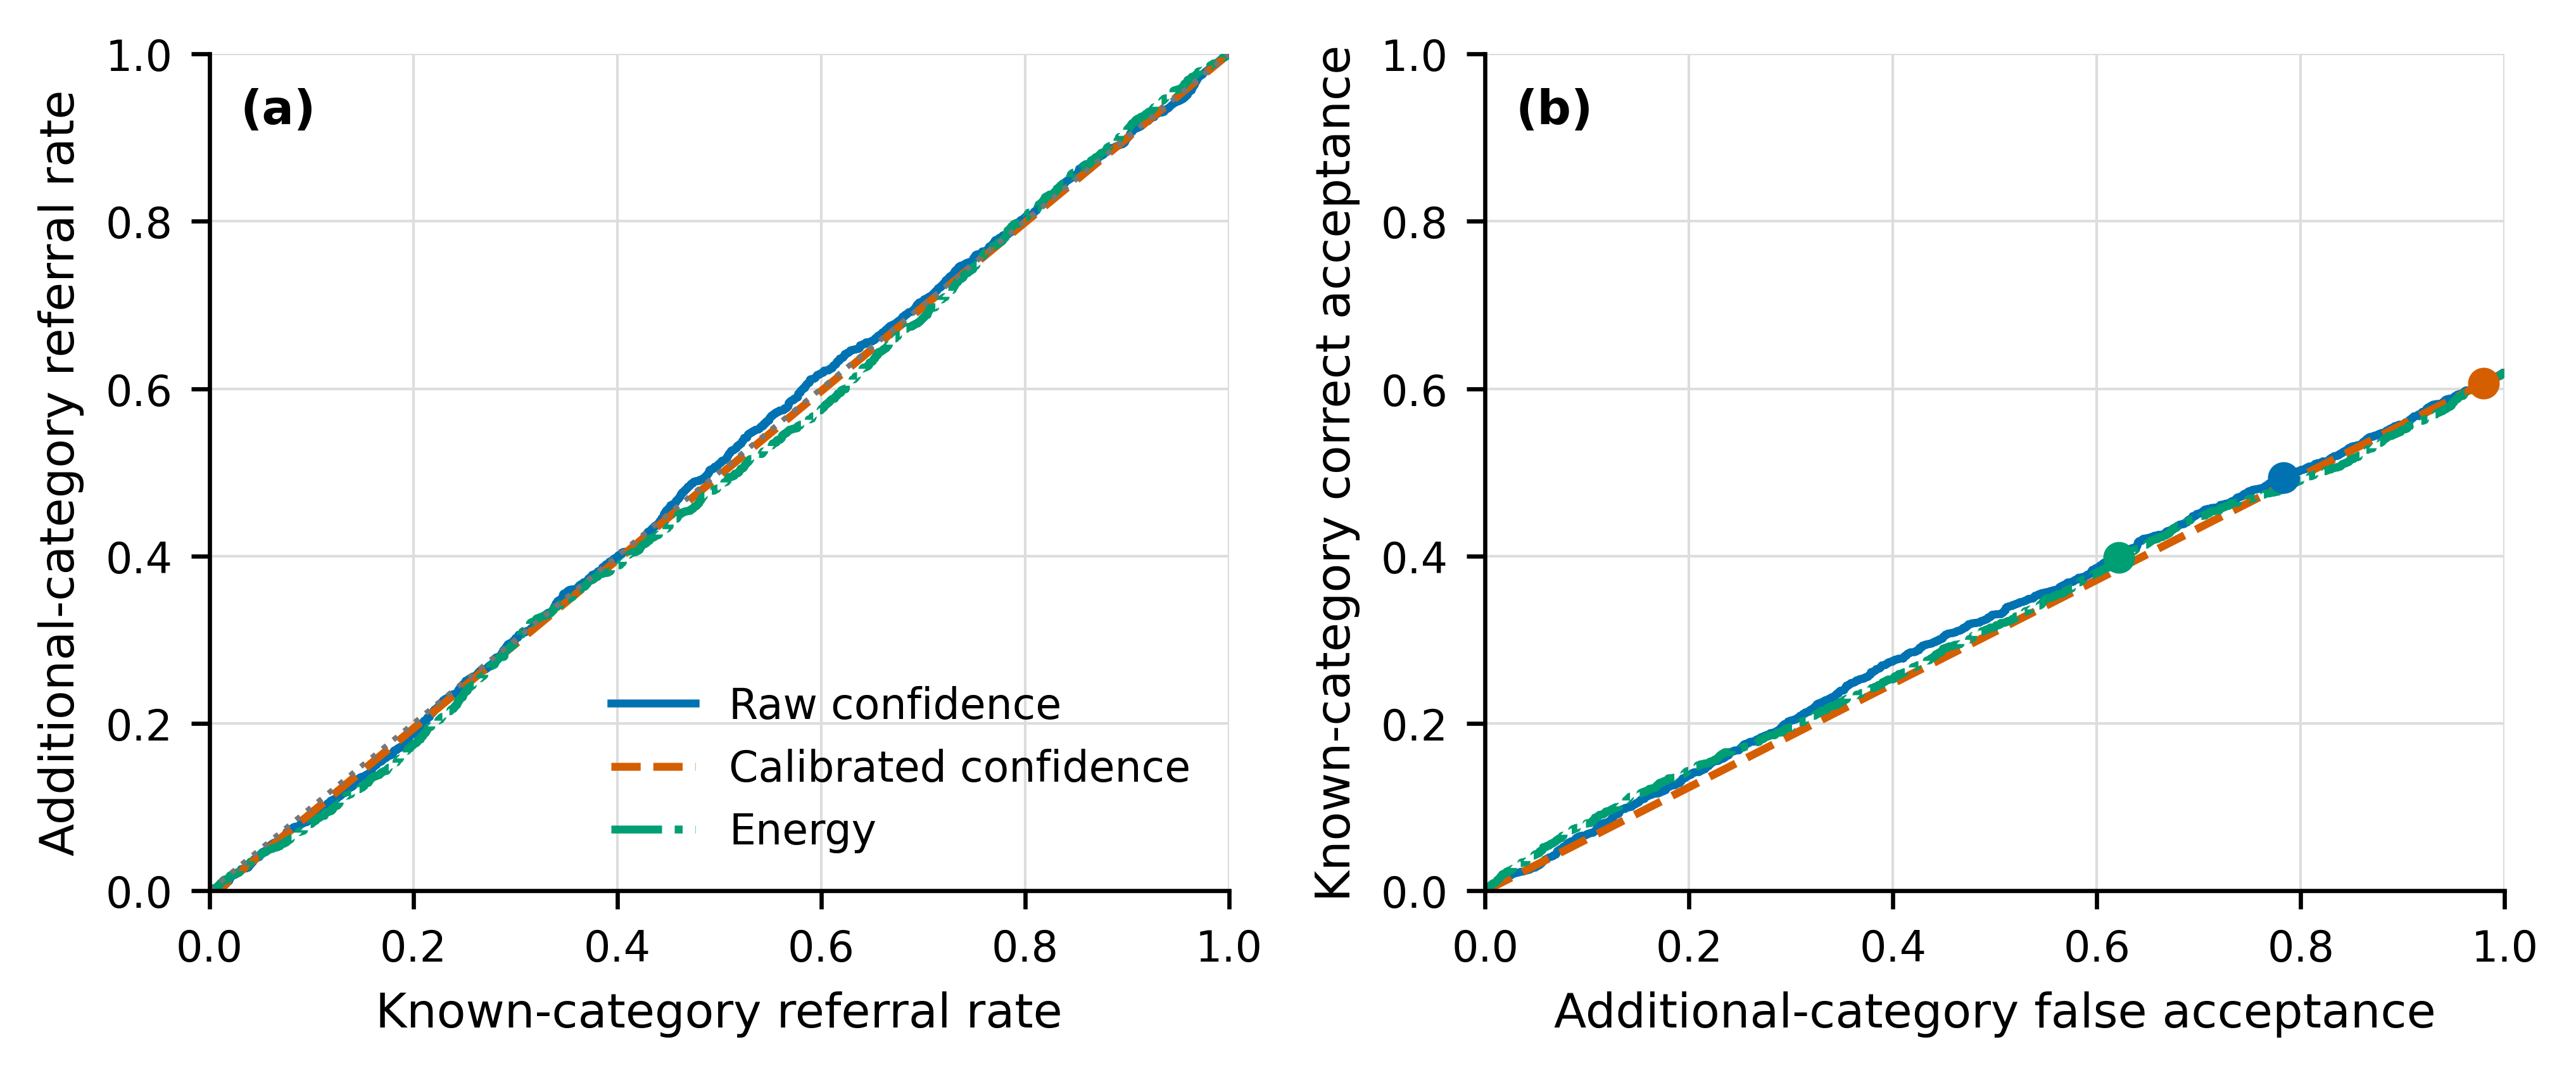

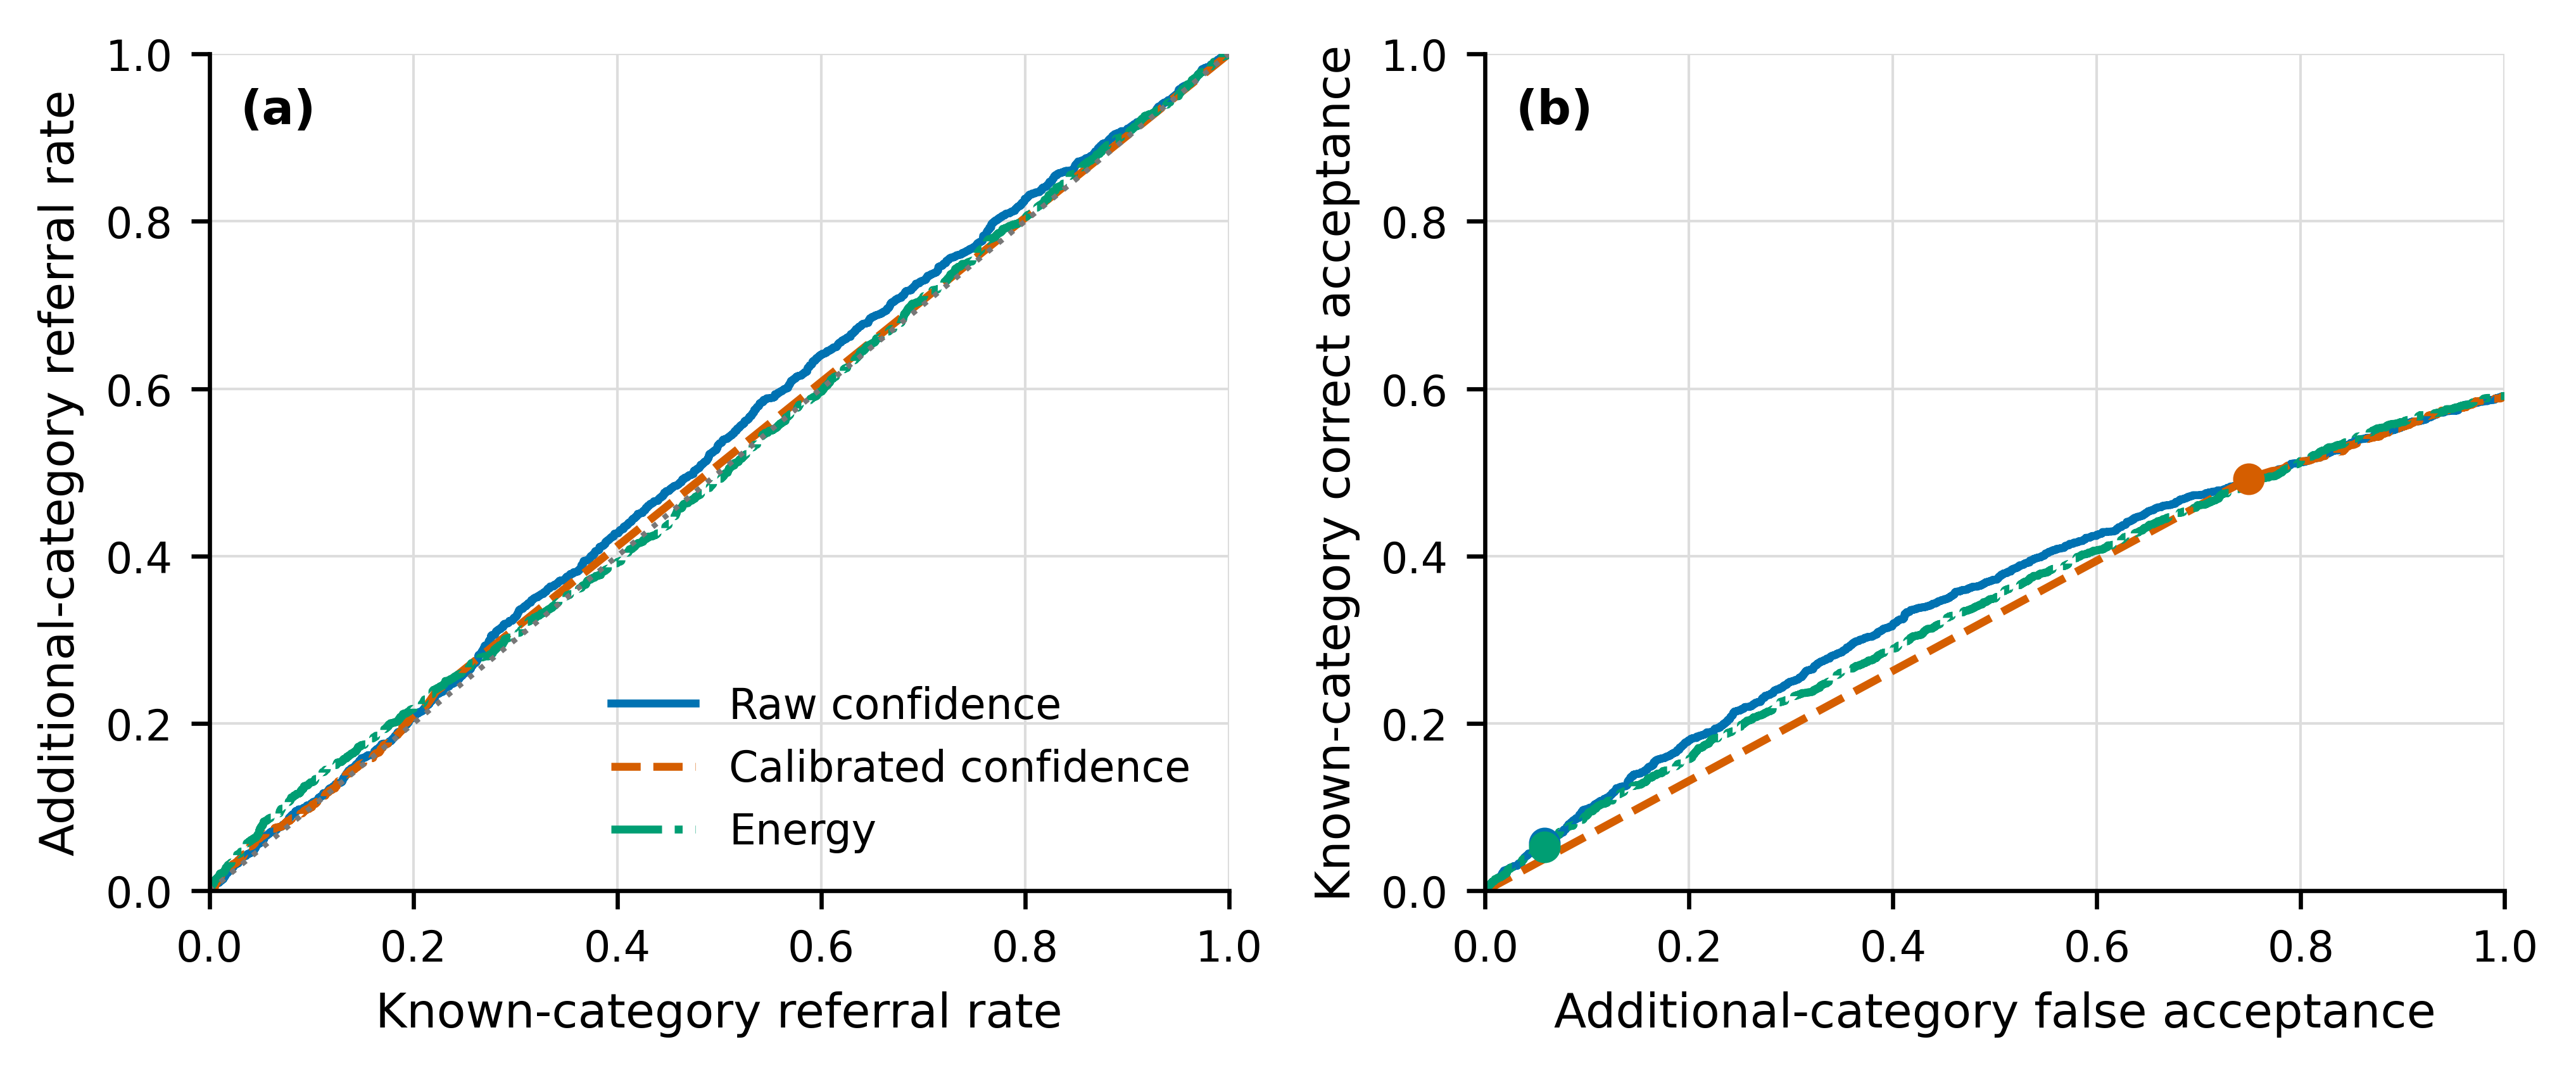

In [37]:
# Configure 600 DPI display in Google Colab
%config InlineBackend.figure_format = 'png'

import matplotlib as mpl

METHOD_STYLE = {
    "raw_confidence": {
        "label": "Raw confidence",
        "color": "#0072B2",
        "linestyle": "-"
    },
    "calibrated_confidence": {
        "label": "Calibrated confidence",
        "color": "#D55E00",
        "linestyle": "--"
    },
    "energy": {
        "label": "Energy",
        "color": "#009E73",
        "linestyle": "-."
    },
}

PUBLICATION_STYLE = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    # 600 DPI for Colab inline display
    "figure.dpi": 600,

    # 600 DPI for exported raster figures
    "savefig.dpi": 600,
}


def save_extended_figure(fig, stem):

    for extension in ["pdf", "eps", "png"]:
        fig.savefig(
            EXT_FIG / f"{stem}.{extension}",
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )


for model_name in CONFIG["models"]:

    frame = external_score_frames[model_name]

    known = frame["evaluation_group"].eq("known").to_numpy()

    additional = (
        frame["evaluation_group"].eq("additional").to_numpy()
    )

    correct = (
        frame["target"].to_numpy()
        == frame["predicted_id"].to_numpy()
    )

    with mpl.rc_context(PUBLICATION_STYLE):

        fig, axes = plt.subplots(
            1, 2,
            figsize=(174 / 25.4, 2.9)
        )

        for method, style in METHOD_STYLE.items():

            fpr, tpr = detection_roc_curves[
                (model_name, method)
            ]

            far, ccr = oscr_curves[
                (model_name, method)
            ]

            axes[0].plot(
                fpr, tpr,
                color=style["color"],
                linestyle=style["linestyle"],
                linewidth=1.5,
                label=style["label"]
            )

            axes[1].plot(
                far, ccr,
                color=style["color"],
                linestyle=style["linestyle"],
                linewidth=1.5,
                label=style["label"]
            )

            # Mark the source-validation operating threshold.
            accepted = frame[
                f"accept_{method}"
            ].to_numpy()

            operating_far = accepted[additional].mean()

            operating_ccr = (
                accepted[known] & correct[known]
            ).mean()

            axes[1].scatter(
                operating_far,
                operating_ccr,
                color=style["color"],
                s=25,
                zorder=5
            )

        axes[0].plot(
            [0, 1], [0, 1],
            color="#777777",
            linestyle=":",
            linewidth=1
        )

        axes[0].set(
            xlabel="Known-category referral rate",
            ylabel="Additional-category referral rate",
            xlim=(0, 1),
            ylim=(0, 1)
        )

        axes[1].set(
            xlabel="Additional-category false acceptance",
            ylabel="Known-category correct acceptance",
            xlim=(0, 1),
            ylim=(0, 1)
        )

        for axis, panel in zip(axes, ["(a)", "(b)"]):

            axis.text(
                0.03, 0.96,
                panel,
                transform=axis.transAxes,
                va="top",
                fontweight="bold"
            )

            axis.spines["top"].set_visible(False)
            axis.spines["right"].set_visible(False)

            axis.grid(
                color="#DDDDDD",
                linewidth=0.5
            )

        axes[0].legend(
            loc="lower right",
            frameon=False
        )

        fig.tight_layout()

        # Save PDF, EPS and PNG at 600 DPI
        save_extended_figure(
            fig,
            f"referral_ROC_OSCR_{model_name}"
        )

        # Display figure at 600 DPI in Google Colab
        plt.show()
        plt.close(fig)

Cell 33 — Plot external precision–recall curves
These evaluate the four matched categories using the selected model. Average precision and class support appear in the legend.

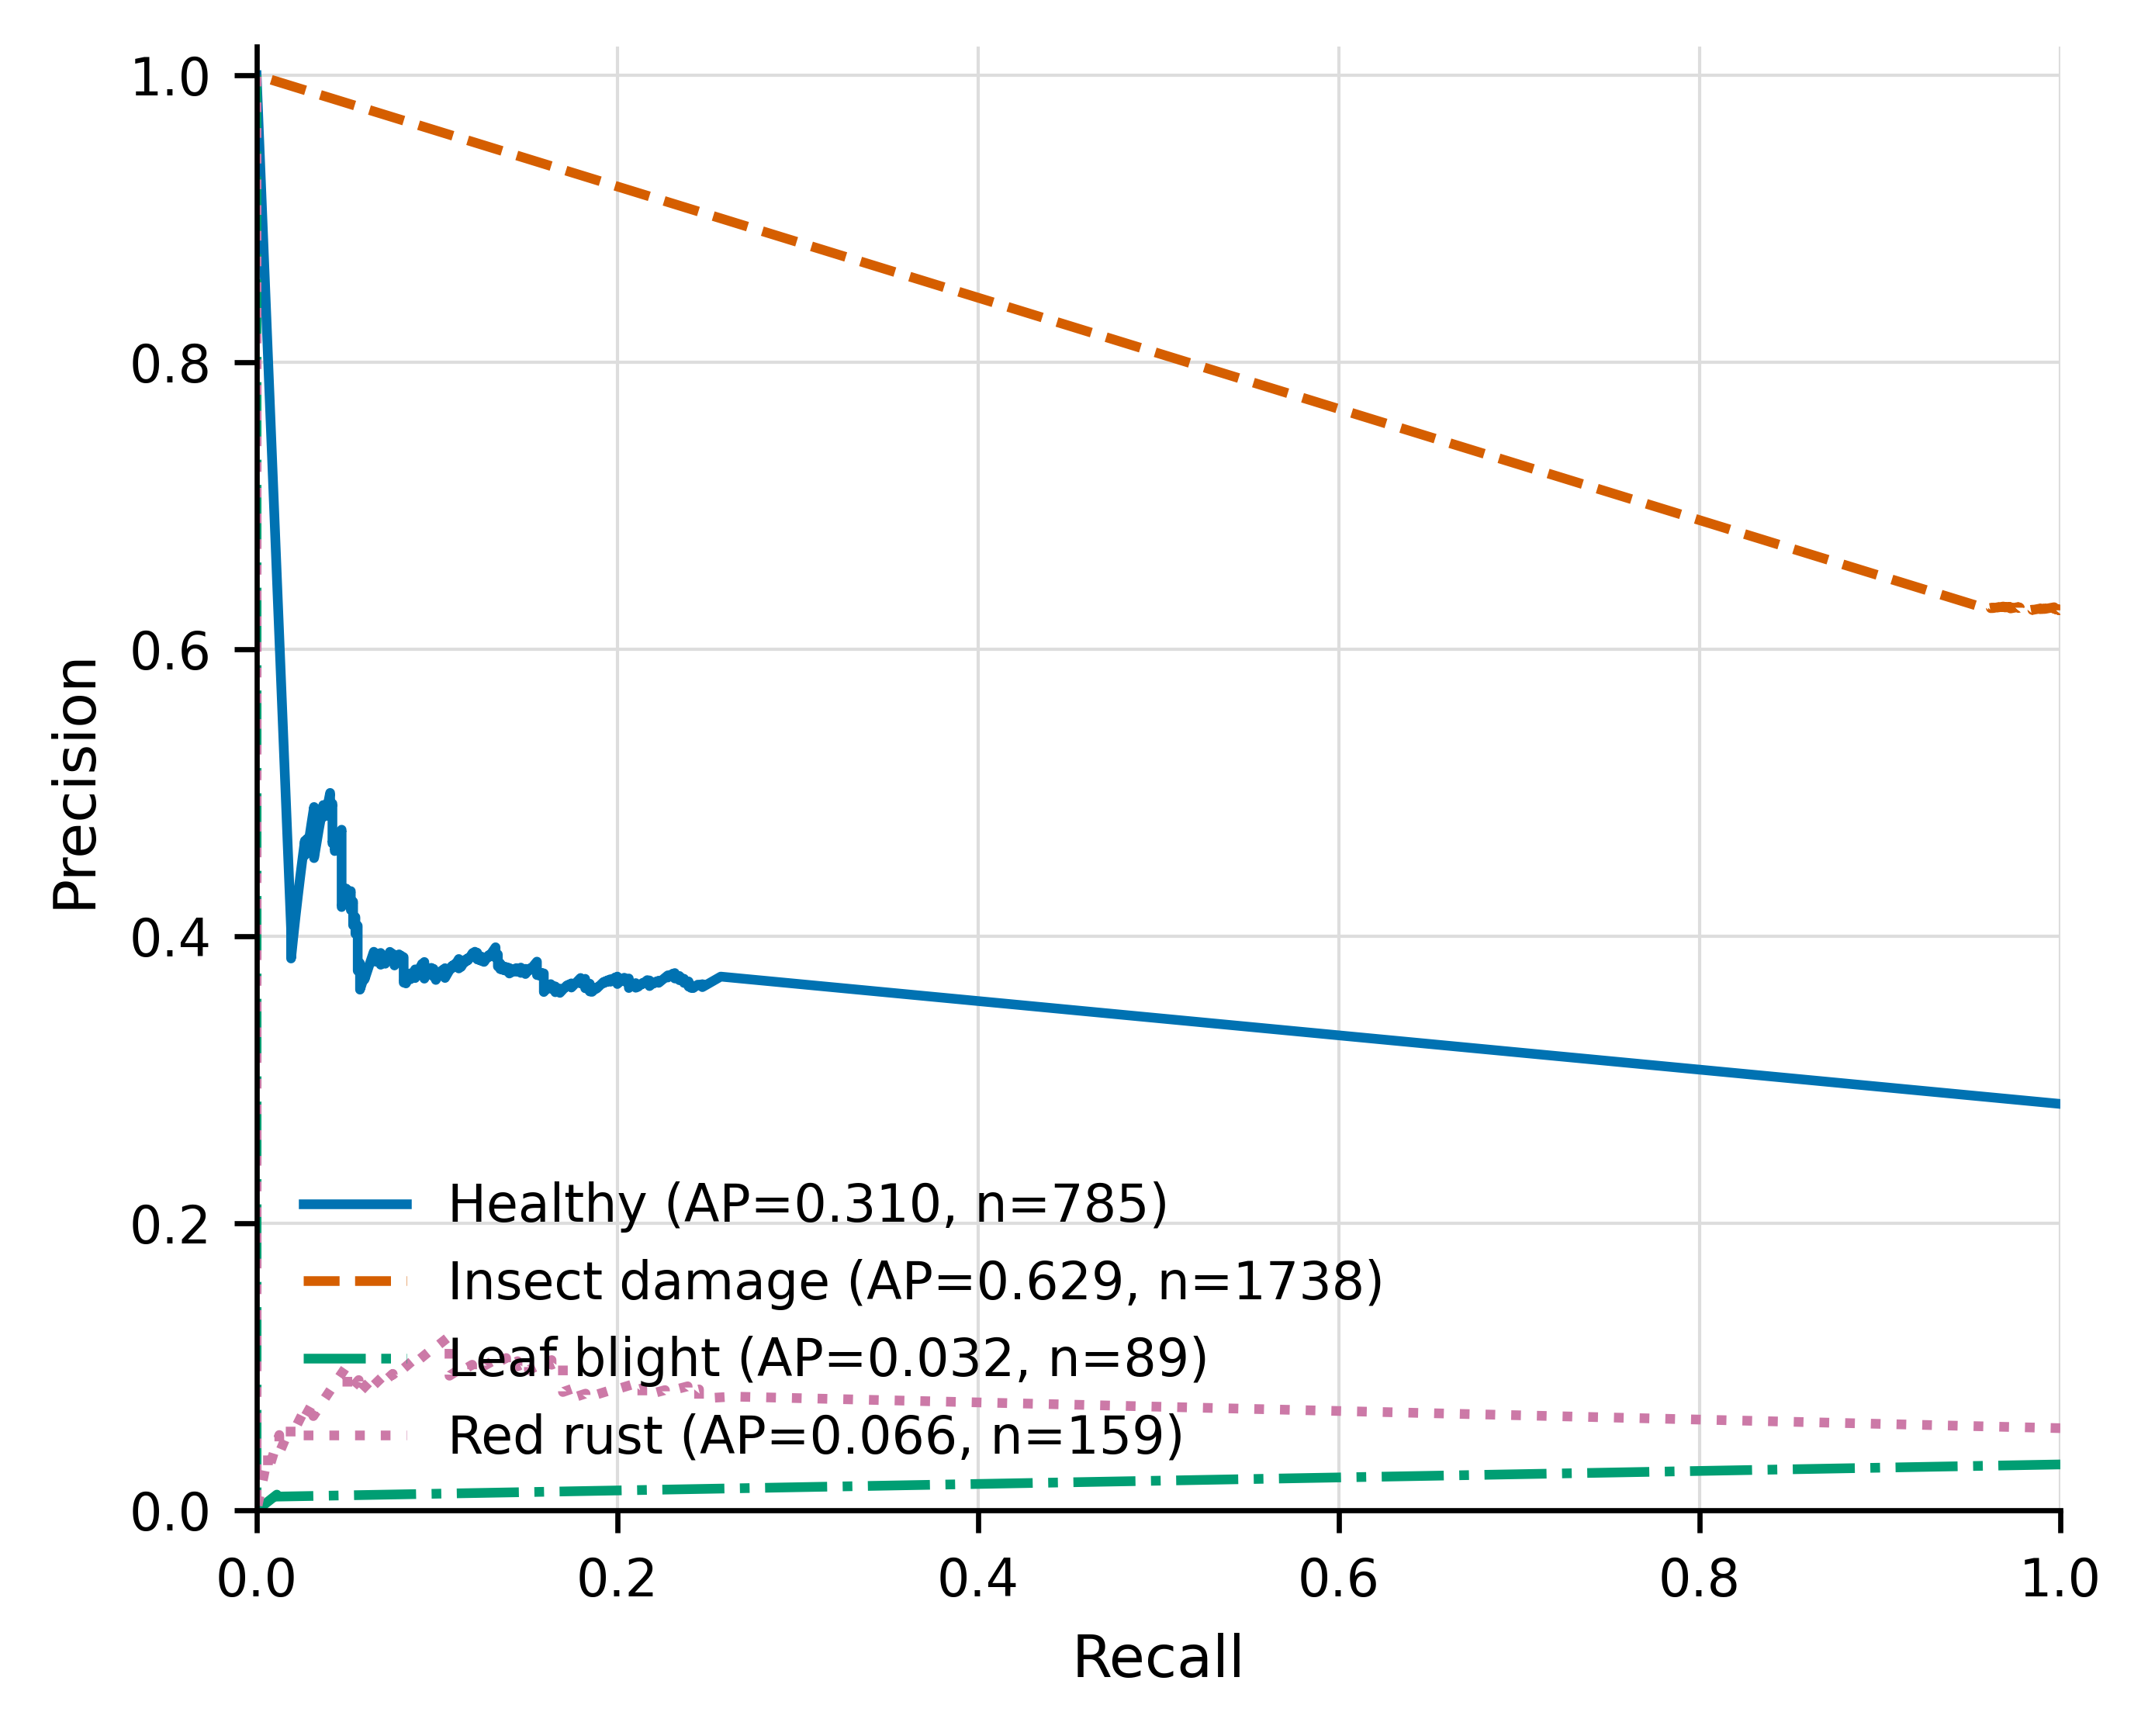

,class,support,prevalence,average_precision
0,healthy,785,0.2833,0.3105
1,insect_damage,1738,0.6272,0.6288
2,leaf_blight,89,0.0321,0.0319
3,red_rust,159,0.0574,0.0659


In [38]:
# Configure 600 DPI inline display in Google Colab
%config InlineBackend.figure_format = 'png'

import matplotlib as mpl

# Ensure 600 DPI for display and saved raster figures
PUBLICATION_STYLE.update({
    "figure.dpi": 600,
    "savefig.dpi": 600,
})

frame = external_score_frames[BEST_NAME]

known_predictions = frame[
    frame["evaluation_group"].eq("known")
].copy()

CLASS_DISPLAY = {
    "healthy": "Healthy",
    "insect_damage": "Insect damage",
    "leaf_blight": "Leaf blight",
    "red_rust": "Red rust",
}

class_colors = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
]

class_linestyles = ["-", "--", "-.", ":"]

precision_recall_rows = []

with mpl.rc_context(PUBLICATION_STYLE):

    fig, axis = plt.subplots(
        figsize=(119 / 25.4, 3.8)
    )

    for class_id, label in enumerate(CLASSES):

        binary_labels = (
            known_predictions["target"].eq(class_id)
        ).astype(int).to_numpy()

        probabilities = known_predictions[
            f"prob_{label}"
        ].to_numpy()

        precision, recall, _ = precision_recall_curve(
            binary_labels,
            probabilities
        )

        ap = average_precision_score(
            binary_labels,
            probabilities
        )

        support = int(binary_labels.sum())

        axis.plot(
            recall,
            precision,
            color=class_colors[class_id],
            linestyle=class_linestyles[class_id],
            linewidth=1.5,
            label=(
                f"{CLASS_DISPLAY[label]} "
                f"(AP={ap:.3f}, n={support})"
            )
        )

        precision_recall_rows.append({
            "class": label,
            "support": support,
            "prevalence": float(binary_labels.mean()),
            "average_precision": float(ap),
        })

    axis.set(
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.02)
    )

    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.grid(color="#DDDDDD", linewidth=0.5)

    axis.legend(
        loc="lower left",
        frameon=False
    )

    fig.tight_layout()

    # Save PNG, PDF, and EPS at 600 DPI
    save_extended_figure(
        fig,
        f"external_precision_recall_{BEST_NAME}"
    )

    # Display at 600 DPI in Google Colab
    plt.show()
    plt.close(fig)

precision_recall_table = pd.DataFrame(
    precision_recall_rows
)

precision_recall_table.to_csv(
    EXT_OUT / "external_average_precision_by_class.csv",
    index=False
)

display(precision_recall_table.round(4))

Cell 34 — Bootstrap uncertainty for referral results
This resamples external image families. The intervals describe uncertainty within this collection and its grouping scheme.

In [40]:
frame = external_score_frames[
    BEST_NAME
].reset_index(drop=True)

family_positions = frame.groupby(
    "audit_group"
).indices

family_names = list(family_positions)

rng = np.random.default_rng(SEED)

BOOTSTRAP_REPLICATES = 1000
bootstrap_rows = []

for iteration in tqdm(
    range(BOOTSTRAP_REPLICATES),
    desc="Image-family bootstrap"
):

    sampled_families = rng.choice(
        family_names,
        size=len(family_names),
        replace=True
    )

    positions = np.concatenate([
        family_positions[name]
        for name in sampled_families
    ])

    sample = frame.iloc[positions]

    known = sample["evaluation_group"].eq("known").to_numpy()
    additional = (
        sample["evaluation_group"].eq("additional").to_numpy()
    )
    mixed = sample["evaluation_group"].eq("mixed").to_numpy()

    correct = (
        sample["target"].to_numpy()
        == sample["predicted_id"].to_numpy()
    )

    healthy = (
        sample["predicted_id"].to_numpy()
        == CLASS_TO_ID["healthy"]
    )

    for method in SCORE_METHODS:

        accepted = sample[
            f"accept_{method}"
        ].to_numpy()

        bootstrap_rows.append({
            "replicate": iteration,
            "method": method,
            "known_acceptance": masked_rate(
                accepted, known
            ),
            "known_selective_accuracy": masked_rate(
                correct, known & accepted
            ),
            "known_correct_accepted_rate": masked_rate(
                correct & accepted, known
            ),
            "additional_false_acceptance": masked_rate(
                accepted, additional
            ),
            "additional_false_healthy_rate": masked_rate(
                accepted & healthy, additional
            ),
            "mixed_referral_rate": masked_rate(
                ~accepted, mixed
            ),
        })

bootstrap_results = pd.DataFrame(bootstrap_rows)

interval_rows = []

metric_names = [
    "known_acceptance",
    "known_selective_accuracy",
    "known_correct_accepted_rate",
    "additional_false_acceptance",
    "additional_false_healthy_rate",
    "mixed_referral_rate",
]

for method in SCORE_METHODS:

    point_row = comparison_table[
        comparison_table["model"].eq(BEST_NAME)
        & comparison_table["method"].eq(method)
    ].iloc[0]

    repetitions = bootstrap_results[
        bootstrap_results["method"].eq(method)
    ]

    for metric in metric_names:

        values = repetitions[metric].dropna()

        if len(values):
            lower, upper = np.quantile(
                values, [0.025, 0.975]
            )
        else:
            lower, upper = np.nan, np.nan

        interval_rows.append({
            "model": BEST_NAME,
            "method": method,
            "metric": metric,
            "estimate": point_row[metric],
            "lower_95": lower,
            "upper_95": upper,
            "valid_bootstrap_replicates": len(values),
        })

interval_table = pd.DataFrame(interval_rows)

interval_table.to_csv(
    EXT_OUT / "selected_model_bootstrap_intervals.csv",
    index=False
)

display(interval_table.round(4))

Image-family bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

,model,method,metric,estimate,lower_95,upper_95,valid_bootstrap_replicates
0,mobilenet_v3_small,raw_confidence,known_acceptance,0.7784,0.7625,0.7935,1000
1,mobilenet_v3_small,raw_confidence,known_selective_accuracy,0.6338,0.6131,0.6534,1000
2,mobilenet_v3_small,raw_confidence,known_correct_accepted_rate,0.4933,0.4734,0.5121,1000
3,mobilenet_v3_small,raw_confidence,additional_false_acceptance,0.7830,0.7658,0.8006,1000
4,mobilenet_v3_small,raw_confidence,additional_false_healthy_rate,0.0000,0.0000,0.0000,1000
5,mobilenet_v3_small,raw_confidence,mixed_referral_rate,0.1769,0.1150,0.2431,1000
6,mobilenet_v3_small,calibrated_confidence,known_acceptance,0.9719,0.9656,0.9776,1000
7,mobilenet_v3_small,calibrated_confidence,known_selective_accuracy,0.6238,0.6051,0.6415,1000
8,mobilenet_v3_small,calibrated_confidence,known_correct_accepted_rate,0.6063,0.5878,0.6242,1000
9,mobilenet_v3_small,calibrated_confidence,additional_false_acceptance,0.9791,0.9728,0.9846,1000


Cell 34A - Statistical comparisons and publication figure

External images: 2,774
Image families: 2,698
Cohort: original Cell 17 external test set
Intervals describe evaluation-sample uncertainty for fixed trained models.


Completed 1,000 bootstrap replicates
Completed 2,000 bootstrap replicates
Completed 3,000 bootstrap replicates
Bootstrap draws omitted for missing classes: 0

External classification performance with image-family bootstrap intervals


,Model,Metric,Estimate (95% CI)
0,MobileNetV3-Small,Accuracy,"0.6186 (0.6000, 0.6374)"
1,MobileNetV3-Small,Balanced accuracy,"0.2511 (0.2474, 0.2549)"
2,MobileNetV3-Small,Macro-F1,"0.2057 (0.1988, 0.2131)"
3,MobileNetV3-Small,Recall: healthy,"0.0318 (0.0200, 0.0457)"
4,MobileNetV3-Small,Recall: insect damage,"0.9724 (0.9644, 0.9800)"
5,MobileNetV3-Small,Recall: leaf blight,"0.0000 (0.0000, 0.0000)"
6,MobileNetV3-Small,Recall: red rust,"0.0000 (0.0000, 0.0000)"
7,EfficientNetV2-S,Accuracy,"0.5908 (0.5724, 0.6096)"
8,EfficientNetV2-S,Balanced accuracy,"0.3275 (0.3079, 0.3475)"
9,EfficientNetV2-S,Macro-F1,"0.2998 (0.2842, 0.3161)"



COPYABLE TABLE:

| Model             | Metric                | Estimate (95% CI)       |
|:------------------|:----------------------|:------------------------|
| MobileNetV3-Small | Accuracy              | 0.6186 (0.6000, 0.6374) |
| MobileNetV3-Small | Balanced accuracy     | 0.2511 (0.2474, 0.2549) |
| MobileNetV3-Small | Macro-F1              | 0.2057 (0.1988, 0.2131) |
| MobileNetV3-Small | Recall: healthy       | 0.0318 (0.0200, 0.0457) |
| MobileNetV3-Small | Recall: insect damage | 0.9724 (0.9644, 0.9800) |
| MobileNetV3-Small | Recall: leaf blight   | 0.0000 (0.0000, 0.0000) |
| MobileNetV3-Small | Recall: red rust      | 0.0000 (0.0000, 0.0000) |
| EfficientNetV2-S  | Accuracy              | 0.5908 (0.5724, 0.6096) |
| EfficientNetV2-S  | Balanced accuracy     | 0.3275 (0.3079, 0.3475) |
| EfficientNetV2-S  | Macro-F1              | 0.2998 (0.2842, 0.3161) |
| EfficientNetV2-S  | Recall: healthy       | 0.1807 (0.1527, 0.2114) |
| EfficientNetV2-S  | Recall: insect damage | 

,Comparison,Metric,Difference (95% CI),Two-sided permutation p
0,EfficientNetV2-S minus MobileNetV3-Small,External macro-F1,"0.0941 (0.0781, 0.1104)",0.0002



COPYABLE TABLE:

| Comparison                               | Metric            | Difference (95% CI)     |   Two-sided permutation p |
|:-----------------------------------------|:------------------|:------------------------|--------------------------:|
| EfficientNetV2-S minus MobileNetV3-Small | External macro-F1 | 0.0941 (0.0781, 0.1104) |                    0.0002 |

LATEX TABLE:

\begin{tabular}{llll}
\toprule
Comparison & Metric & Difference (95\% CI) & Two-sided permutation p \\
\midrule
EfficientNetV2-S minus MobileNetV3-Small & External macro-F1 & 0.0941 (0.0781, 0.1104) & 0.0002 \\
\bottomrule
\end{tabular}


Change in external probability errors after temperature scaling


,Model,Metric,Scaled minus raw (95% CI)
0,MobileNetV3-Small,Log loss,"10.1317 (9.6122, 10.6658)"
1,MobileNetV3-Small,Multiclass Brier,"0.0302 (0.0244, 0.0362)"
2,EfficientNetV2-S,Log loss,"9.5511 (9.0500, 10.0500)"
3,EfficientNetV2-S,Multiclass Brier,"0.1461 (0.1334, 0.1594)"



COPYABLE TABLE:

| Model             | Metric           | Scaled minus raw (95% CI)   |
|:------------------|:-----------------|:----------------------------|
| MobileNetV3-Small | Log loss         | 10.1317 (9.6122, 10.6658)   |
| MobileNetV3-Small | Multiclass Brier | 0.0302 (0.0244, 0.0362)     |
| EfficientNetV2-S  | Log loss         | 9.5511 (9.0500, 10.0500)    |
| EfficientNetV2-S  | Multiclass Brier | 0.1461 (0.1334, 0.1594)     |

LATEX TABLE:

\begin{tabular}{lll}
\toprule
Model & Metric & Scaled minus raw (95\% CI) \\
\midrule
MobileNetV3-Small & Log loss & 10.1317 (9.6122, 10.6658) \\
MobileNetV3-Small & Multiclass Brier & 0.0302 (0.0244, 0.0362) \\
EfficientNetV2-S & Log loss & 9.5511 (9.0500, 10.0500) \\
EfficientNetV2-S & Multiclass Brier & 0.1461 (0.1334, 0.1594) \\
\bottomrule
\end{tabular}



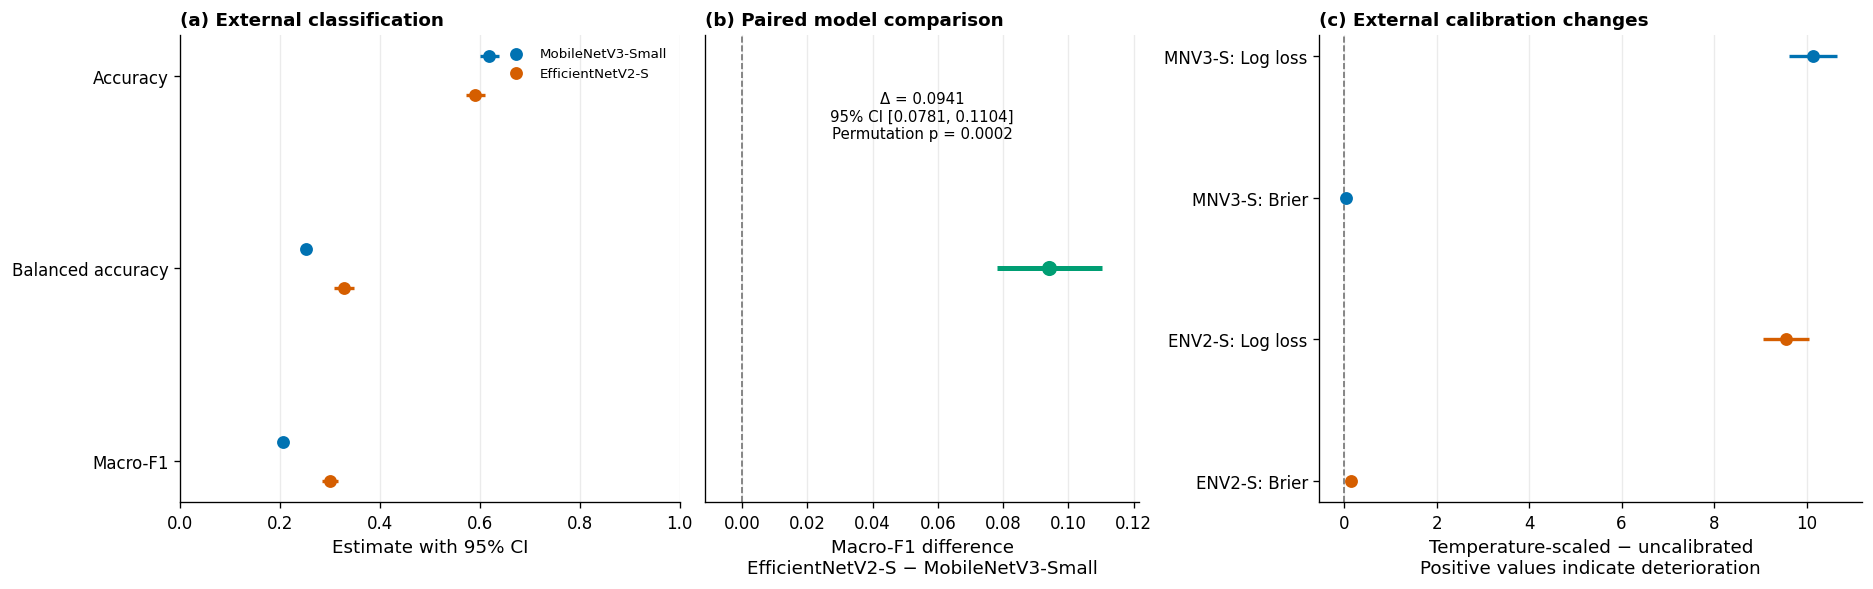


Primary comparison:
External macro-F1 difference = 0.0941 (9.41 percentage points)
95% paired bootstrap CI: [0.0781, 0.1104]
Two-sided grouped permutation p = 0.0002

Files saved to: /content/litchi_study/outputs/statistical_analysis
600 dpi figure: /content/litchi_study/outputs/statistical_analysis/figures/external_statistical_analysis.png

Report the effect size, interval, and p-value together. This analysis does not establish superiority across other orchards.


In [41]:
# ============================================================
# Statistical analysis: external performance and calibration
# Paired image-family bootstrap + primary permutation test
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax
from IPython.display import display

# ----------------------------
# Settings
# ----------------------------
STAT_SEED = 2026
N_BOOTSTRAP = 3000
N_PERMUTATIONS = 5000
DPI = 600

MODEL_NAMES = ["mobilenet_v3_small", "efficientnet_v2_s"]

MODEL_DISPLAY = {
    "mobilenet_v3_small": "MobileNetV3-Small",
    "efficientnet_v2_s": "EfficientNetV2-S",
}

STAT_OUT = Path(OUT) / "statistical_analysis"
STAT_FIG = STAT_OUT / "figures"
STAT_FIG.mkdir(parents=True, exist_ok=True)

# Defaults also apply to subsequent Matplotlib figures.
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": DPI,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

required = [
    "prediction_frames", "SPLITS", "loaders",
    "load_checkpoint", "collect_logits",
    "temperatures", "CLASSES"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the earlier evaluation cells first. Missing: "
        + ", ".join(missing)
    )

K = len(CLASSES)
if K != 4:
    raise ValueError("This analysis expects the four matched classes.")

# ----------------------------
# Align predictions and groups
# ----------------------------
reference = prediction_frames[
    (MODEL_NAMES[0], "external_test")
].reset_index(drop=True).copy()

if "group" not in reference:
    raise ValueError(
        "The external manifest must contain image-family 'group' IDs. "
        "Do not replace them with individual image IDs."
    )

if reference["group"].isna().any():
    raise ValueError("Some external image-family group IDs are missing.")

reference_paths = reference["path"].astype(str).tolist()
y = reference["target"].to_numpy(dtype=int)

if not np.isin(y, np.arange(K)).all():
    raise ValueError("External targets must be integers from 0 to K-1.")

split_frame = SPLITS["external_test"].reset_index(drop=True)

if split_frame["path"].astype(str).tolist() != reference_paths:
    raise ValueError(
        "External loader manifest order differs from prediction order."
    )

for name in MODEL_NAMES:
    frame = prediction_frames[
        (name, "external_test")
    ].reset_index(drop=True)

    if frame["path"].astype(str).tolist() != reference_paths:
        raise ValueError(f"Image order differs for {name}.")

    if not np.array_equal(frame["target"].to_numpy(dtype=int), y):
        raise ValueError(f"Reference labels differ for {name}.")

    if frame["group"].astype(str).tolist() != (
        reference["group"].astype(str).tolist()
    ):
        raise ValueError(f"Image-family IDs differ for {name}.")

group_code, group_values = pd.factorize(
    reference["group"], sort=False
)

G = len(group_values)
N = len(reference)

if G < 2:
    raise ValueError("At least two image families are required.")

group_sizes = np.bincount(group_code, minlength=G).astype(float)

print(f"External images: {N:,}")
print(f"Image families: {G:,}")
print("Cohort: original Cell 17 external test set")
print(
    "Intervals describe evaluation-sample uncertainty "
    "for fixed trained models."
)

# ----------------------------
# Recompute raw/calibrated probabilities
# Inference only: no retraining or threshold fitting
# ----------------------------
probabilities = {}
predictions = {}

for name in MODEL_NAMES:
    print(f"\nCollecting fixed-model predictions: {name}")

    model = load_checkpoint(name)
    logits, observed_y = collect_logits(
        model, loaders["external_test"]
    )

    logits = np.asarray(logits, dtype=np.float64)
    observed_y = np.asarray(observed_y, dtype=int)

    if logits.shape != (N, K):
        raise ValueError(f"Unexpected logit dimensions for {name}.")

    if not np.array_equal(observed_y, y):
        raise ValueError(
            "External loader must use shuffle=False "
            "and match the saved manifest."
        )

    if not np.isfinite(logits).all():
        raise ValueError(f"Non-finite logits found for {name}.")

    temperature = float(temperatures[name])
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError(f"Invalid temperature for {name}.")

    raw = softmax(logits, axis=1)
    calibrated = softmax(logits / temperature, axis=1)

    probabilities[name] = {
        "raw": raw,
        "calibrated": calibrated,
    }

    predictions[name] = raw.argmax(axis=1)

    saved_pred = prediction_frames[
        (name, "external_test")
    ]["predicted_id"].to_numpy(dtype=int)

    if not np.array_equal(predictions[name], saved_pred):
        raise ValueError(
            f"Recomputed predictions differ from Cell 17 for {name}. "
            "Check checkpoint consistency before proceeding."
        )

    del model

# ----------------------------
# Group-level sufficient statistics
# ----------------------------
def grouped_confusion(pred):
    encoded = group_code * (K * K) + y * K + pred
    return np.bincount(
        encoded, minlength=G * K * K
    ).reshape(G, K * K).astype(float)


def grouped_sum(values):
    return np.bincount(
        group_code,
        weights=np.asarray(values, dtype=float),
        minlength=G,
    )


def per_image_losses(prob):
    # Matches the usual floating-point clipping convention.
    eps = np.finfo(prob.dtype).eps
    clipped = np.clip(prob, eps, 1.0 - eps)
    clipped = clipped / clipped.sum(axis=1, keepdims=True)

    logloss = -np.log(clipped[np.arange(N), y])

    onehot = np.eye(K)[y]
    brier = np.sum((prob - onehot) ** 2, axis=1)

    return logloss, brier


METRIC_NAMES = (
    ["Accuracy", "Balanced accuracy", "Macro-F1"]
    + ["Recall: " + label.replace("_", " ") for label in CLASSES]
)


def metrics_from_cm(flat_cm):
    cm = np.asarray(flat_cm).reshape(K, K)
    true_n = cm.sum(axis=1)
    pred_n = cm.sum(axis=0)
    tp = np.diag(cm)

    recall = np.divide(
        tp, true_n,
        out=np.zeros(K, dtype=float),
        where=true_n > 0,
    )

    class_f1 = np.divide(
        2 * tp, true_n + pred_n,
        out=np.zeros(K, dtype=float),
        where=(true_n + pred_n) > 0,
    )

    return np.r_[
        tp.sum() / cm.sum(),
        recall.mean(),
        class_f1.mean(),
        recall,
    ]


group_cm = {}
point_metrics = {}
group_loss_difference = {}
point_loss_difference = {}

for name in MODEL_NAMES:
    group_cm[name] = grouped_confusion(predictions[name])
    point_metrics[name] = metrics_from_cm(group_cm[name].sum(axis=0))

    raw_ll, raw_bs = per_image_losses(probabilities[name]["raw"])
    cal_ll, cal_bs = per_image_losses(
        probabilities[name]["calibrated"]
    )

    # Positive differences mean calibration made errors larger.
    group_loss_difference[name] = np.column_stack([
        grouped_sum(cal_ll - raw_ll),
        grouped_sum(cal_bs - raw_bs),
    ])

    point_loss_difference[name] = (
        group_loss_difference[name].sum(axis=0) / N
    )

# ----------------------------
# Paired image-family bootstrap
# Same family draws for both models and both settings
# ----------------------------
rng = np.random.default_rng(STAT_SEED)

boot_metrics = {
    name: np.empty((N_BOOTSTRAP, len(METRIC_NAMES)))
    for name in MODEL_NAMES
}

boot_loss_difference = {
    name: np.empty((N_BOOTSTRAP, 2))
    for name in MODEL_NAMES
}

accepted = 0
attempts = 0

while accepted < N_BOOTSTRAP:
    attempts += 1

    if attempts > N_BOOTSTRAP * 20:
        raise RuntimeError(
            "Too many bootstrap samples lacked one or more classes. "
            "Review class support and group structure."
        )

    sampled_groups = rng.integers(0, G, size=G)
    weights = np.bincount(
        sampled_groups, minlength=G
    ).astype(float)

    # Require all four categories for fixed-class comparisons.
    sampled_cm = (
        weights @ group_cm[MODEL_NAMES[0]]
    ).reshape(K, K)

    if (sampled_cm.sum(axis=1) == 0).any():
        continue

    sampled_n = weights @ group_sizes

    for name in MODEL_NAMES:
        boot_metrics[name][accepted] = metrics_from_cm(
            weights @ group_cm[name]
        )

        boot_loss_difference[name][accepted] = (
            weights @ group_loss_difference[name]
        ) / sampled_n

    accepted += 1

    if accepted % 1000 == 0:
        print(f"Completed {accepted:,} bootstrap replicates")

print(
    f"Bootstrap draws omitted for missing classes: "
    f"{attempts - N_BOOTSTRAP:,}"
)

# ----------------------------
# Primary paired permutation test
# EfficientNetV2-S minus MobileNetV3-Small macro-F1
# Swap complete predictions within each image family.
# ----------------------------
first, second = MODEL_NAMES

point_delta = point_metrics[second][2] - point_metrics[first][2]
boot_delta = (
    boot_metrics[second][:, 2] - boot_metrics[first][:, 2]
)

delta_low, delta_high = np.quantile(
    boot_delta, [0.025, 0.975]
)

permutation_rng = np.random.default_rng(STAT_SEED + 1)
permutation_delta = np.empty(N_PERMUTATIONS)

cm_first = group_cm[first].sum(axis=0)
cm_second = group_cm[second].sum(axis=0)
family_difference = group_cm[second] - group_cm[first]

for iteration in range(N_PERMUTATIONS):
    swap = permutation_rng.integers(0, 2, size=G)
    change = swap @ family_difference

    perm_first = cm_first + change
    perm_second = cm_second - change

    permutation_delta[iteration] = (
        metrics_from_cm(perm_second)[2]
        - metrics_from_cm(perm_first)[2]
    )

# Two-sided Monte Carlo p-value, including +1 correction.
p_value = (
    1 + np.count_nonzero(
        np.abs(permutation_delta) >= abs(point_delta) - 1e-12
    )
) / (N_PERMUTATIONS + 1)

# ----------------------------
# Build output tables
# ----------------------------
performance_rows = []

for name in MODEL_NAMES:
    intervals = np.quantile(
        boot_metrics[name], [0.025, 0.975], axis=0
    )

    for index, metric in enumerate(METRIC_NAMES):
        performance_rows.append({
            "Model": MODEL_DISPLAY[name],
            "Metric": metric,
            "Estimate": point_metrics[name][index],
            "CI_low": intervals[0, index],
            "CI_high": intervals[1, index],
            "n_images": N,
            "n_families": G,
        })

performance_table = pd.DataFrame(performance_rows)

comparison_table = pd.DataFrame([{
    "Comparison": "EfficientNetV2-S minus MobileNetV3-Small",
    "Metric": "External macro-F1",
    "Difference": point_delta,
    "CI_low": delta_low,
    "CI_high": delta_high,
    "Permutation_p": p_value,
}])

calibration_rows = []

for name in MODEL_NAMES:
    intervals = np.quantile(
        boot_loss_difference[name], [0.025, 0.975], axis=0
    )

    for index, metric in enumerate(["Log loss", "Multiclass Brier"]):
        calibration_rows.append({
            "Model": MODEL_DISPLAY[name],
            "Metric": metric,
            "Difference": point_loss_difference[name][index],
            "CI_low": intervals[0, index],
            "CI_high": intervals[1, index],
        })

calibration_table = pd.DataFrame(calibration_rows)

# ----------------------------
# Print copyable publication tables
# ----------------------------
def print_and_export(numeric_table, formatted_table, stem, title):
    numeric_table.to_csv(
        STAT_OUT / f"{stem}.csv", index=False
    )

    formatted_table.to_latex(
        STAT_OUT / f"{stem}.tex",
        index=False,
        escape=True,
        caption=title,
        label=f"tab:{stem.replace('_', '-')}",
    )

    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)

    display(formatted_table)

    print("\nCOPYABLE TABLE:\n")
    try:
        print(formatted_table.to_markdown(index=False))
    except ImportError:
        print(formatted_table.to_string(index=False))

    print("\nLATEX TABLE:\n")
    print(formatted_table.to_latex(index=False, escape=True))


performance_print = performance_table[["Model", "Metric"]].copy()
performance_print["Estimate (95% CI)"] = [
    f"{estimate:.4f} ({low:.4f}, {high:.4f})"
    for estimate, low, high in zip(
        performance_table.Estimate,
        performance_table.CI_low,
        performance_table.CI_high,
    )
]

comparison_print = comparison_table[["Comparison", "Metric"]].copy()
comparison_print["Difference (95% CI)"] = [
    f"{point_delta:.4f} ({delta_low:.4f}, {delta_high:.4f})"
]
comparison_print["Two-sided permutation p"] = [f"{p_value:.4f}"]

calibration_print = calibration_table[["Model", "Metric"]].copy()
calibration_print["Scaled minus raw (95% CI)"] = [
    f"{estimate:.4f} ({low:.4f}, {high:.4f})"
    for estimate, low, high in zip(
        calibration_table.Difference,
        calibration_table.CI_low,
        calibration_table.CI_high,
    )
]

print_and_export(
    performance_table,
    performance_print,
    "external_performance_uncertainty",
    "External classification performance with image-family bootstrap intervals",
)

print_and_export(
    comparison_table,
    comparison_print,
    "paired_model_comparison",
    "Paired comparison of external macro-F1",
)

print_and_export(
    calibration_table,
    calibration_print,
    "paired_calibration_comparison",
    "Change in external probability errors after temperature scaling",
)

# ----------------------------
# Publication figure: three panels
# ----------------------------
colors = {
    first: "#0072B2",
    second: "#D55E00",
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(15.5, 4.8),
    gridspec_kw={"width_ratios": [1.15, 1.0, 1.25]},
    constrained_layout=True,
)

# (a) External classification performance
ax = axes[0]
metric_positions = np.arange(3)

for offset, name in zip([-0.10, 0.10], MODEL_NAMES):
    estimates = point_metrics[name][:3]
    low, high = np.quantile(
        boot_metrics[name][:, :3],
        [0.025, 0.975],
        axis=0,
    )

    positions = metric_positions + offset

    ax.hlines(
        positions, low, high,
        color=colors[name], linewidth=2,
    )
    ax.scatter(
        estimates, positions,
        color=colors[name], s=45,
        label=MODEL_DISPLAY[name], zorder=3,
    )

ax.set_yticks(metric_positions)
ax.set_yticklabels(["Accuracy", "Balanced accuracy", "Macro-F1"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Estimate with 95% CI")
ax.set_title("(a) External classification", loc="left", fontweight="bold")
ax.legend(loc="best", frameon=False, fontsize=8)

# (b) Paired difference in external macro-F1
ax = axes[1]

ax.axvline(0, color="0.45", linestyle="--", linewidth=1)
ax.hlines(0, delta_low, delta_high, color="#009E73", linewidth=3)
ax.scatter([point_delta], [0], color="#009E73", s=65, zorder=3)

ax.set_yticks([])
ax.set_ylim(-0.8, 0.8)

span = max(delta_high - delta_low, 0.02)
ax.set_xlim(
    min(0, delta_low) - span * 0.35,
    max(0, delta_high) + span * 0.35,
)

ax.set_xlabel("Macro-F1 difference\nEfficientNetV2-S − MobileNetV3-Small")
ax.set_title("(b) Paired model comparison", loc="left", fontweight="bold")

ax.text(
    0.5, 0.88,
    f"Δ = {point_delta:.4f}\n"
    f"95% CI [{delta_low:.4f}, {delta_high:.4f}]\n"
    f"Permutation p = {p_value:.4f}",
    transform=ax.transAxes,
    ha="center", va="top",
    fontsize=9,
)

# (c) Calibration changes
ax = axes[2]
ax.axvline(0, color="0.45", linestyle="--", linewidth=1)

cal_labels = []

for position, row in calibration_table.iterrows():
    model_key = (
        first if row["Model"] == MODEL_DISPLAY[first] else second
    )

    ax.hlines(
        position,
        row["CI_low"],
        row["CI_high"],
        color=colors[model_key],
        linewidth=2,
    )
    ax.scatter(
        row["Difference"],
        position,
        color=colors[model_key],
        s=45, zorder=3,
    )

    short_name = "MNV3-S" if model_key == first else "ENV2-S"
    short_metric = (
        "Log loss" if row["Metric"] == "Log loss" else "Brier"
    )
    cal_labels.append(f"{short_name}: {short_metric}")

ax.set_yticks(np.arange(len(cal_labels)))
ax.set_yticklabels(cal_labels)
ax.invert_yaxis()
ax.set_xlabel("Temperature-scaled − uncalibrated\nPositive values indicate deterioration")
ax.set_title("(c) External calibration changes", loc="left", fontweight="bold")

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

figure_path = STAT_FIG / "external_statistical_analysis.png"

fig.savefig(
    figure_path,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white",
)

# Vector version for publication.
fig.savefig(
    STAT_FIG / "external_statistical_analysis.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

# ----------------------------
# Save reproducibility information
# ----------------------------
np.savez_compressed(
    STAT_OUT / "statistical_resampling_distributions.npz",
    **{
        f"{name}_classification": boot_metrics[name]
        for name in MODEL_NAMES
    },
    **{
        f"{name}_calibration_difference": boot_loss_difference[name]
        for name in MODEL_NAMES
    },
    paired_macro_f1_difference=boot_delta,
    permutation_macro_f1_difference=permutation_delta,
)

metadata = {
    "cohort": "Cell 17 external_test",
    "n_images": N,
    "n_image_families": G,
    "classes": list(CLASSES),
    "bootstrap_replicates": N_BOOTSTRAP,
    "bootstrap_interval": "95% percentile",
    "bootstrap_unit": "image-family group",
    "bootstrap_draws_without_all_classes_omitted":
        attempts - N_BOOTSTRAP,
    "permutation_replicates": N_PERMUTATIONS,
    "permutation_unit": "whole image-family prediction swap",
    "primary_comparison": "external macro-F1: EfficientNetV2-S minus MobileNetV3-Small",
    "permutation_alternative": "two-sided",
    "random_seed": STAT_SEED,
    "figure_dpi": DPI,
    "limitation": (
        "Fixed-model evaluation-sample uncertainty. "
        "Does not quantify training-seed, orchard, or region variability."
    ),
}

(STAT_OUT / "statistical_analysis_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("\nPrimary comparison:")
print(
    f"External macro-F1 difference = {point_delta:.4f} "
    f"({100 * point_delta:.2f} percentage points)"
)
print(f"95% paired bootstrap CI: [{delta_low:.4f}, {delta_high:.4f}]")
print(f"Two-sided grouped permutation p = {p_value:.4f}")

print("\nFiles saved to:", STAT_OUT)
print("600 dpi figure:", figure_path)
print(
    "\nReport the effect size, interval, and p-value together. "
    "This analysis does not establish superiority across other orchards."
)

Cell 35 — Explain confidently accepted unrepresented conditions
This reuses the Grad-CAM functions from Cell 21. It selects the most confident accepted example from each additional or mixed category under calibrated-confidence referral.

These are deliberately selected failure illustrations.

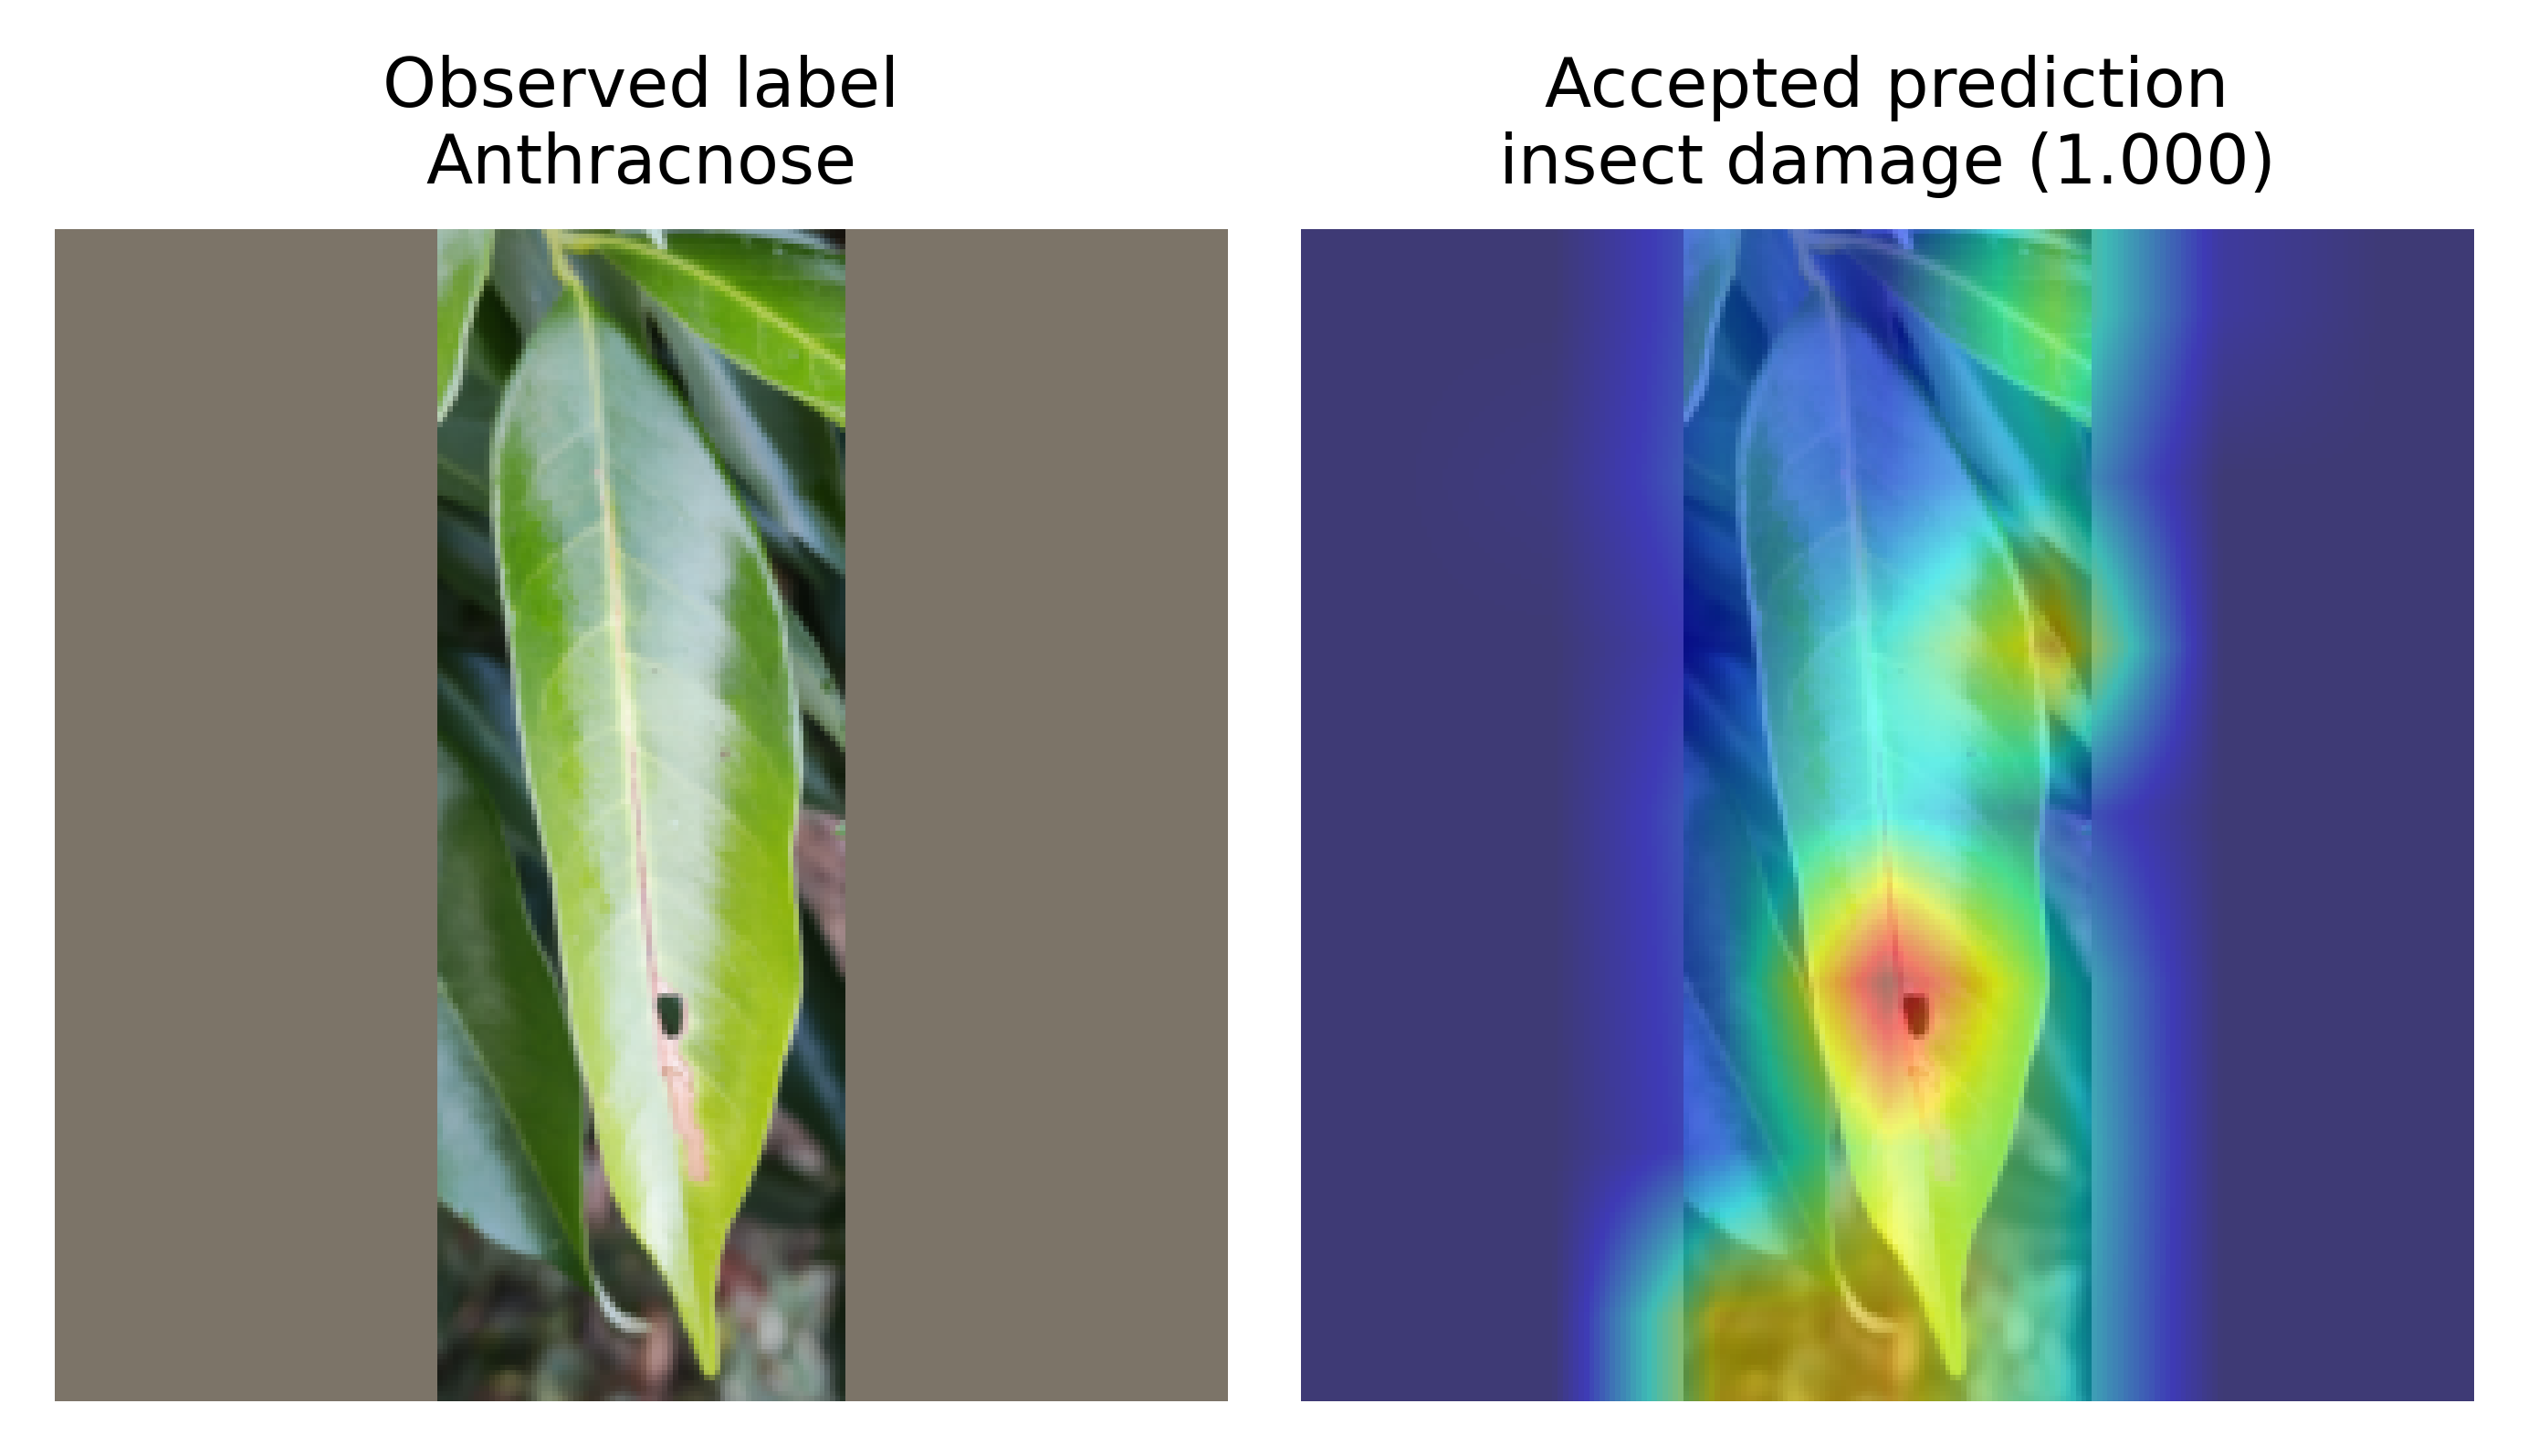

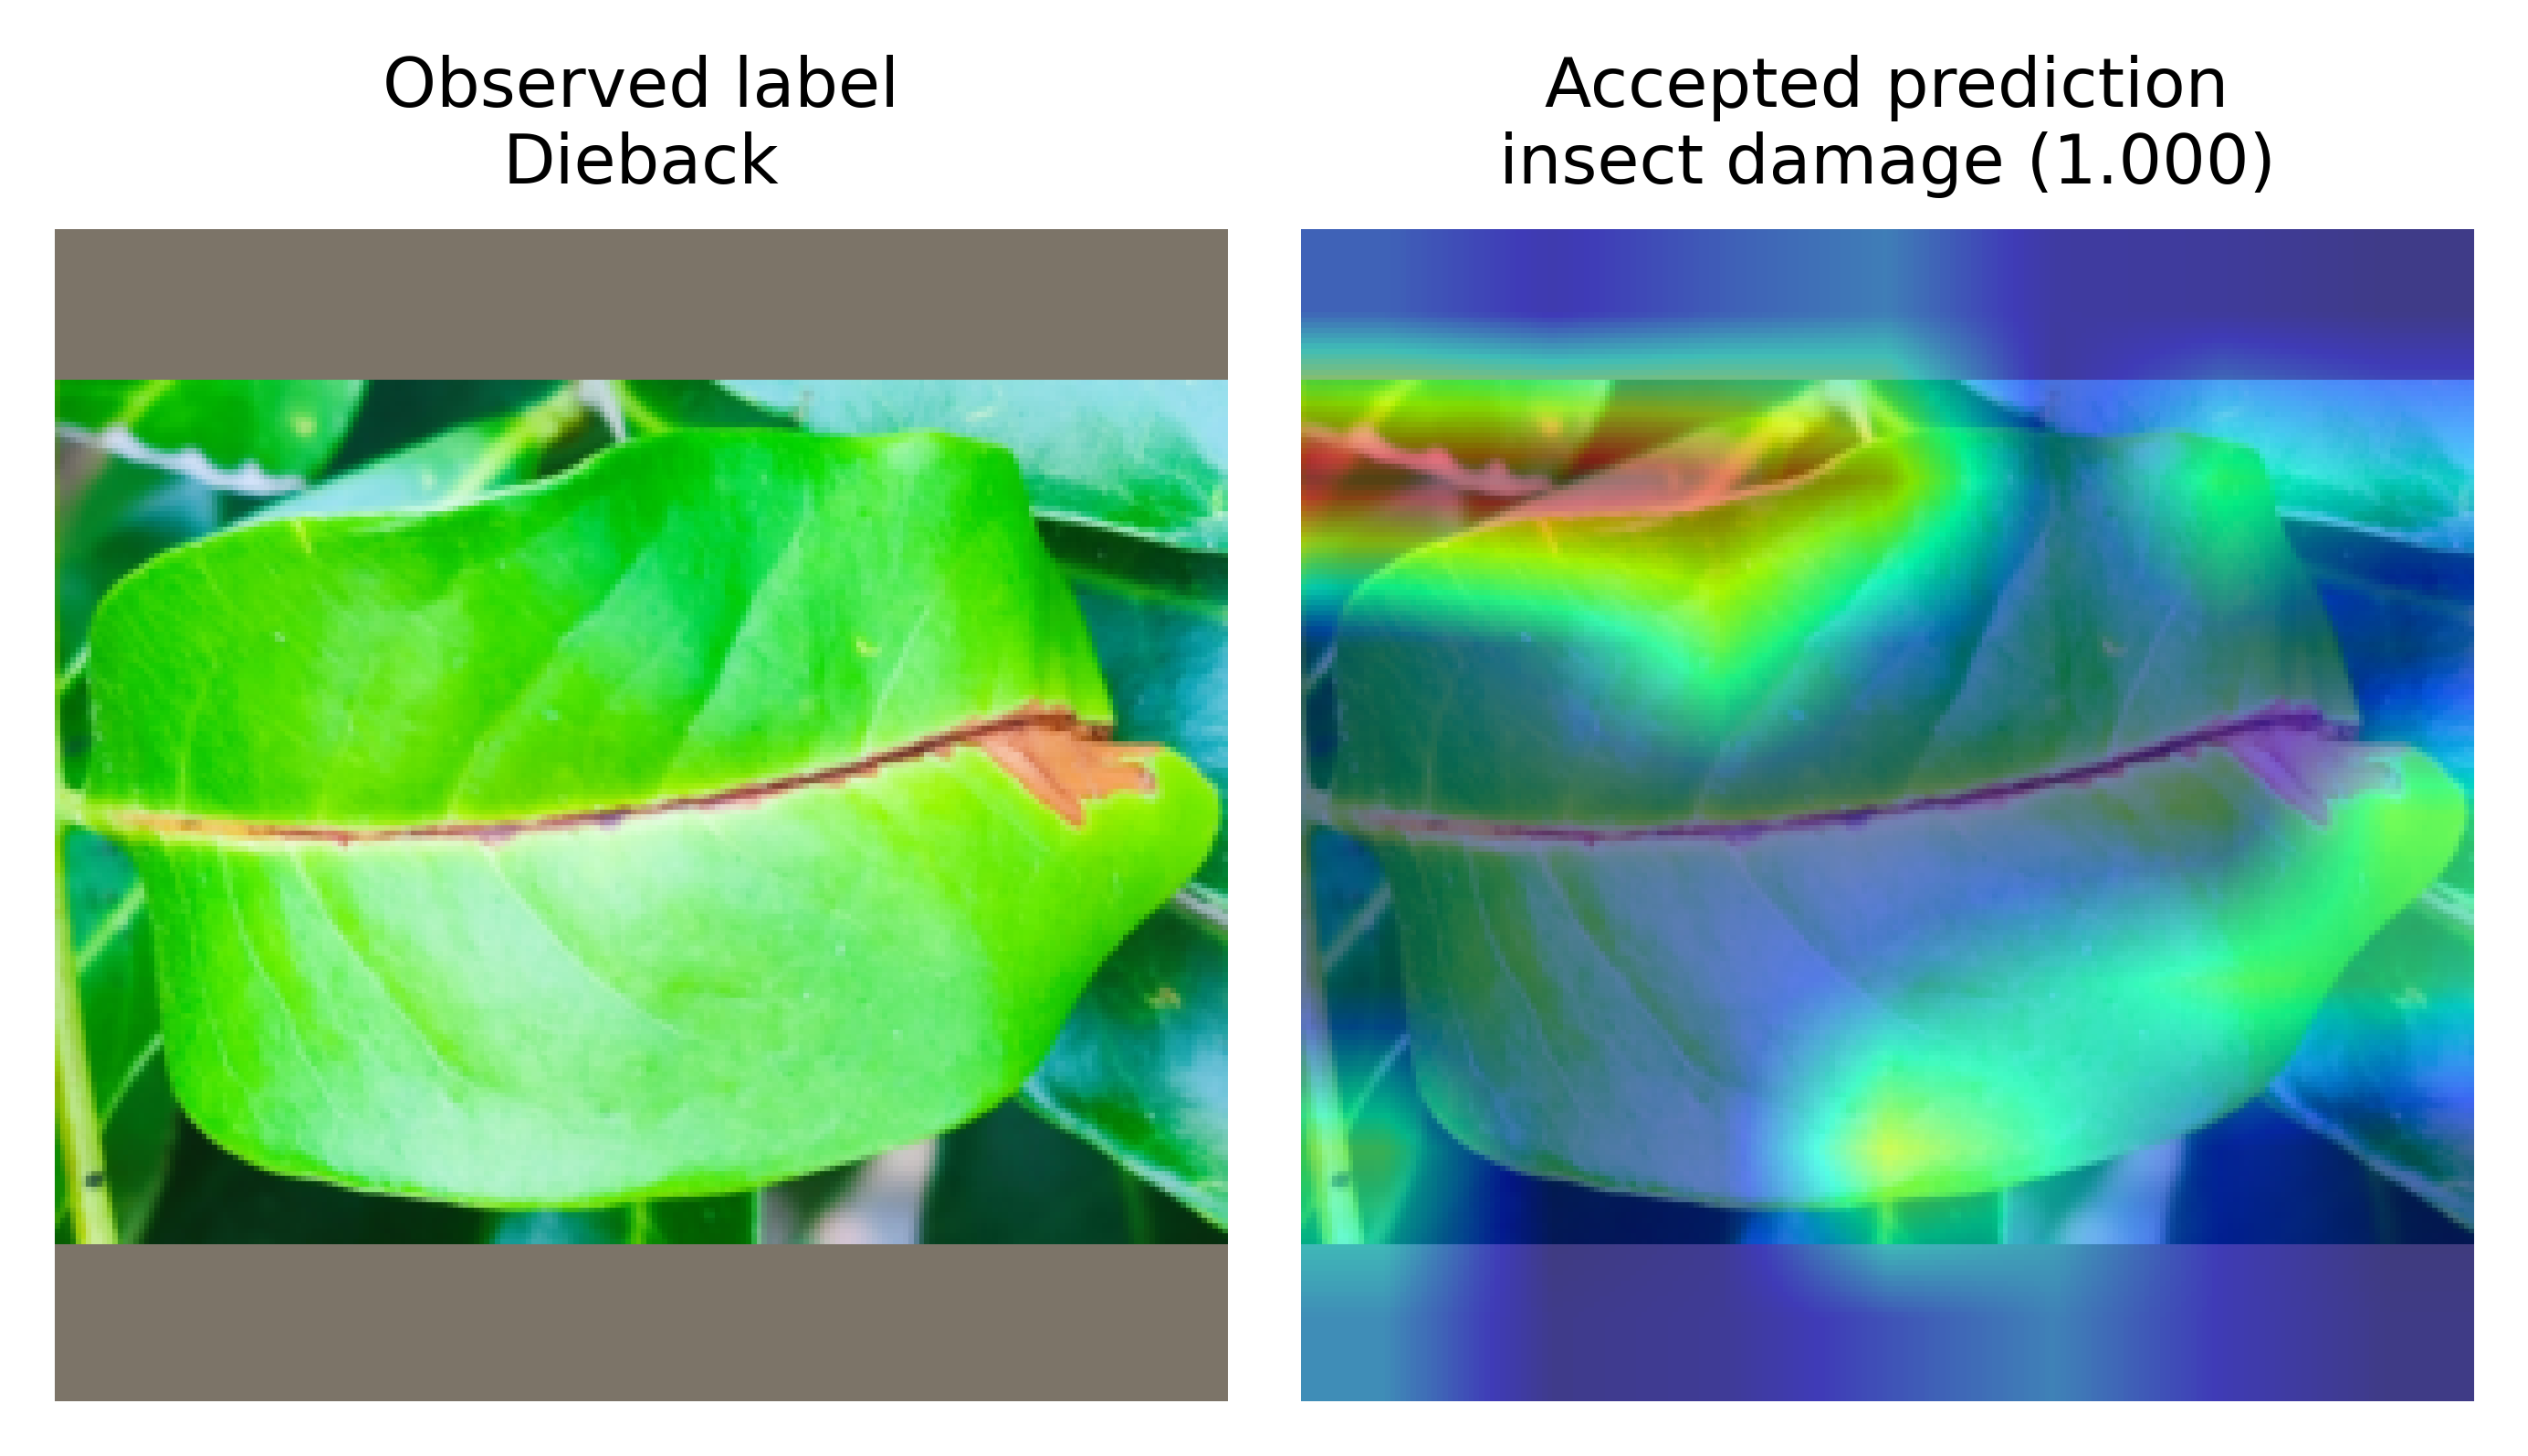

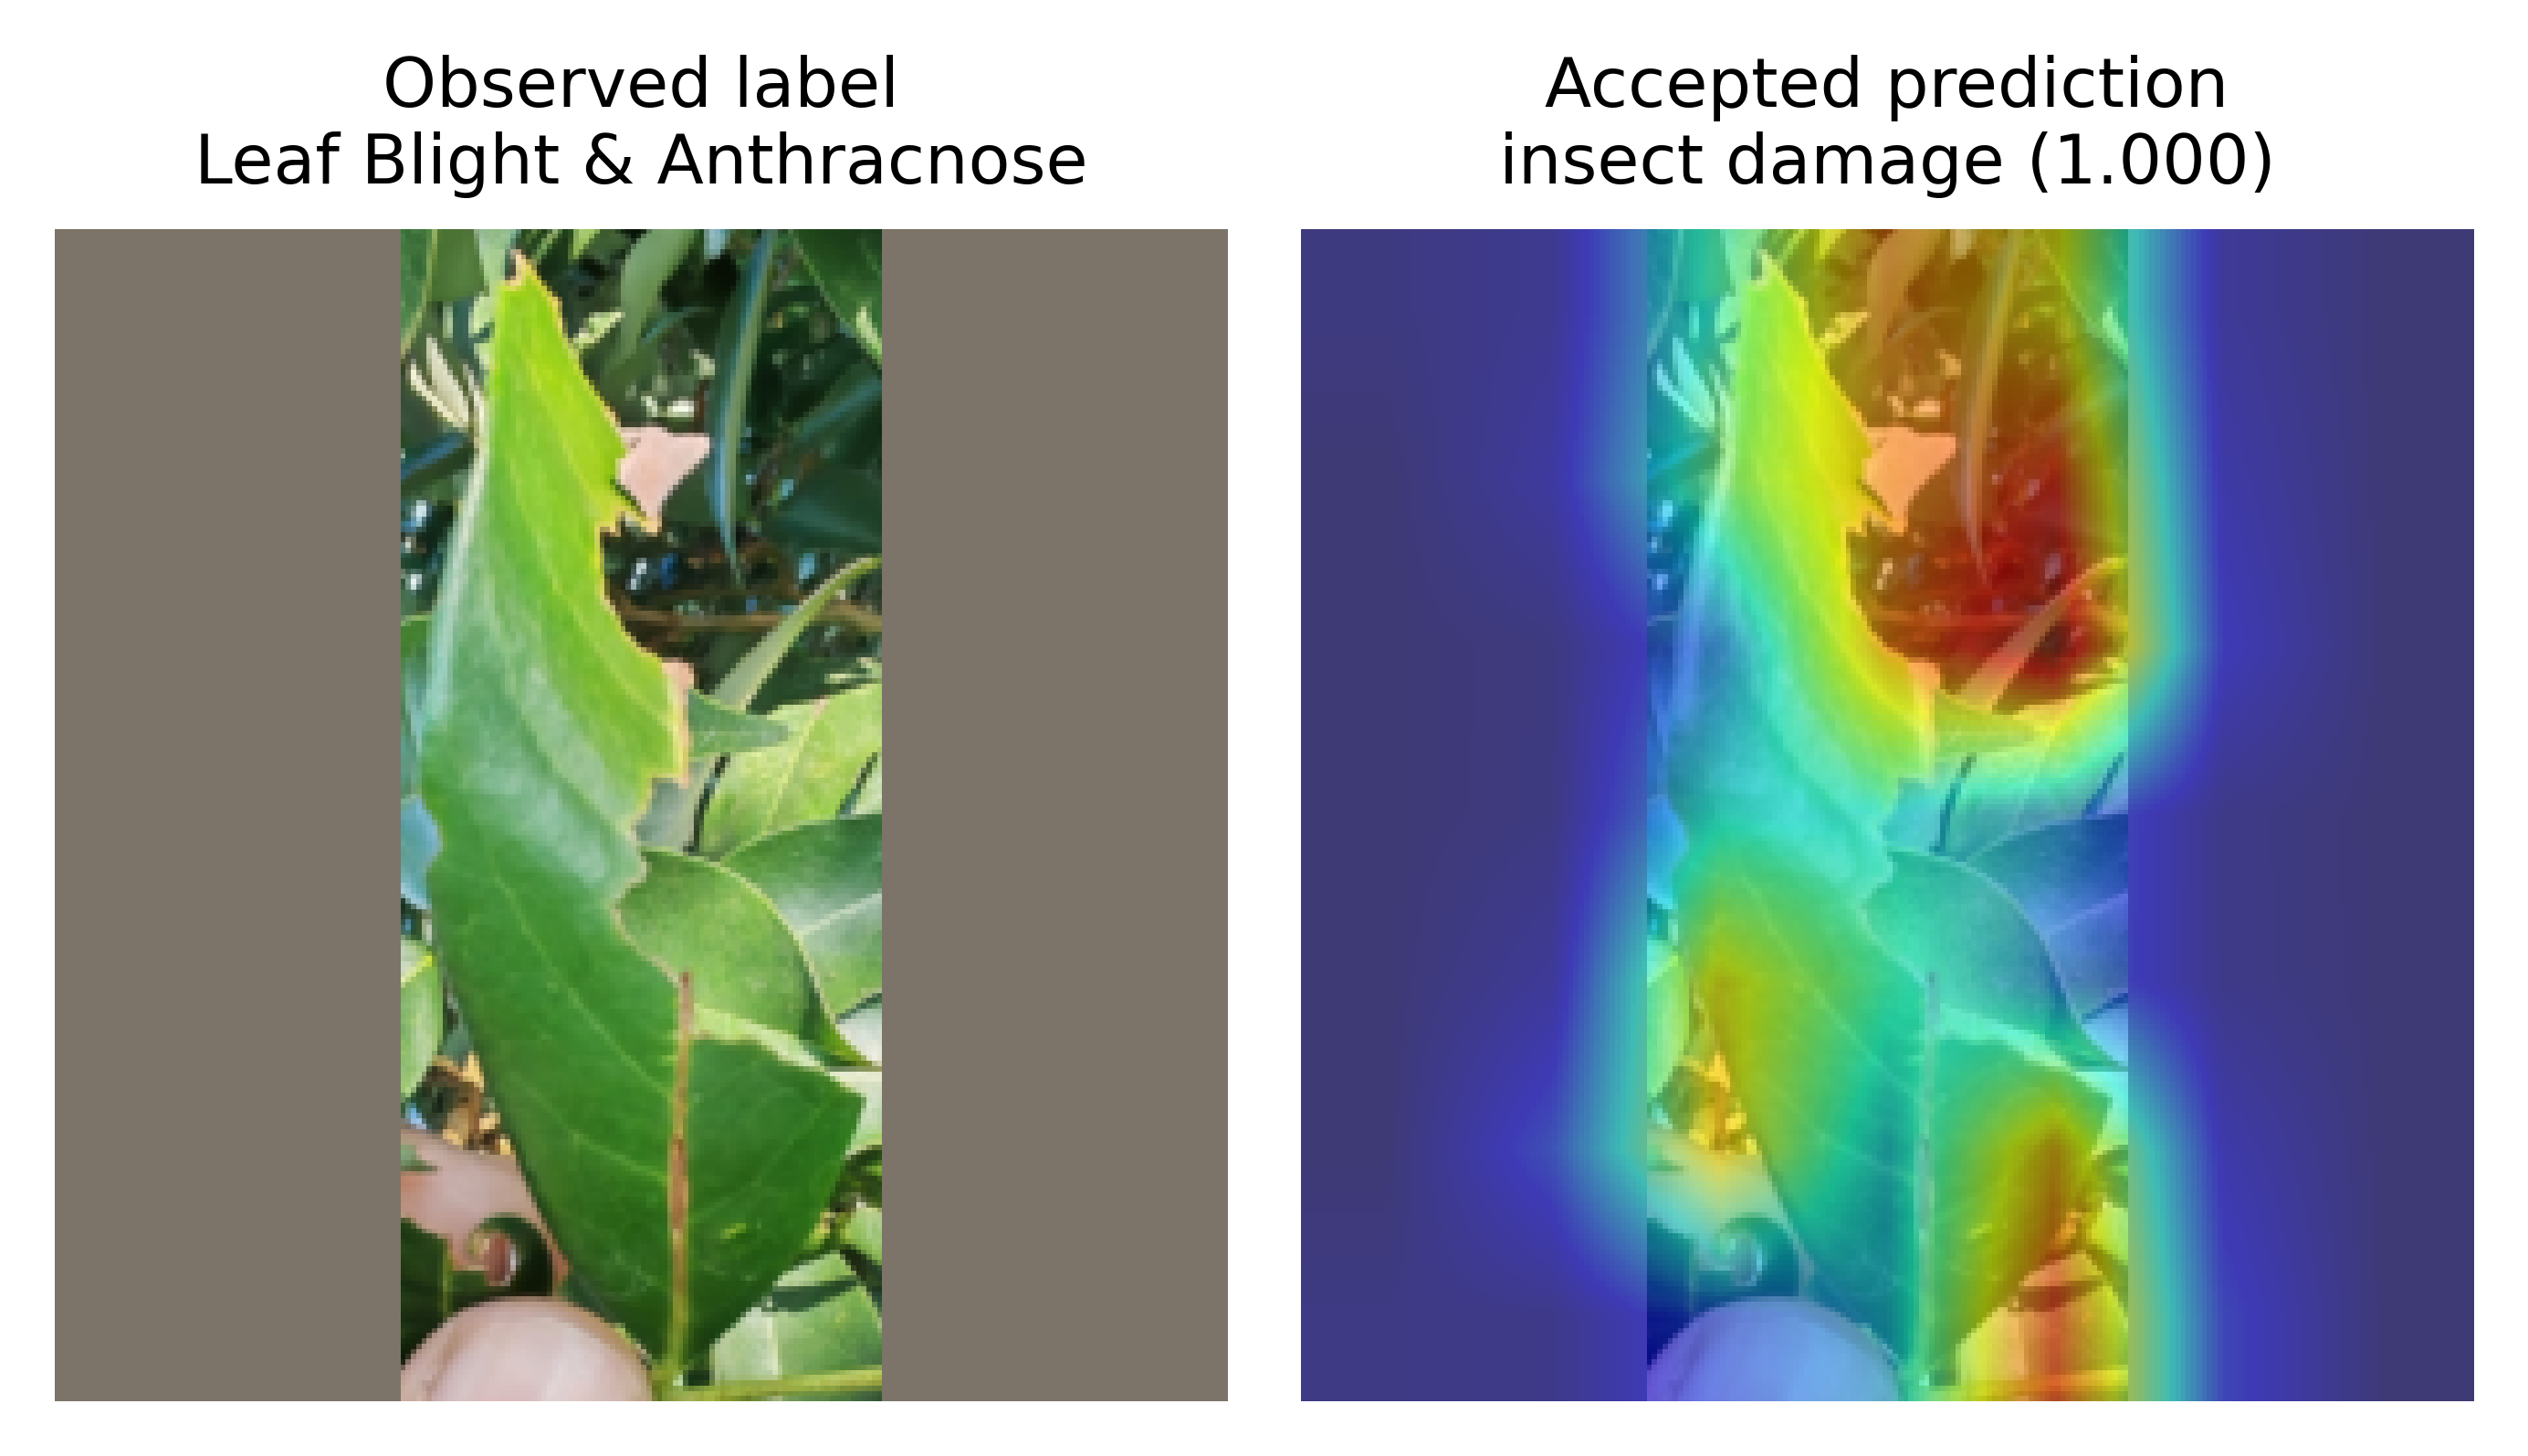

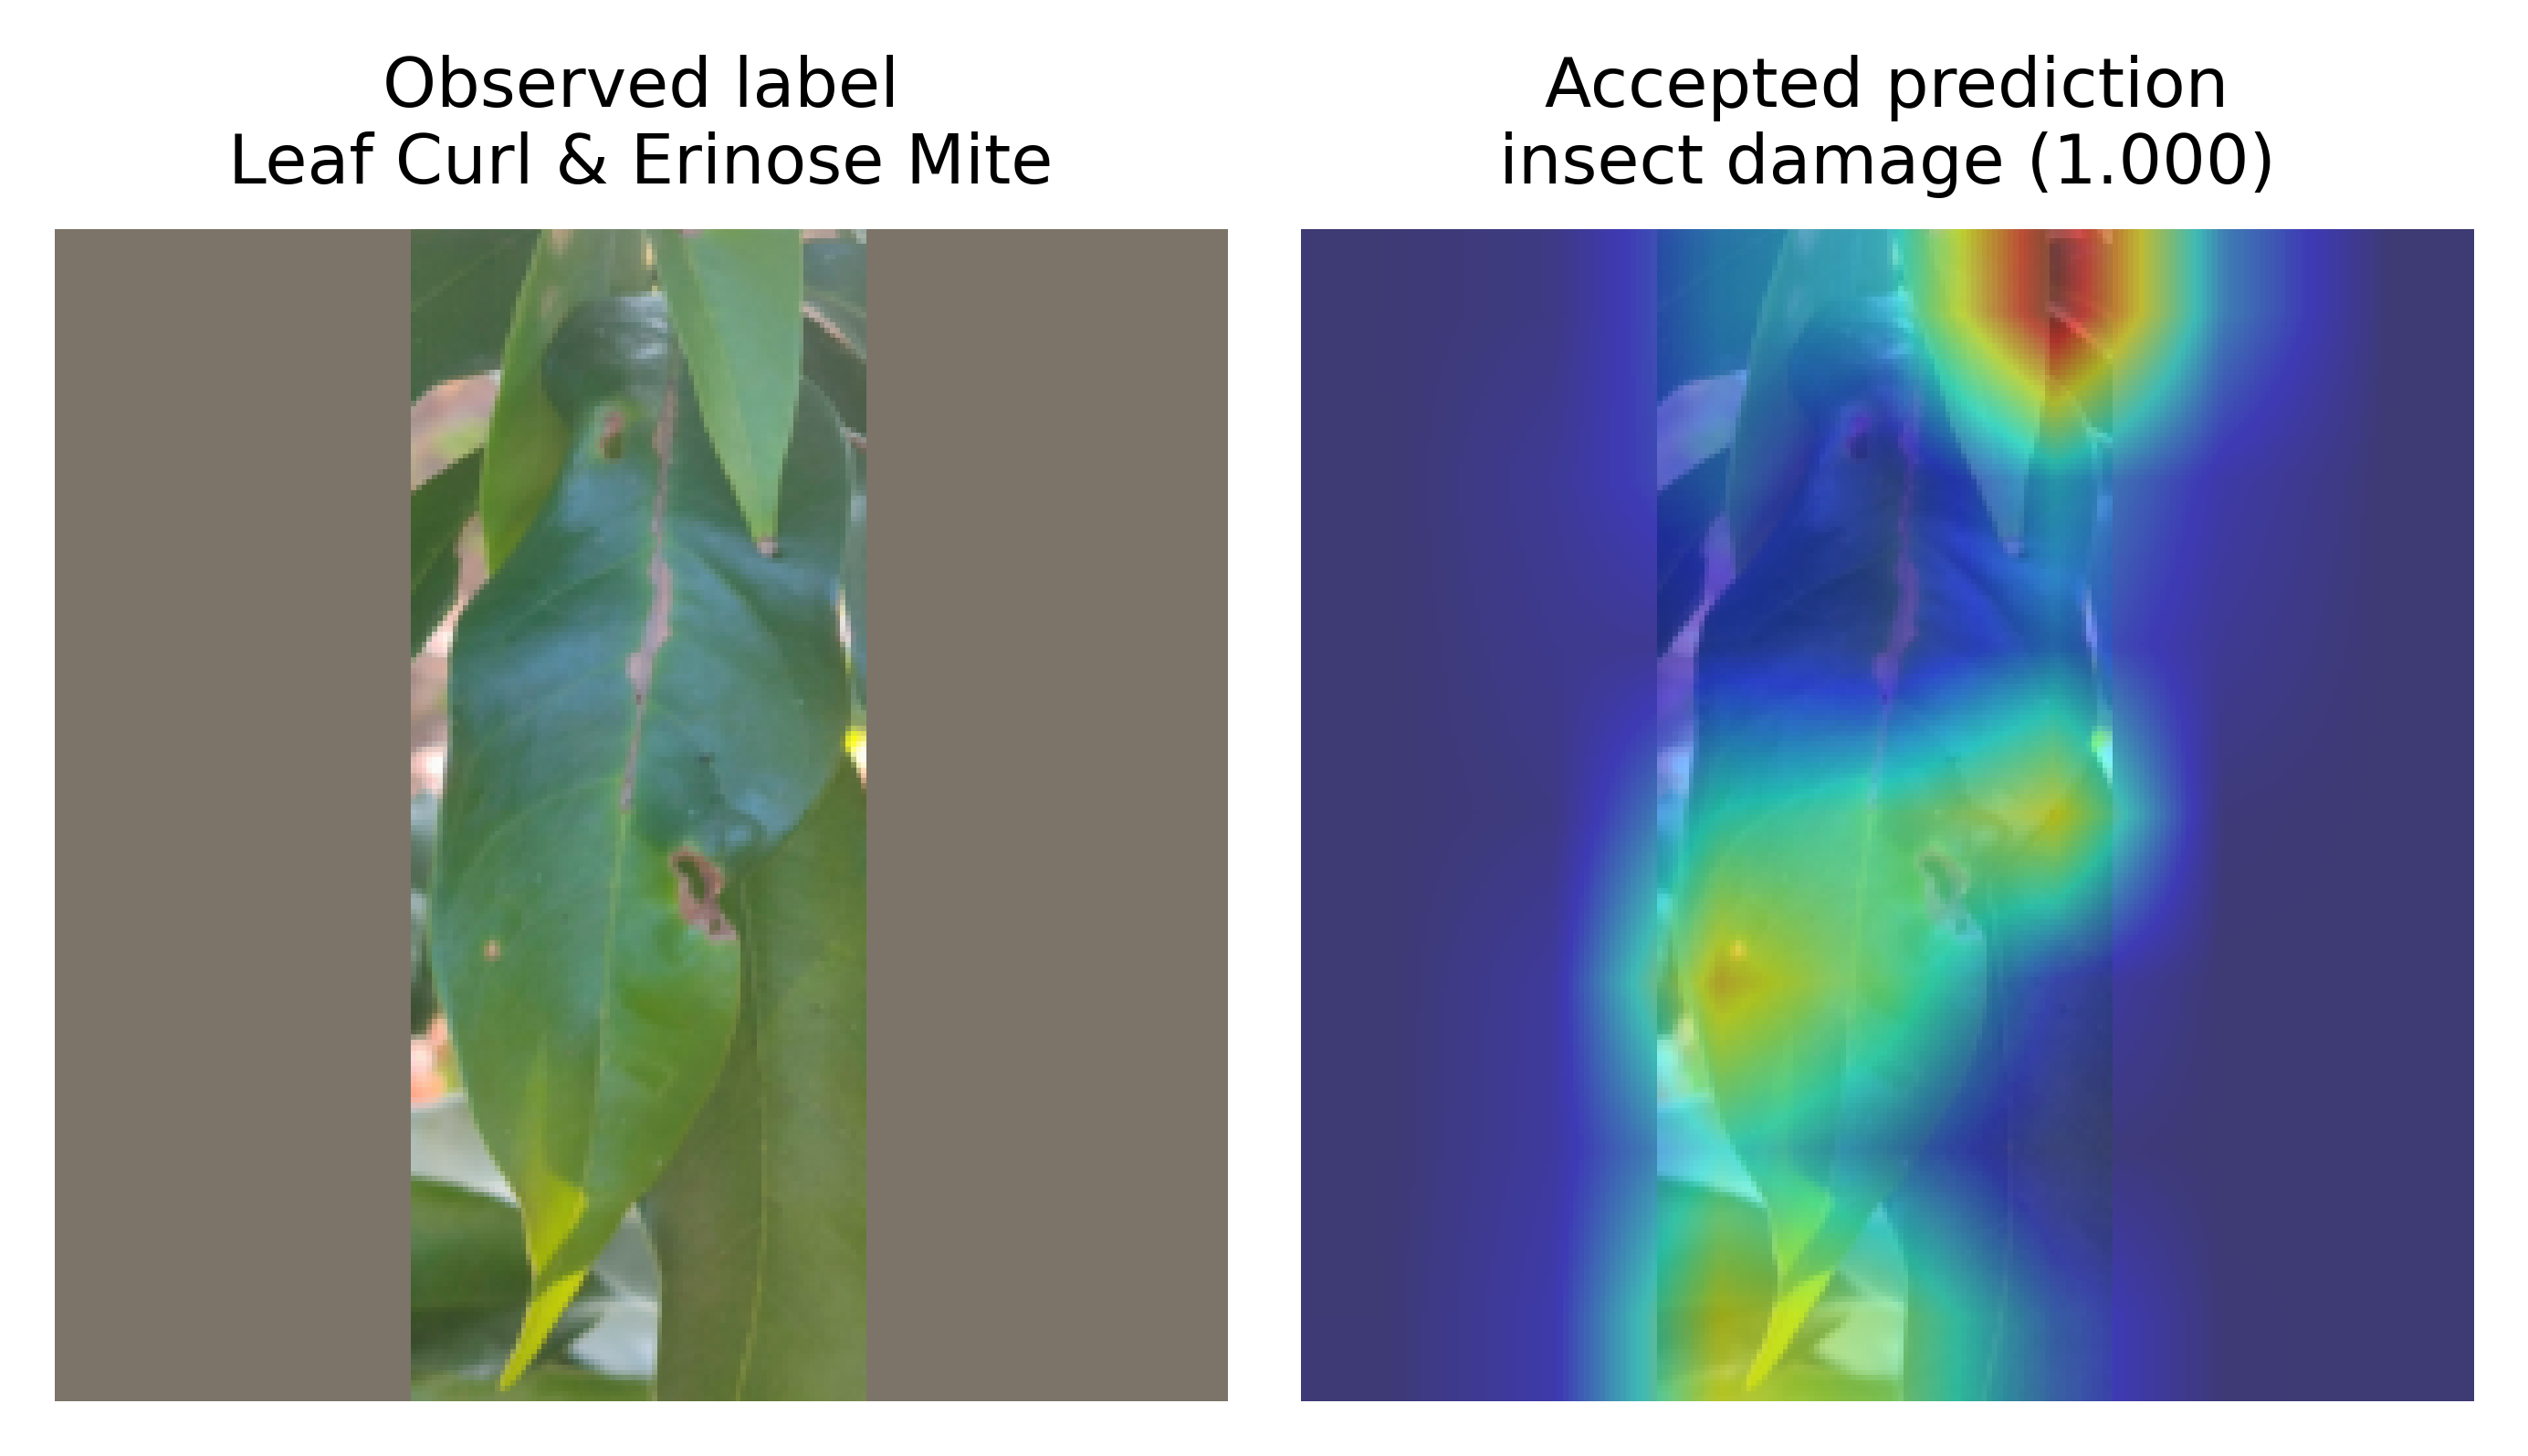

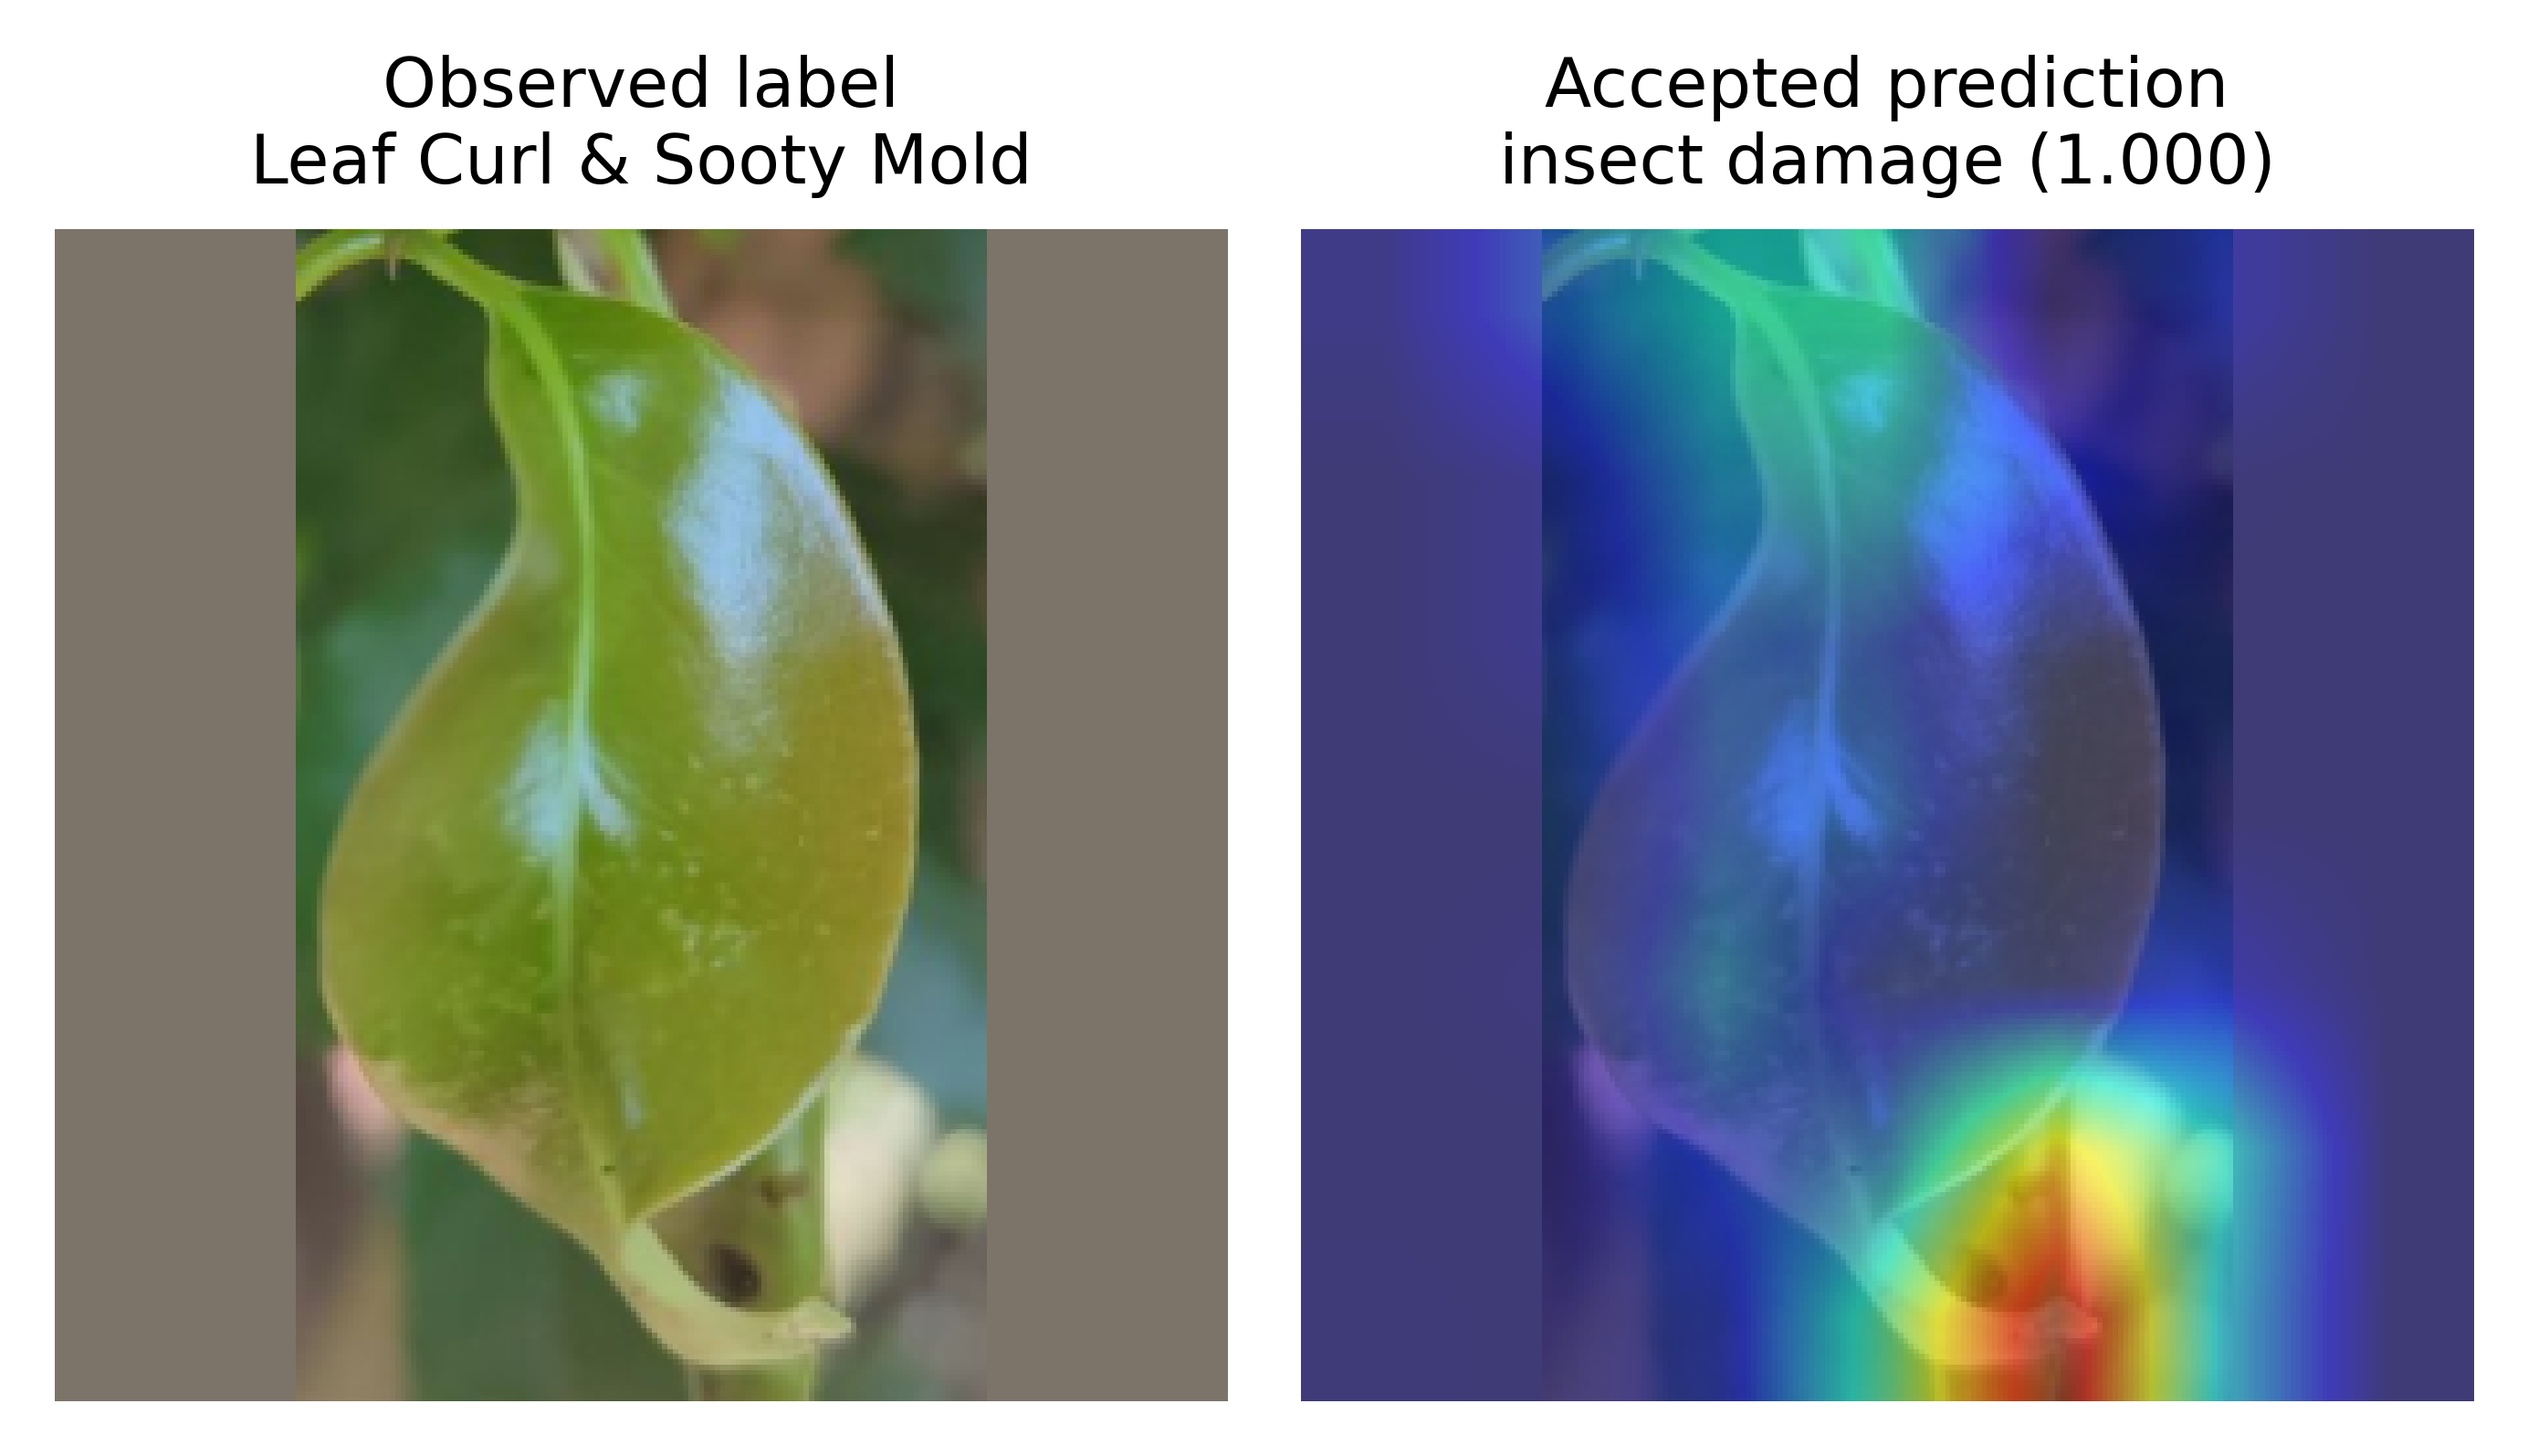

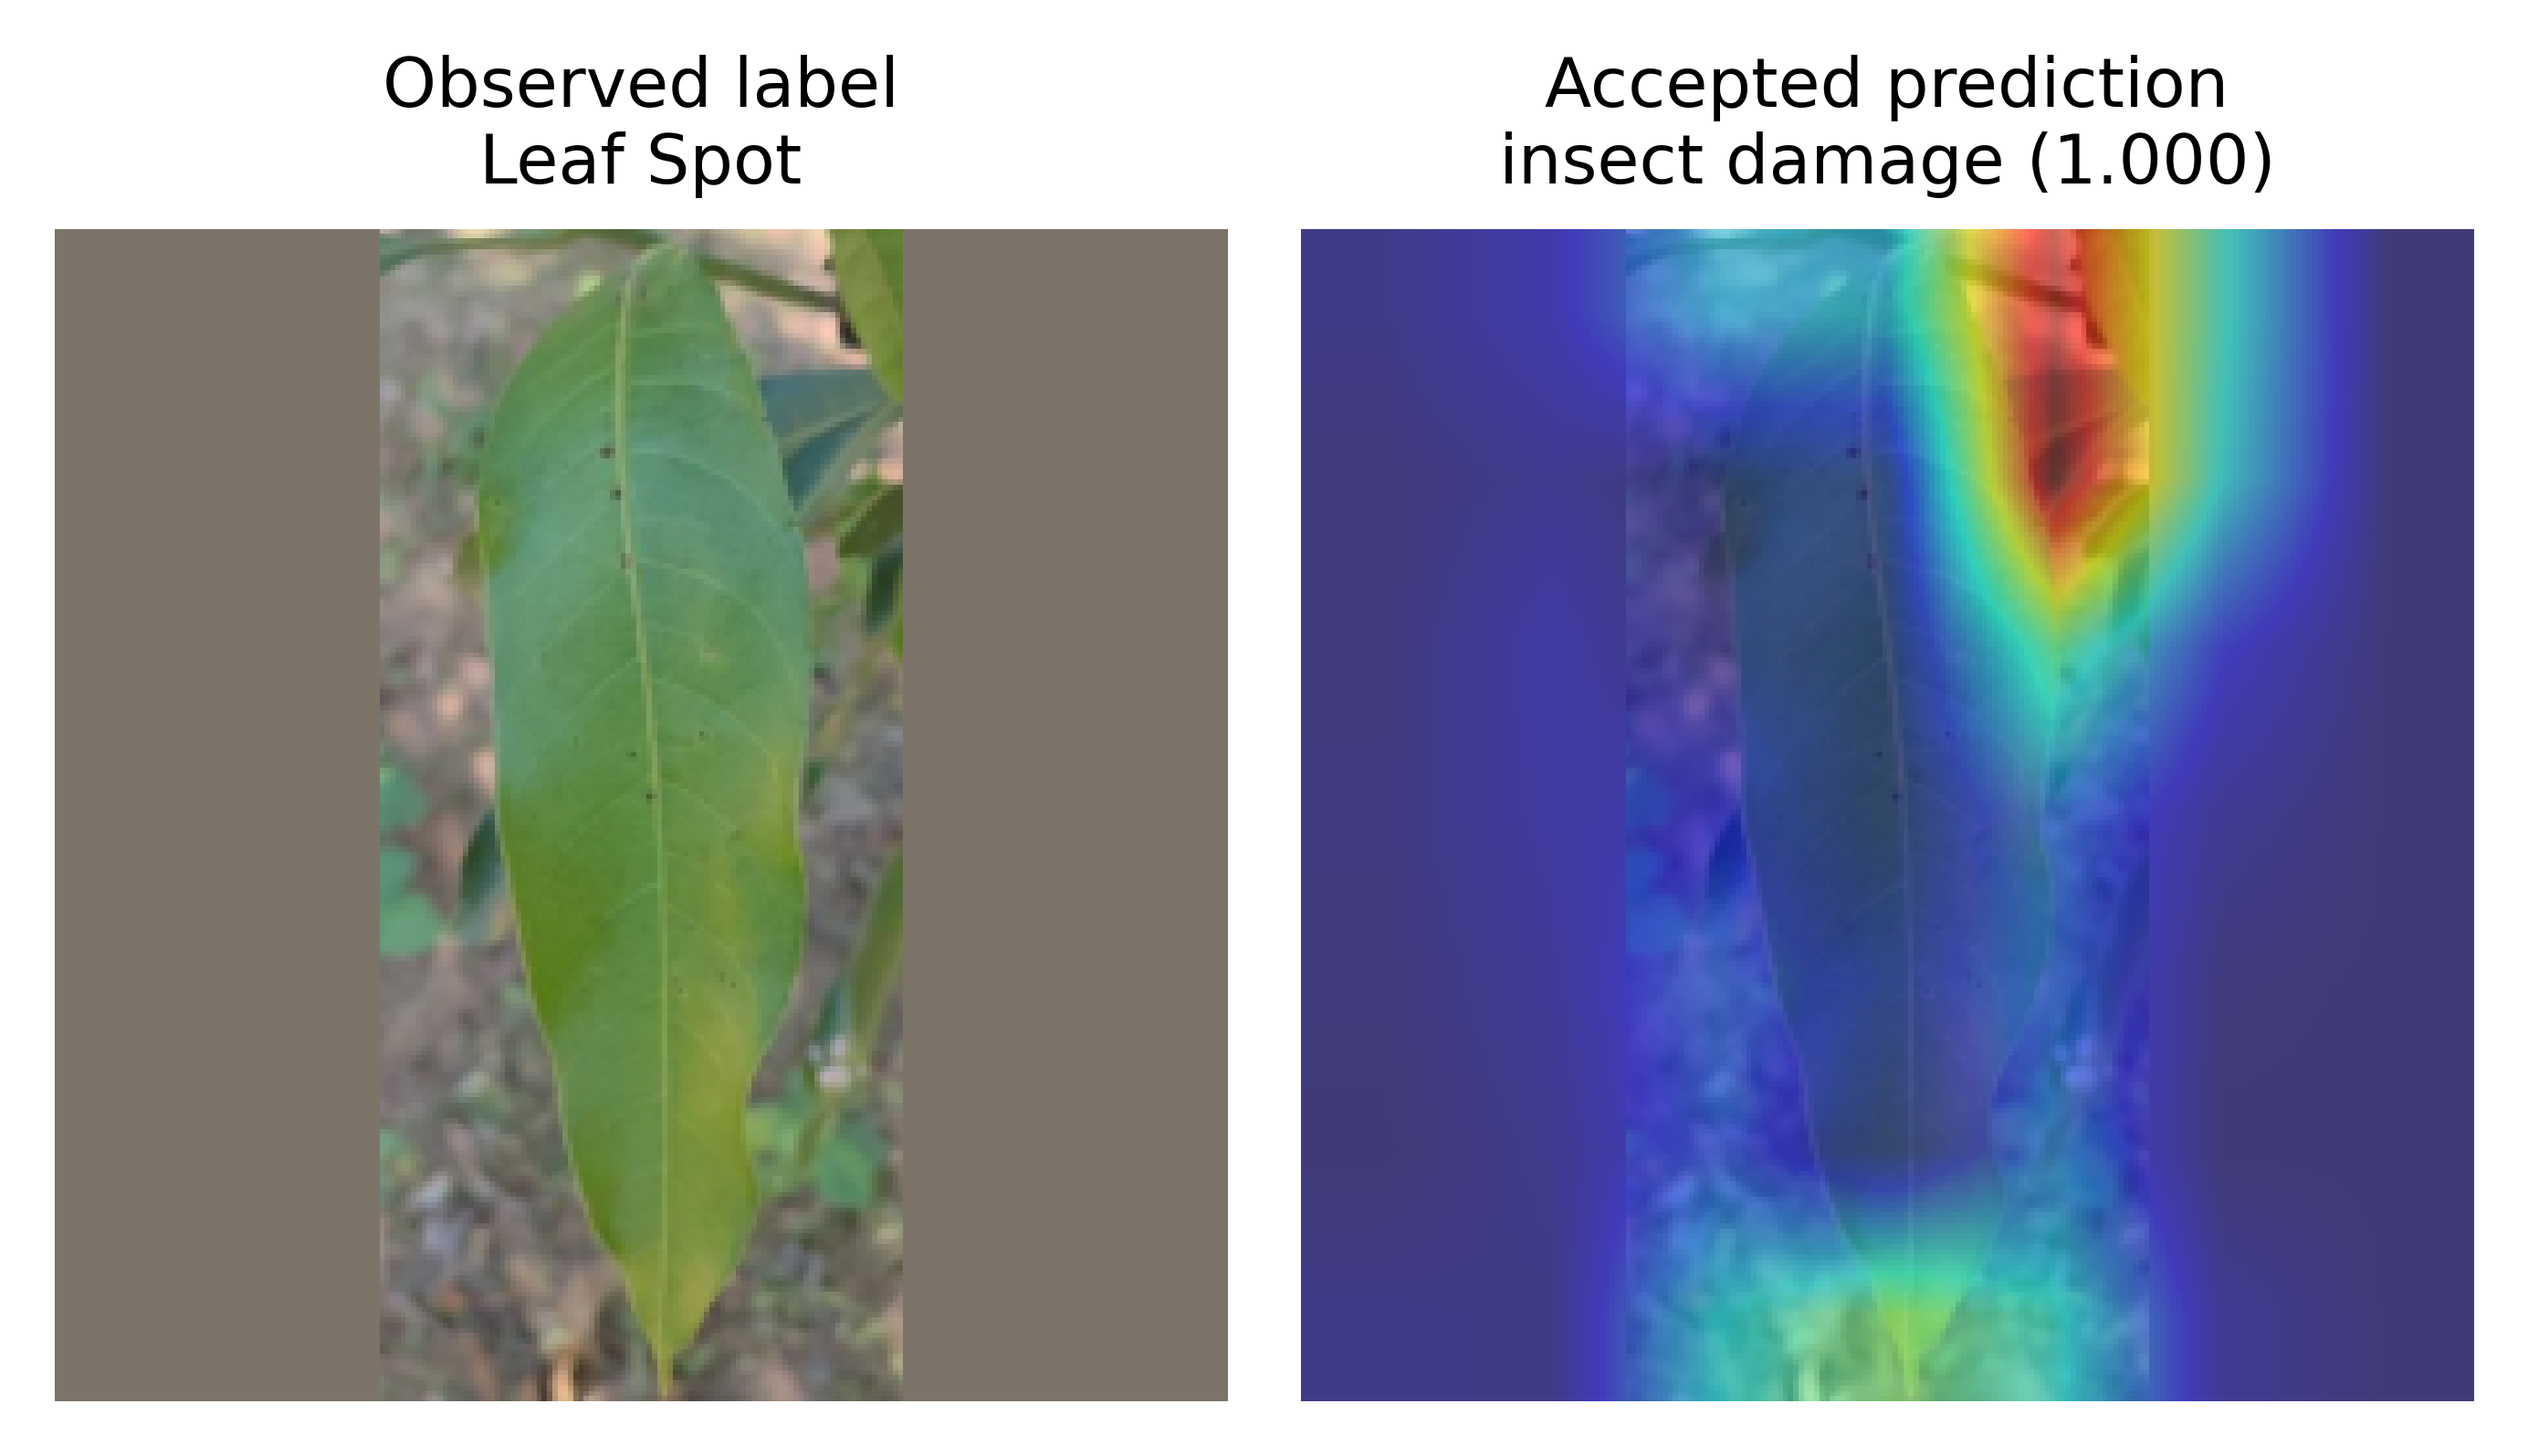

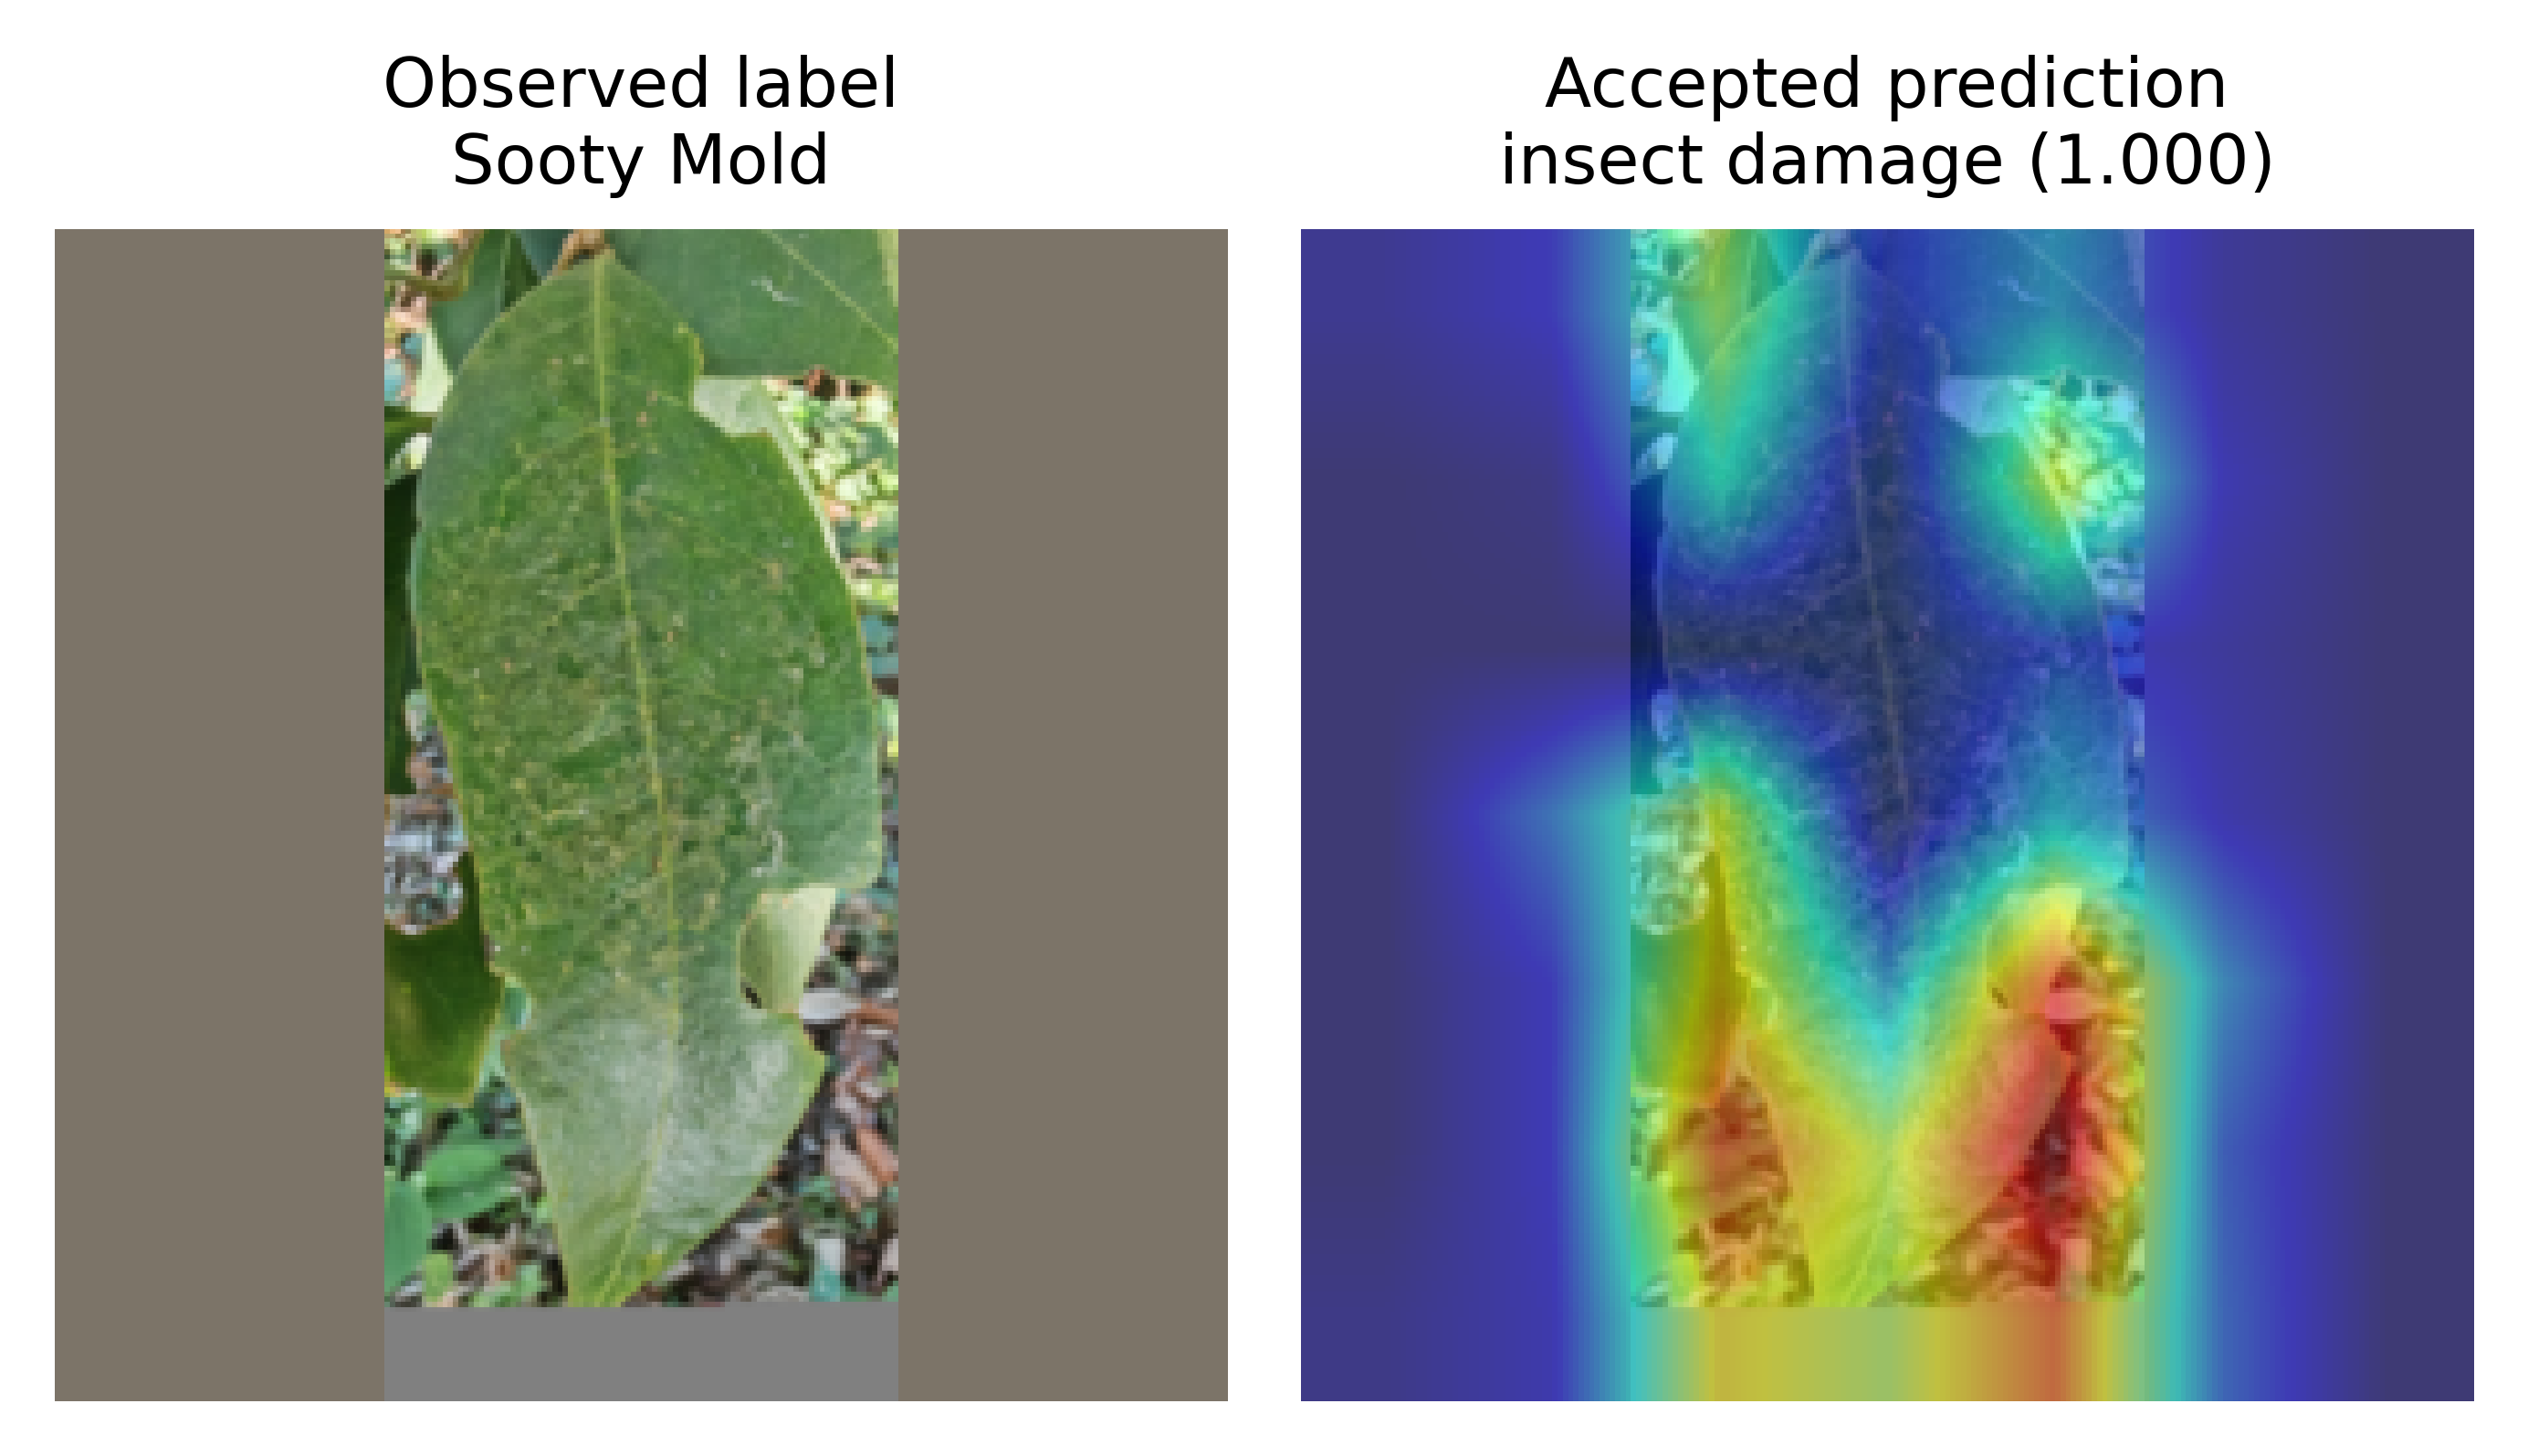

In [42]:
# Configure 600 DPI inline display in Google Colab
%config InlineBackend.figure_format = 'png'

import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 600
mpl.rcParams['savefig.dpi'] = 600

if "get_cam" not in globals():
    raise RuntimeError("Run Cell 21 before this explanation cell.")

# Ensure the explanation model matches BEST_NAME.
explanation_model = load_checkpoint(BEST_NAME)

for parameter in explanation_model.parameters():
    parameter.requires_grad = True

target_layers = [
    explanation_model.features[-1]
]

frame = external_score_frames[BEST_NAME]

candidates = frame[
    frame["evaluation_group"].isin(["additional", "mixed"])
    & frame["accept_calibrated_confidence"]
].copy()

selected_failure_rows = []

for folder_label, condition in candidates.groupby("folder_label"):

    selected_failure_rows.append(
        condition.sort_values(
            "calibrated_confidence",
            ascending=False
        ).iloc[0]
    )

if not selected_failure_rows:

    print(
        "No additional or mixed-category images were accepted "
        "by calibrated-confidence referral."
    )

else:

    selected_failures = pd.DataFrame(
        selected_failure_rows
    ).reset_index(drop=True)

    selected_failures.to_csv(
        EXT_OUT / "gradcam_accepted_unrepresented_examples.csv",
        index=False
    )

    for index, row in selected_failures.iterrows():

        rgb, _, heatmap, overlay = get_cam(
            row["path"],
            row["predicted_id"]
        )

        reference_label = (
            row["folder_label"]
            .replace("_", " ")
            .replace("&", " & ")
        )

        with mpl.rc_context({
            **PUBLICATION_STYLE,
            "figure.dpi": 600,
            "savefig.dpi": 600,
        }):

            fig, axes = plt.subplots(
                1, 2,
                figsize=(119 / 25.4, 2.8)
            )

            axes[0].imshow(rgb)
            axes[1].imshow(overlay)

            for axis in axes:
                axis.axis("off")

            axes[0].set_title(
                f"Observed label\n{reference_label}",
                fontsize=9
            )

            axes[1].set_title(
                f"Accepted prediction\n"
                f"{row['predicted_label'].replace('_', ' ')} "
                f"({row['calibrated_confidence']:.3f})",
                fontsize=9
            )

            fig.tight_layout()

            # Save as high-resolution PDF and PNG.
            for extension in ["pdf", "png"]:
                fig.savefig(
                    EXT_FIG / (
                        f"accepted_unrepresented_gradcam_{index:02d}"
                        f".{extension}"
                    ),
                    dpi=600,
                    bbox_inches="tight",
                    facecolor="white"
                )

            # Display at 600 DPI in Google Colab
            plt.show()
            plt.close(fig)

Cell 36 — Install Gradio

In [43]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "gradio>=5,<7"
])

import gradio as gr
import importlib.metadata

print("Gradio version:", importlib.metadata.version("gradio"))

Gradio version: 6.31.0


Cell 37 — Package both trained models and test examples
The exported .pt files contain the best trained weights. The application reconstructs each architecture and loads these weights directly.

In [45]:
import hashlib
import json
import shutil
import re

from pathlib import Path
from PIL import Image, ImageOps

BUNDLE = ROOT / "litchi_gradio_app"
MODEL_DIR = BUNDLE / "models"
EXAMPLE_DIR = BUNDLE / "examples"

for directory in [BUNDLE, MODEL_DIR, EXAMPLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

required = [
    "threshold_table",
    "temperatures",
    "extended_external",
    "BEST_NAME",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Run the earlier evaluation cells first. Missing: {missing}"
    )


def sha256_file(path):
    digest = hashlib.sha256()

    with Path(path).open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


model_metadata = {}

for model_name in CONFIG["models"]:

    original_checkpoint = (
        OUT / "checkpoints" / f"{model_name}.pt"
    )

    # Load the checkpoint created by this notebook.
    saved = torch.load(
        original_checkpoint,
        map_location="cpu",
        weights_only=False
    )

    if saved["classes"] != CLASSES:
        raise ValueError(
            f"Class order differs for {model_name}"
        )

    if saved["manifest_sha256"] != MANIFEST_SHA256:
        raise ValueError(
            f"Data manifest differs for {model_name}"
        )

    exported_weights = MODEL_DIR / f"{model_name}.pt"

    state_dict = {
        key: value.detach().cpu()
        for key, value in saved["state_dict"].items()
    }

    torch.save(state_dict, exported_weights)

    model_thresholds = {}

    for method in SCORE_METHODS:

        matches = threshold_table[
            threshold_table["model"].eq(model_name)
            & threshold_table["method"].eq(method)
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Missing or duplicated threshold: "
                f"{model_name}, {method}"
            )

        model_thresholds[method] = float(
            matches.iloc[0]["threshold"]
        )

    model_metadata[model_name] = {
        "weights": f"models/{model_name}.pt",
        "weights_sha256": sha256_file(exported_weights),
        "temperature": float(temperatures[model_name]),
        "thresholds": model_thresholds,
        "best_validation_macro_f1": float(
            saved["validation_macro_f1"]
        ),
        "best_epoch": int(saved["epoch"]),
    }

# Recreate the small example directory on reruns.
for existing in EXAMPLE_DIR.glob("*.png"):
    existing.unlink()

example_records = []

example_sources = [
    (
        "BDLitchi_internal_test",
        SPLITS["internal_test"],
        "label"
    ),
    (
        "Rangamati_external_test",
        extended_external,
        "folder_label"
    ),
]

for source_name, frame, category_column in example_sources:

    for category, candidates in frame.groupby(
        category_column,
        sort=True
    ):

        sample = candidates.sort_values("path").sample(
            n=1,
            random_state=SEED
        ).iloc[0]

        safe_category = re.sub(
            r"[^A-Za-z0-9]+",
            "_",
            str(category)
        ).strip("_")

        filename = f"{source_name}_{safe_category}.png"
        destination = EXAMPLE_DIR / filename

        with Image.open(sample["path"]) as image:
            ImageOps.exif_transpose(image).convert(
                "RGB"
            ).save(destination)

        example_records.append({
            "file": f"examples/{filename}",
            "source": source_name,
            "reference_label": str(category),
            "original_relative_path": str(
                sample["relative_path"]
            ),
        })

metadata = {
    "author": "Partha Pratim Ray",
    "classes": list(CLASSES),
    "image_size": int(CONFIG["image_size"]),
    "mean": list(MEAN),
    "std": list(STD),
    "selected_model": BEST_NAME,
    "manifest_sha256": MANIFEST_SHA256,
    "training_config": CONFIG,
    "models": model_metadata,
    "examples": example_records,
    "source_acceptance_target": float(
        SOURCE_ACCEPTANCE_TARGET
    ),
    "datasets": {
        "BDLitchi": "10.17632/jhb24mszdk.1",
        "RangamatiV3": "10.17632/94srbmydkw.3",
    },
}

(BUNDLE / "metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

packages = [
    "torch",
    "torchvision",
    "gradio",
    "grad-cam",
    "numpy",
    "pandas",
    "scipy",
    "Pillow",
]

requirements = []
environment_versions = {}

for package in packages:
    version = importlib.metadata.version(package)
    environment_versions[package] = version

    # CUDA suffixes belong to the recorded environment.
    # Standard version numbers are used for pip installation.
    pip_version = version.split("+")[0]
    requirements.append(f"{package}=={pip_version}")

(BUNDLE / "requirements.txt").write_text(
    "\n".join(requirements) + "\n"
)

(BUNDLE / "training_environment.json").write_text(
    json.dumps(
        {
            "python": sys.version,
            "packages": environment_versions,
        },
        indent=2
    )
)

pd.DataFrame(example_records).to_csv(
    BUNDLE / "example_reference_labels.csv",
    index=False
)

print("Application directory:", BUNDLE)
print("Models packaged:", list(model_metadata))
print("Test examples included:", len(example_records))

Application directory: /content/litchi_study/litchi_gradio_app
Models packaged: ['mobilenet_v3_small', 'efficientnet_v2_s']
Test examples included: 15


Cell 38 — Write the standalone Gradio application
The footer contains your name and instructions. Users can choose a referral rule while its fitted thresholds remain fixed.

In [46]:
APP_CODE = r'''
import argparse
import hashlib
import json
import tempfile
import threading
import zipfile

from pathlib import Path

import gradio as gr
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image, ImageOps
from scipy.special import softmax, logsumexp
from torchvision import models
from torchvision.transforms import functional as TF

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


BASE = Path(__file__).resolve().parent
META = json.loads((BASE / "metadata.json").read_text())

CLASSES = META["classes"]
IMAGE_SIZE = META["image_size"]
MEAN = META["mean"]
STD = META["std"]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

REPORT_ROOT = Path(
    tempfile.mkdtemp(prefix="litchi_reports_")
)

MODEL_LOCK = threading.RLock()

MODEL_NAMES = {
    "mobilenet_v3_small": "MobileNetV3-Small",
    "efficientnet_v2_s": "EfficientNetV2-S",
}

CLASS_NAMES = {
    "healthy": "Healthy",
    "insect_damage": "Insect damage",
    "leaf_blight": "Leaf blight",
    "red_rust": "Red rust",
}

RULE_NAMES = {
    "Calibrated confidence": "calibrated_confidence",
    "Raw confidence": "raw_confidence",
    "Energy": "energy",
}


def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def construct_model(name):

    if name == "mobilenet_v3_small":
        model = models.mobilenet_v3_small(weights=None)

    elif name == "efficientnet_v2_s":
        model = models.efficientnet_v2_s(weights=None)

    else:
        raise ValueError(f"Unsupported architecture: {name}")

    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features,
        len(CLASSES)
    )

    record = META["models"][name]
    weights_path = BASE / record["weights"]

    if sha256_file(weights_path) != record["weights_sha256"]:
        raise RuntimeError(
            f"Weight-file checksum mismatch for {name}"
        )

    weights = torch.load(
        weights_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(weights)
    model.to(DEVICE)
    model.eval()

    return model


MODELS = {
    name: construct_model(name)
    for name in META["models"]
}


def prepare_image(image):

    rgb_image = ImageOps.exif_transpose(
        image
    ).convert("RGB")

    resized = ImageOps.contain(
        rgb_image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.BILINEAR
    )

    padding_color = tuple(
        round(value * 255)
        for value in MEAN
    )

    canvas = Image.new(
        "RGB",
        (IMAGE_SIZE, IMAGE_SIZE),
        padding_color
    )

    canvas.paste(
        resized,
        (
            (IMAGE_SIZE - resized.width) // 2,
            (IMAGE_SIZE - resized.height) // 2
        )
    )

    tensor = TF.normalize(
        TF.to_tensor(canvas),
        MEAN,
        STD
    ).unsqueeze(0).to(DEVICE)

    rgb_array = (
        np.asarray(canvas, dtype=np.float32) / 255.0
    )

    return canvas, rgb_array, tensor


def analyze(image, referral_rule):

    if image is None:
        raise gr.Error(
            "Upload a litchi leaf image or select a test example."
        )

    if referral_rule not in RULE_NAMES:
        raise gr.Error("Select a valid referral rule.")

    primary_method = RULE_NAMES[referral_rule]

    with MODEL_LOCK:

        canvas, rgb_array, tensor = prepare_image(image)

        report_directory = Path(
            tempfile.mkdtemp(
                prefix="analysis_",
                dir=REPORT_ROOT
            )
        )

        canvas.save(
            report_directory / "model_input.png"
        )

        prediction_rows = []
        probability_values = {
            "Category": [
                CLASS_NAMES.get(label, label)
                for label in CLASSES
            ]
        }
        score_rows = []
        gallery_images = []
        report_models = {}

        for model_name, model in MODELS.items():

            model_label = MODEL_NAMES.get(
                model_name,
                model_name
            )

            model_metadata = META["models"][model_name]
            temperature = float(
                model_metadata["temperature"]
            )

            model.zero_grad(set_to_none=True)

            with torch.no_grad():
                logits = (
                    model(tensor)
                    .float()
                    .cpu()
                    .numpy()[0]
                )

            raw_probabilities = softmax(logits)
            calibrated_probabilities = softmax(
                logits / temperature
            )

            predicted_id = int(np.argmax(logits))
            predicted_label = CLASSES[predicted_id]

            raw_confidence = float(
                raw_probabilities.max()
            )
            calibrated_confidence = float(
                calibrated_probabilities.max()
            )

            rejection_scores = {
                "raw_confidence": 1 - raw_confidence,
                "calibrated_confidence": (
                    1 - calibrated_confidence
                ),
                "energy": float(-logsumexp(logits)),
            }

            decisions = {}

            for method, score in rejection_scores.items():

                threshold = float(
                    model_metadata["thresholds"][method]
                )

                accepted = score <= threshold

                decision = (
                    "Label retained"
                    if accepted
                    else "Refer for review"
                )

                decisions[method] = decision

                score_rows.append({
                    "Model": model_label,
                    "Referral method": method,
                    "Rejection score": score,
                    "Source-fitted threshold": threshold,
                    "Decision": decision,
                })

            prediction_rows.append({
                "Model": model_label,
                "Candidate label": CLASS_NAMES.get(
                    predicted_label,
                    predicted_label
                ),
                "Raw confidence (%)": (
                    100 * raw_confidence
                ),
                "Calibrated confidence (%)": (
                    100 * calibrated_confidence
                ),
                "Selected-rule decision": (
                    decisions[primary_method]
                ),
            })

            probability_values[
                model_label + " (%)"
            ] = 100 * calibrated_probabilities

            # Explain the candidate class logit.
            with torch.enable_grad(), GradCAM(
                model=model,
                target_layers=[model.features[-1]]
            ) as cam:

                heatmap = cam(
                    input_tensor=tensor,
                    targets=[
                        ClassifierOutputTarget(predicted_id)
                    ]
                )[0]

            overlay = show_cam_on_image(
                rgb_array,
                heatmap,
                use_rgb=True
            )

            Image.fromarray(overlay).save(
                report_directory
                / f"{model_name}_gradcam.png"
            )

            np.save(
                report_directory
                / f"{model_name}_gradcam.npy",
                heatmap
            )

            gallery_images.append((
                overlay,
                (
                    f"{model_label} | "
                    f"{CLASS_NAMES.get(predicted_label, predicted_label)}"
                    f" | {decisions[primary_method]}"
                )
            ))

            report_models[model_name] = {
                "candidate_label": predicted_label,
                "raw_confidence": raw_confidence,
                "calibrated_confidence": (
                    calibrated_confidence
                ),
                "temperature": temperature,
                "calibrated_probabilities": {
                    label: float(
                        calibrated_probabilities[index]
                    )
                    for index, label in enumerate(CLASSES)
                },
                "rejection_scores": rejection_scores,
                "thresholds": model_metadata["thresholds"],
                "decisions": decisions,
                "gradcam_map_range": float(
                    np.ptp(heatmap)
                ),
            }

            model.zero_grad(set_to_none=True)

        predictions = pd.DataFrame(prediction_rows)
        probabilities = pd.DataFrame(probability_values)
        scores = pd.DataFrame(score_rows)

        predictions.to_csv(
            report_directory / "model_predictions.csv",
            index=False
        )

        probabilities.to_csv(
            report_directory / "class_probabilities.csv",
            index=False
        )

        scores.to_csv(
            report_directory / "referral_scores.csv",
            index=False
        )

        report = {
            "author": META["author"],
            "selected_referral_rule": primary_method,
            "candidate_classes": CLASSES,
            "image_size": IMAGE_SIZE,
            "device": str(DEVICE),
            "models": report_models,
            "interpretation": (
                "Candidate labels describe four trained visual "
                "categories. Label retained means the chosen "
                "score passed its source-validation threshold. "
                "Species is assumed from user input. Additional "
                "conditions may receive one of the four labels."
            ),
            "gradcam_interpretation": (
                "Heatmaps indicate image regions influencing "
                "the candidate class logit. They do not measure "
                "disease severity or confirm a pathogen."
            ),
        }

        (report_directory / "report.json").write_text(
            json.dumps(report, indent=2)
        )

        report_zip = report_directory / "litchi_analysis_report.zip"

        with zipfile.ZipFile(
            report_zip,
            "w",
            zipfile.ZIP_DEFLATED
        ) as archive:

            for path in sorted(
                report_directory.iterdir()
            ):
                if path.is_file() and path != report_zip:
                    archive.write(
                        path,
                        arcname=path.name
                    )

        message = (
            f"Analysis completed using both models. "
            f"Selected referral rule: **{referral_rule}**. "
            f"Confidence values describe model outputs; "
            f"review the referral decisions alongside them."
        )

        return (
            message,
            gallery_images,
            predictions.round(3),
            probabilities.round(3),
            scores.round(8),
            str(report_zip)
        )


def build_demo():

    with gr.Blocks(
        title="Litchi Leaf Screening"
    ) as demo:

        gr.Markdown(
            "# Litchi Leaf Screening\n"
            "Compare MobileNetV3-Small and EfficientNetV2-S "
            "using the trained models."
        )

        with gr.Row():

            input_image = gr.Image(
                label="Upload a litchi leaf image",
                type="pil",
                image_mode="RGB",
                sources=["upload"],
                height=320
            )

            with gr.Column():

                referral_rule = gr.Dropdown(
                    choices=list(RULE_NAMES),
                    value="Calibrated confidence",
                    label="Referral rule"
                )

                analyze_button = gr.Button(
                    "Analyze with both models",
                    variant="primary"
                )

                status = gr.Markdown()

        example_files = [
            [str(BASE / example["file"])]
            for example in META["examples"]
        ]

        if example_files:
            gr.Examples(
                examples=example_files,
                inputs=[input_image],
                label=(
                    "Held-out test examples — select an image, "
                    "then click Analyze"
                ),
                examples_per_page=8,
                cache_examples=False
            )

        gallery = gr.Gallery(
            label="Grad-CAM comparisons",
            columns=2,
            height=330,
            format="png"
        )

        prediction_table = gr.Dataframe(
            label="Model predictions",
            interactive=False
        )

        probability_table = gr.Dataframe(
            label="Calibrated class probabilities",
            interactive=False
        )

        referral_table = gr.Dataframe(
            label="Referral scores and fixed thresholds",
            interactive=False
        )

        report_download = gr.File(
            label="Download analysis report",
            interactive=False
        )

        analyze_button.click(
            fn=analyze,
            inputs=[
                input_image,
                referral_rule
            ],
            outputs=[
                status,
                gallery,
                prediction_table,
                probability_table,
                referral_table,
                report_download
            ],
            concurrency_limit=1
        )

        gr.Markdown(
            """
---
### Instructions

1. Upload a clear colour photograph of a single litchi leaf,
   keeping its outline and visible symptoms in the image.
   JPG and PNG images are suitable. You may also select an
   included test example.
2. Choose a referral rule and click **Analyze with both models**.
3. Compare the candidate labels, confidence values, class
   probabilities, referral decisions, and Grad-CAM images.
4. Download the report ZIP to obtain the tables, model-input
   image, Grad-CAM overlays, and numerical report.

**Interpreting the output**

The trained categories are healthy, insect damage, leaf blight,
and red rust. “Refer for review” indicates that the selected
rejection score exceeds its source-validation threshold.
“Label retained” indicates that it passes that threshold.
Other leaf conditions can still receive a trained-category label.

Grad-CAM colours show relative influence on the candidate
prediction. They do not provide a disease-severity percentage.
Confirm uncertain symptoms with a qualified plant specialist.

**Developed by Partha Pratim Ray**
            """
        )

    return demo


def launch_app(share=False, notebook=False):

    demo = build_demo()
    demo.queue(default_concurrency_limit=1)

    demo.launch(
        share=share,
        inline=notebook,
        debug=False,
        allowed_paths=[
            str(BASE / "examples"),
            str(REPORT_ROOT)
        ],
        blocked_paths=[
            str(BASE / "models"),
            str(BASE / "metadata.json")
        ]
    )

    return demo


if __name__ == "__main__":

    parser = argparse.ArgumentParser()
    parser.add_argument(
        "--share",
        action="store_true",
        help="Create a temporary Gradio share link."
    )

    arguments = parser.parse_args()

    launch_app(
        share=arguments.share,
        notebook=False
    )
'''

(BUNDLE / "app.py").write_text(
    APP_CODE,
    encoding="utf-8"
)

README = """
Litchi Leaf Screening
Developed by Partha Pratim Ray

Contents
- app.py
- requirements.txt
- metadata.json
- models/: both trained model weight files
- examples/: held-out test examples
- example_reference_labels.csv
- training_environment.json

Run locally
1. Extract the complete ZIP archive.
2. Open a terminal in the extracted litchi_gradio_app folder.
3. Create and activate a Python virtual environment.
4. Install dependencies:
   python -m pip install -r requirements.txt
5. Start the application:
   python app.py
6. Open the localhost address printed in the terminal.

The application uses CUDA when available and CPU otherwise.
The models are loaded from the included trained weight files.

The report download contains predictions, calibrated
probabilities, referral scores, Grad-CAM images, and JSON
metadata for the uploaded image.

Dataset attribution
BDLitchi: DOI 10.17632/jhb24mszdk.1
Rangamati V3: DOI 10.17632/94srbmydkw.3
Included example labels follow the deposited annotations.
"""

(BUNDLE / "README.txt").write_text(
    README.strip() + "\n",
    encoding="utf-8"
)

# Check Python syntax before importing the application.
import ast

ast.parse(APP_CODE)

print("Application code written and syntax checked.")

Application code written and syntax checked.


Cell 39 — Check inference consistency and download the application
This checks that the standalone app produces the same calibrated probabilities as the notebook for an included example. It also exercises Grad-CAM and report generation.

In [47]:
import importlib.util
import zipfile

specification = importlib.util.spec_from_file_location(
    "litchi_gradio_application",
    BUNDLE / "app.py"
)

litchi_app = importlib.util.module_from_spec(
    specification
)

specification.loader.exec_module(litchi_app)

if not metadata["examples"]:
    raise RuntimeError("No test examples were packaged.")

example_path = (
    BUNDLE / metadata["examples"][0]["file"]
)

with Image.open(example_path) as image:
    test_image = image.convert("RGB")

# Compare application preprocessing with notebook preprocessing.
_, _, app_tensor = litchi_app.prepare_image(test_image)

notebook_tensor = eval_transform(
    test_image
).unsqueeze(0).to(DEVICE)

assert torch.allclose(
    app_tensor,
    notebook_tensor,
    atol=1e-6,
    rtol=1e-6
), "Application preprocessing differs from the notebook."

for model_name in CONFIG["models"]:

    notebook_model = load_checkpoint(model_name)

    with torch.no_grad():
        notebook_logits = (
            notebook_model(notebook_tensor)
            .float()
            .cpu()
            .numpy()
        )

        app_logits = (
            litchi_app.MODELS[model_name](app_tensor)
            .float()
            .cpu()
            .numpy()
        )

    np.testing.assert_allclose(
        softmax(
            notebook_logits / temperatures[model_name],
            axis=1
        ),
        softmax(
            app_logits / temperatures[model_name],
            axis=1
        ),
        atol=1e-5,
        rtol=1e-5
    )

    del notebook_model

# Exercise the complete application pipeline.
smoke_result = litchi_app.analyze(
    test_image,
    "Calibrated confidence"
)

display(smoke_result[2])
display(smoke_result[3])

assert Path(smoke_result[5]).exists()
assert zipfile.is_zipfile(smoke_result[5])

print("Inference, Grad-CAM, and report checks passed.")

bundle_zip = ROOT / "litchi_gradio_app.zip"

with zipfile.ZipFile(
    bundle_zip,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for path in sorted(BUNDLE.rglob("*")):

        if (
            path.is_file()
            and "__pycache__" not in path.parts
        ):
            archive.write(
                path,
                arcname=(
                    Path(BUNDLE.name)
                    / path.relative_to(BUNDLE)
                )
            )

print(
    "Application ZIP size:",
    round(bundle_zip.stat().st_size / (1024 ** 2), 2),
    "MiB"
)

try:
    from google.colab import files
except ImportError:
    print("Download the application from:", bundle_zip)
else:
    files.download(str(bundle_zip))

,Model,Candidate label,Raw confidence (%),Calibrated confidence (%),Selected-rule decision
0,MobileNetV3-Small,Healthy,100.000,100.0,Label retained
1,EfficientNetV2-S,Healthy,99.998,100.0,Label retained


,Category,MobileNetV3-Small (%),EfficientNetV2-S (%)
0,Healthy,100.0,100.0
1,Insect damage,0.0,0.0
2,Leaf blight,0.0,0.0
3,Red rust,0.0,0.0


Inference, Grad-CAM, and report checks passed.
Application ZIP size: 115.55 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cell 40 — Launch the app in Colab
Colab uses a temporary Gradio share link to make the app accessible in your browser. Running the downloaded application locally uses a localhost address by default.

In [48]:
# Close the previous interface when rerunning this cell.
if "litchi_demo" in globals():
    litchi_demo.close()

litchi_demo = litchi_app.launch_app(
    share=True,
    notebook=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b31b417389beb57dcb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Interpretation and reporting

Report both internal and external performance for both models. Name the model-selection
criterion and use the external result of that preselected model as the primary result.
Include per-class recall and support, the three-class sensitivity analysis, and the
image-family bootstrap limitation. One external collection provides limited evidence
about wider deployment. Inspect confidence errors before treating referral as useful.

For publication, repeat the fixed protocol with several prespecified random seeds and
report variability. Keep the external collection fixed and preserve every run. The
single-seed defaults here provide an initial reproducible experiment. A new architecture,
Grad-CAM images, or high internal accuracy alone does not establish scientific novelty.

This notebook implements image classification. Repository category labels supply the
supervision. A future lesion-localization experiment needs independently annotated lesion
masks or boxes, and a pathogen-specific study needs appropriate diagnostic ground truth.

### Sources

- BDLitchi, DOI 10.17632/jhb24mszdk.1 — https://data.mendeley.com/datasets/jhb24mszdk/1
- Rangamati V3, DOI 10.17632/94srbmydkw.3 — https://data.mendeley.com/datasets/94srbmydkw/3
- EfficientNetV2-S — https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_v2_s.html
- MobileNetV3-Small — https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html
- Grad-CAM implementation — https://github.com/jacobgil/pytorch-grad-cam
- Grad-CAM original paper — https://arxiv.org/abs/1610.02391
- Temperature scaling — https://proceedings.mlr.press/v70/guo17a.html
